# University of Washington Snow on Antarctic Ice Lagrangian (WASSAIL) model (v1.0.0) and analysis code

For important information about configuring and running the model, see the `README.md` file in the corresponding GitHub repository (archived on Zenodo).

***Note:** Most of the data download and processing routines were most recently run in an environment with an earlier set of packages (including, most notably, Python v3.9.16, NumPy v1.21.4, and xarray v0.20.1). The current environment includes Python v3.14.10, NumPy v2.5.4, and xarray v2026.9.0. I have made some syntax updates, but other minor syntax errors may arise and need to be fixed when running these data download/processing routines. The model code should be in line with the current package versions.*

For questions regarding this code, please contact Ethan C. Campbell at [ethancc@uw.edu](mailto:ethancc@uw.edu).

## Load data and configure model

### Import statements

In [7]:
import sys
worker = (sys.argv[1] == 'worker_tuning' or sys.argv[1] == 'worker_free')  # if True, treat as a distributed worker that requires 
                                                                           #    limiting spawning of additional threads
                                                                           # if False, assume to be a standalone model run
if worker:
    import os
    os.environ['OPENBLAS_NUM_THREADS'] = '1'   # note: setting these env vars before importing NumPy and other packages limits the threads they can use to 1,
    os.environ['OMP_NUM_THREADS'] = '1'        #       avoiding conflicts and thread-hogging when multiprocessing this routine as a .py worker script;
    os.environ['MKL_NUM_THREADS'] = '1'        #       this appears to only increase free-simulation runtime by 20%; however, if slower than expected, try removing
    os.environ['VECLIB_MAXIMUM_THREADS'] = '1' #       these lines when running as a Jupyter Notebook (not as a Python script)
    os.environ['NUMEXPR_NUM_THREADS'] = '1'    # - for more details, see: https://stackoverflow.com/questions/52026652/openblas-blas-thread-init-pthread-create-resource-temporarily-unavailable
                                               # - check thread count of a process with PID using: ps -o thcount <PID>
    from numpy import *
    import xarray as xr
    import dask
    from multiprocessing.pool import ThreadPool
    dask.config.set(schedular='threads',pool=ThreadPool(6))  # note: similar to the os.environ[...] calls above, this limits the number of threads
                                                             #       used by xarray to N + 4 = 5 threads, which is critical when spawning this as a worker
else:
    import os
    from numpy import *   # note: I realize this is not best practice, but it makes the code cleaner, especially during array creation
    import xarray as xr
    import dask
    
from dask.diagnostics import ProgressBar
from scipy import spatial, ndimage, stats, interpolate
from scipy.spatial import Voronoi
import pandas as pd
pd.plotting.register_matplotlib_converters()
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.path as mpath
import matplotlib.ticker as mtick
import matplotlib.colors as mcolors
import matplotlib.dates as mdates
import matplotlib.collections as mcol
import matplotlib.gridspec as gridspec
from matplotlib.lines import Line2D
import cartopy as cartopy
import cartopy.crs as ccrs           # note: if crashing, reinstall by: (1) pip uninstall shapely cartopy
                                     #                                  (2) pip install shapely --no-binary shapely
                                     #                                  (3) pip install git+https://github.com/SciTools/cartopy.git --no-binary cartopy
import cartopy.feature as cfeature
from cartopy.mpl.gridliner import LongitudeFormatter, LatitudeFormatter
from datetime import datetime, timedelta
from datetime import time as dt_time
import calendar
import subprocess
import platform
import warnings
import time
import re
import copy  # note: this overwrites np.copy()
import cmocean
import xesmf
from xhistogram.xarray import histogram as xrhist
from pyproj import Geod
geod = Geod(ellps='WGS84')
import geopandas as gpd
from rasterio import features
from shapely.geometry import Polygon, MultiPolygon, Point, box
from shapely.geometry import shape as geomshape
from shapely.validation import make_valid
from shapely import points
from itertools import repeat
from IPython.core.debugger import set_trace

### Set file paths and import custom functions

In [4]:
# custom settings
set_printoptions(threshold=100)    # speeds up printing of large dicts containing NumPy arrays during debugging

# set directory structure
# - note: this provides a switch to allow this notebook to run either on a Linux server or your local machine (for me, macOS [Darwin]),
#         and adapt to different file systems on each (including file storage on an external hard drive attached to your local machine)
if platform.system() == 'Darwin':
    # root directory for data files
    data_dir = '/Users/Ethan/Documents/Research/2016-08 - UW/Data/'
    data_dir_external = '/Volumes/Crucial/Research/Data/'   # if some data (e.g., ERA5 files) are stored on an external hard drive 
    # directory for h4toh5 executables
    script_dir = '/Users/Ethan/Documents/Research/Git/WASSAIL/Toolbox/'
    this_code_dir = '/Users/Ethan/Documents/Research/Git/WASSAIL/'
    # directory for plotting output
    current_results_dir = '/Users/Ethan/Documents/Research/2016-08 - UW/Results/2026_11_11_snow_model/'
    mpl.rc('font',**{'family':'sans-serif','sans-serif':'Helvetica'})  # prettier font for plots
elif platform.system() == 'Linux':
    # root directory for data files
    data_dir = '/dat1/ethancc/Data/'
    data_dir_external = data_dir
    # directory for h4toh5 executables
    script_dir = '/dat1/ethancc/Git/WASSAIL/Toolbox/'
    this_code_dir = '/dat1/ethancc/Git/WASSAIL/'
    # directory for plotting output
    current_results_dir = '/dat1/ethancc/Results/2026_11_11_snow_model/'
else:
    raise SystemError('This script is running on an unidentified computing system.')
    
# import custom functions
os.chdir(script_dir)
import load_product as ldp
import download_product as dlp
import download_file as df

# sub-directories for data files
sic_dir = data_dir + 'Sea ice concentration/'
amsre_dir = data_dir + 'Sea ice concentration/AMSR-E/'
amsr2_dir = data_dir + 'Sea ice concentration/AMSR2/'
cdr_v5_dir = data_dir + 'Sea ice concentration/CDR_v5/'
cdr_nrt_dir = data_dir + 'Sea ice concentration/CDR_NRT_v3/'
nimbus5_dir = data_dir + 'Sea ice concentration/Nimbus-5/'   # note: this code does not download Nimbus-5 data, but a legacy helper function requires this directory to be present 
amsr_gridfile = data_dir + 'Sea ice concentration/AMSR_grid/LongitudeLatitudeGrid-s6250-Antarctic.h5'
amsr_areafile = data_dir + 'Sea ice concentration/AMSR_grid/pss06area_v3.dat'
amsr_12km_gridfile = data_dir + 'Sea ice concentration/AMSR_grid/LongitudeLatitudeGrid-s12500-Antarctic.h5'
amsr_12km_areafile = data_dir + 'Sea ice concentration/AMSR_grid/pss12area_v3.dat'
nsidc_ps25_grid_dir = data_dir + 'Sea ice concentration/NSIDC_polar_stereo_25km_grid/'
sic_regridded_dir = data_dir + 'Sea ice concentration/Regridded_to_ERA5/'
sid_dir = data_dir + 'Sea ice drift/'
pathfinder_dir = data_dir + 'Sea ice drift/NSIDC_Pathfinder/'
pathfinder_regridded_dir = data_dir + 'Sea ice drift/NSIDC_Pathfinder_regridded_to_ERA5/'
era5_dir = data_dir_external + 'Reanalysis/ERA5/'
snow_on_ice_dir = data_dir + 'Snow on sea ice/'
amsr_snow_on_ice_dir = snow_on_ice_dir + 'AMSR_all/'
amsr_monthly_snow_on_ice_dir = snow_on_ice_dir + 'AMSR_monthly_means/'
buoy_dir = data_dir + 'Buoys/Meereis Portal - all Antarctic buoy data/'
ice_thickness_dir = data_dir + 'Sea ice thickness/'

# sub-directories for processed data
processed_model_output_dir_era5 = data_dir + 'Processed/2025_04_24_wassail_era5_derived/'    # location of ERA5 derived parameter output
processed_model_output_dir_params = data_dir + 'Processed/2025_05_06_wassail_tuning/'        # location of final tuning output
processed_model_output_dir = data_dir + 'Processed/2025_05_19_wassail_output_free/'          # location for current model output

### Download and process data

Reminder: for copying new files or file versions from a Linux server to your local machine, `rsync` is a useful option, e.g.:

    rsync -avzh user@server.address:"<remote_path>" "<local_path>"
    
    rsync -avzh ethancc@deep.ocean.washington.edu:"/dat1/ethancc/Data/Sea\ ice\ drift/NSIDC_Pathfinder/" "/Users/Ethan/Documents/Research/2016-08 - UW/Data/Sea ice drift/NSIDC_Pathfinder"
    
- In remote path, escape spaces with backslashes and include trailing forward slash at end of directory name
- In local path, no need to escape spaces with backslashes or include trailing forward slash


In [8]:
# control flow
# - keep False unless downloading for the first time, updating, or overwriting the relevant files
download_amsre = False
download_amsr2 = False
download_cdr = False
download_cdr_nrt = False
download_nsidc_amsre_snow_depth = False
download_nsidc_amsr2_snow_depth = False
download_pathfinder = False
download_pathfinder_ql = False
download_era5 = False
process_era5 = False

# download AMSR-E and AMSR2 sea ice data and convert from HDF4 to HDF5
# - note: AMSR-E/2 data is unavilable (and therefore substituted with NSIDC CDR or CDR NRT before regridding to ERA5 grid)
#         on 289 days within the current model reconstruction period of February 15, 2003 to February 14, 2025:
#             October 30 to November 5, 2003; November 19, 2004; November 17, 2005, November 18, 2006; November 28, 2007; 
#             February 3-4, 2010; October 5, 2011 to July 3, 2012 (the period between the two sensors); and May 11-13, 2013
# - note: AMSR-E/2 data is also partially missing on 41 days within the model period listed above, and is also substituted
#         in missing grid cells using CDR or NRT CDR data (see processing code below for details)
if download_amsre:
    dlp.amsr(1,(2002,6,1),(2011,10,4),amsre_dir,get_images=False,overwrite=False,convert=True,
             conversion_script_dir=script_dir)
if download_amsr2:
    dlp.amsr(2,(2012,7,4),(2025,4,19),amsr2_dir,get_images=False,overwrite=False,convert=True,
             conversion_script_dir=script_dir)
    
# download NOAA/NSIDC v5 CDR sea ice concentration data
# - IMPORTANT: if changing data time span, versions, filenames, etc., make sure to update these in dlp routines and ldp.sea_ice_filename()
if download_cdr:
    dlp.cdr_v5((1978,10,25),(2024,12,31),cdr_v5_dir,overwrite=False)
    
# download NOAA/NSIDC v3 NRT CDR sea ice concentration data
# - IMPORTANT: if changing data time span, versions, filenames, etc., make sure to update these in dlp routines and ldp.sea_ice_filename()
if download_cdr_nrt:
    dlp.cdr_nrt_v3((2025,1,1),(2025,4,18),cdr_nrt_dir,overwrite=False)

# download NSIDC AMSR-E and AMSR2 snow depth on sea ice data
# - IMPORTANT: if changing data time span, versions, filenames, etc., make sure to update these in dlp routines and ldp.sea_ice_filename()
amsr_snow_depth_start_year = 2002    # keep this updated for later reference
if download_nsidc_amsre_snow_depth:
    datetime_range = [datetime(2002,6,1),datetime(2011,10,4)]
    dlp.nsidc_amsr_snow_depth(datetime_range,amsr_snow_on_ice_dir,amsr_12km_gridfile,amsr_12km_areafile,script_dir,
                              stored_auth=False,overwrite=False,verbose=True)
    
amsr_snow_depth_end_year = 2025      # keep this updated for later reference
if download_nsidc_amsr2_snow_depth:
    datetime_range = [datetime(2012,7,6),datetime(2025,3,31)]  # note: starts on first day of half-good data, 2021-07-06
    dlp.nsidc_amsr_snow_depth(datetime_range,amsr_snow_on_ice_dir,amsr_12km_gridfile,amsr_12km_areafile,script_dir,
                              stored_auth=False,overwrite=False,verbose=True)
    
# download NSIDC Polar Pathfinder sea ice motion data
# note: at last update (2025-04-22), daily data available from 1978-11-01 to 2023-12-31
# note: data is fully missing on 9 days during the current data/model overlap period of 2003-02-15 to 2023-12-31 and are thus interpolated below:
#       2010-06-27, 2010-06-28, 2017-12-31, 2018-12-31, 2019-12-31, 2020-12-31, 2021-12-31, 2022-12-31, 2023-12-31
if download_pathfinder:
    dlp.pathfinder(pathfinder_dir,stored_auth=False,start_year=1978,end_year=2023)
        
# download NSIDC Polar Pathfinder 'Quicklook' recent/preliminary sea ice motion data
# note: at last update, weekly data available for 2024-01-01 to 2025-04-01
if download_pathfinder_ql:
    dlp.pathfinder_ql(sid_dir,stored_auth=False)
    
# download ERA5 reanalysis data
# (this initiates downloads for ECMWF ERA5 reanalysis fields and processes them after downloading)
# - FIXME: 'mean_evaporation_rate' is not used in this code — omit in future, if re-downloading all years and fields
# - IMPORTANT: after ECMWF's migration to a new GRIB to netCDF converter in late 2024, xarray I/O with the resulting netCDF4 files is extremely slow
#   compared to the previous netCDF3 files; see ldp.load_era5() for more details; hopefully this gets fixed, but in the interim, this routine
#   submits requests for the legacy netCDF3 files
# - IMPORTANT: after changing ERA5 lat/lon grid boundaries, update xesmf.Regridder() instances by setting <reuse_weights> to False
#   before regridding (can change back to True to reuse regridder files afterwards)
# - IMPORTANT: file end dates are determined by most recent data at time of ECMWF CDS processing, not the time at which requests enter the queue;
#   thus, different data files will have slightly different end dates even if the batch of CDS requests is submitted together, and below the ERA5
#   files are trimmed to remove the timespan of ECMWF CDS processing (~24 hours for the 9-variable, 20-year, Southern Ocean-wide request below)
# - NOTE: if larger requests that include many years fail, check Request Size validation, noting that netCDF size limits have decreased
#   (see: https://forum.ecmwf.int/t/limitation-change-on-netcdf-era5-requests/12477)
# - NOTE: this routine still uses GRIB1 naming conventions; variables that were renamed in ECMWF's migration to GRIB2 may eventually fail to download
#   but seem to be working fine for now, though as the migration proceeds more variables may need to be added to the rename list in ldp.era5()
#   (see status here: https://confluence.ecmwf.int/display/MTG2US/Changes+in+ecCodes+version+2.39.0+compared+to+the+previous+version)
# - download processed files from: https://cds.climate.copernicus.eu/requests?tab=all
# - if downloading to Linux, download in background using wget -bqc <URL>
# - if downloading to MacOS, consider using a stand-alone download manager app
# - names of key variables not downloaded are listed below for future reference:
#    'sea_surface_temperature'
#    'skin_temperature'
#    'mean_eastward_turbulent_surface_stress'
#    'mean_northward_turbulent_surface_stress'
#    'mean_sea_level_pressure'
#    'surface_latent_heat_flux'
#    'surface_sensible_heat_flux'
#    'surface_net_solar_radiation'
#    'surface_net_thermal_radiation'
if download_era5:
    variables = ['10m_u_component_of_wind',
                 '10m_v_component_of_wind',
                 '2m_dewpoint_temperature',
                 '2m_temperature',
                 'surface_pressure',
                 'mean_evaporation_rate',
                 'mean_total_precipitation_rate',
                 'mean_snowfall_rate',
                 'sea_ice_cover']
    for var in variables:
        print('>>> submitting CDS API requests to retrieve <{0}>'.format(var))
        dlp.era5(area=[-50,-180,-80,180],
                 years=[str(yr) for yr in range(2003,2004+1)],
                 variables=[var],
                 batch=True,legacy_netcdf=True)
        dlp.era5(area=[-50,-180,-80,180],
                 years=[str(yr) for yr in range(2005,2014+1)],
                 variables=[var],
                 batch=True,legacy_netcdf=True)
        dlp.era5(area=[-50,-180,-80,180],
                 years=[str(yr) for yr in range(2015,2023+1)],
                 variables=[var],
                 batch=True,legacy_netcdf=True)
        dlp.era5(area=[-50,-180,-80,180],
                 years=['2024'],
                 variables=[var],
                 batch=True,legacy_netcdf=True)
        dlp.era5(area=[-50,-180,-80,180],
                 years=['2025'],
                 variables=[var],
                 batch=True,legacy_netcdf=True)   # 2025 will be a mix of ERA5 and preliminary ERA5T fields (double the size per year of data)
        
# process ERA5 reanalysis data
# - for data files with both ERA5 and preliminary ERA5T data, this creates new data files that merge the two
# - for data files with more than one variable (if applicable), this exports variables to separate files
# - note: delete files in 'To delete' folder after running
if process_era5:
    ldp.load_era5(era5_dir,process_and_export=True)

### Load data/grids and regrid data

In [16]:
# load AWI snow buoy data, excluding 11 snow buoys deployed on fast ice in Atka Bay
buoy_data, buoy_names = ldp.load_snow_buoys(buoy_dir)

# load SIC grids and metadata
[sea_ice_grids,sea_ice_data_avail,sea_ice_all_dates] \
    = ldp.sea_ice_data_prep(nimbus5_dir,cdr_v5_dir,cdr_nrt_dir,amsre_dir,amsr2_dir,amsr_gridfile,amsr_areafile,nsidc_ps25_grid_dir)

# load ERA5 reanalysis (concatenate and process parameters lazily using Dask)
era5 = ldp.load_era5(era5_dir,use_grib2_names=False,rechunk=True)

# trim ERA5 to account for slightly different end times of different data files (which depends on when each file was served by ECMWF)
# - trim the final 72 hours to be on the safe side
era5 = era5.isel(time=slice(None,-72))

# ERA5 grid basic parameters
era5_all_lats = era5['lats'].values
era5_all_lons = era5['lons'].values
era5_shape = (len(era5_all_lats),len(era5_all_lons))

# ERA5 grid bin edges
# - note: latitude reversed to be increasing
# - note: era5_lon_spacing and era5_lat_spacing are actually 1/2 of the grid resolution
era5_lon_spacing = (era5_all_lons[1] - era5_all_lons[0]) / 2
era5_lat_spacing = (era5_all_lats[-2] - era5_all_lats[-1]) / 2
era5_lon_edge_west = append(era5_all_lons, era5_all_lons[-1] + 2*era5_lon_spacing) - era5_lon_spacing
era5_lon_edge_east = append(era5_all_lons, era5_all_lons[-1] + 2*era5_lon_spacing) + era5_lon_spacing
era5_lat_edge_south = append(flip(era5_all_lats), flip(era5_all_lats)[-1] + 2*era5_lat_spacing) - era5_lat_spacing
era5_lat_edge_north = append(flip(era5_all_lats), flip(era5_all_lats)[-1] + 2*era5_lat_spacing) + era5_lat_spacing

# load AMSR-E/2 12 km polar stereographic grid and pixel area files
amsr_12km_grid = ldp.load_amsr_grid(amsr_12km_gridfile,amsr_12km_areafile,load_12_not_6=True)

# create and/or load xESMF regridder files
era5_grid_out = xr.Dataset({'lat':(['lat'],era5['lats'].values),
                            'lon':(['lon'],era5['lons'].values)})
sic_grid_amsr_in = xr.Dataset({'lat':(['y','x'],sea_ice_grids['amsre']['lats']),
                               'lon':(['y','x'],sea_ice_grids['amsre']['lons'])})    # original AMSR 6.25 km grid
sic_grid_amsr_12km_in = xr.Dataset({'lat':(['y','x'],amsr_12km_grid['lats']),
                                    'lon':(['y','x'],amsr_12km_grid['lons'])})   # original AMSR 12.5 km grid
sic_grid_cdr_in = xr.Dataset({'lat':(['y','x'],sea_ice_grids['cdr']['lats']),
                               'lon':(['y','x'],sea_ice_grids['cdr']['lons'])})     # original CDR (Nimbus-7/SMMR/SSMIS) 25 km grid
cwd = os.getcwd()
os.chdir(sic_dir)
amsr_era5_regridder = xesmf.Regridder(sic_grid_amsr_in,era5_grid_out,'bilinear',
                                      filename='regridder_amsr_era5.nc',reuse_weights=True)
cdr_era5_regridder = xesmf.Regridder(sic_grid_cdr_in,era5_grid_out,'bilinear',
                                      filename='regridder_cdr_era5.nc',reuse_weights=True)
os.chdir(snow_on_ice_dir)
amsr_12km_era5_regridder = xesmf.Regridder(sic_grid_amsr_12km_in,era5_grid_out,'bilinear',
                                           filename='regridder_amsr_12km_era5.nc',reuse_weights=True)
os.chdir(cwd)

# calculate ERA5 grid cell areas (km^2), varying by latitude:
# A = r^2 * delta_lon * delta_lat * cos(lat_center)
era5_grid_areas = era5_grid_out.copy()
era5_grid_areas[['lon_grid','lat_grid']] = xr.broadcast(era5_grid_areas['lon'],era5_grid_areas['lat'])
earth_r = 6371  # average radius of Earth (km)
era5_grid_areas['area'] = earth_r**2 * (2*era5_lon_spacing*pi/180) * (2*era5_lat_spacing*pi/180) * cos(era5_grid_areas['lat_grid'] * pi/180)

# regrid daily AMSR sea ice concentration (SIC) fields to ERA5 grid
# - checks for presence of existing files, so will not overwrite existing files
# - deleting all regridded files before running is recommended if original data have been updated
# - NSIDC CDR or CDR NRT is substituted on dates that are missing AMSR fields (see download routine above for specific dates)
# - NSIDC CDR or CDR NRT is also used to fill in fields with partially missing AMSR SIC data (swaths or straight lines of NaN values
#   through otherwise usable SIC daily fields):
#   -> days of bad AMSR data were identified using a criterion of > 500 grid cells with > 50% difference in SIC between the AMSR and NSIDC CDR
#      daily products, after regridding both to the uniform ERA5 reanalysis grid and filling missing values with a SIC of zero
#   -> missing data in the regridded AMSR fields were subsequently filled using the NSIDC CDR grid cell values
regrid_ice_concentration = False
if regrid_ice_concentration:
    print('Regridding AMSR and CDR sea ice concentration data...')
    regrid_start_date = datetime(2002,6,1)         # first date of AMSR-E data
    regrid_end_date = datetime(2025,4,17)          # last date of downloaded AMSR2 and NSIDC CDR data
    bad_counter_start_date = datetime(2003,2,15)   # date to start counting total days of fully or partially missing AMSR data
    bad_counter_end_date = datetime(2025,2,14)     # date to end counting total days of fully or partially missing AMSR data
    amsr_missing_day_count = 0             # counter for number of days of missing AMSR SIC data (NSIDC CDR field used instead)
    amsr_partially_bad_day_count = 0       # counter for number of days of AMSR SIC with partially missing data (grid cells filled using NSIDC CDR here)
    existing_files = os.listdir(sic_regridded_dir)
    date_range = pd.date_range(regrid_start_date,regrid_end_date)
    for d_idx,sic_date in enumerate(date_range):
        date_str = sic_date.strftime('%Y-%m-%d')
        date_tuple = (sic_date.year,sic_date.month,sic_date.day)
        if os.path.isfile(sic_regridded_dir + '{0}.nc'.format(date_str)): continue
        print('Working on {0}...'.format(date_str))
        amsr_avail = ldp.sea_ice_filename('amsr',date_tuple,
                                          nimbus5_dir,cdr_v5_dir,cdr_nrt_dir,amsre_dir,amsr2_dir)
        cdr_avail = ldp.sea_ice_filename('cdr_either',date_tuple,
                                          nimbus5_dir,cdr_v5_dir,cdr_nrt_dir,amsre_dir,amsr2_dir)
        if amsr_avail[1]:
            sic_amsr_grid = ldp.load_amsr(amsr_avail[0],regrid_to_25km=False)
            sic_era5_grid = amsr_era5_regridder(sic_amsr_grid)
            sic_source = 'AMSR'
        elif cdr_avail[1]:
            sic_cdr_grid = ldp.load_cdr(cdr_avail[0],date_tuple)
            sic_era5_grid = cdr_era5_regridder(sic_cdr_grid)
            sic_source = 'NSIDC CDR or NRT CDR'
            if sic_date >= bad_counter_start_date and sic_date <= bad_counter_end_date: amsr_missing_day_count += 1
            print('>>> {0} - AMSR data unavailable; NSIDC CDR used instead'.format(date_str))
        else:       # create synthetic data file of NaNs for missing dates
            sic_amsr_grid = full(sea_ice_grids['amsre']['lats'].shape,nan)
            sic_era5_grid = amsr_era5_regridder(sic_amsr_grid)
            sic_source = 'No AMSR or NSIDC CDR SIC data available on this date'
            print('>>> {0} - SIC is unexpectedly unavailable on this date!'.format(date_str))
        
        # identify and fill partially missing AMSR SIC fields with CDR data
        if amsr_avail[1] and cdr_avail[1]:
            sic_diff_threshold = 50
            deviant_cell_threshold = 750
            sic_cdr_grid = ldp.load_cdr(cdr_avail[0],date_tuple)
            sic_era5_grid_cdr = cdr_era5_regridder(sic_cdr_grid)
            deviant_cell_mask = logical_and(isnan(sic_era5_grid),
                                            nan_to_num(sic_era5_grid_cdr,nan=0.0) - nan_to_num(sic_era5_grid,nan=0.0) > sic_diff_threshold)
            deviant_cell_count = deviant_cell_mask.sum()
            if deviant_cell_count > deviant_cell_threshold:
                sic_era5_grid[isnan(sic_era5_grid)] = sic_era5_grid_cdr[isnan(sic_era5_grid)]
                if sic_date >= bad_counter_start_date and sic_date <= bad_counter_end_date: amsr_partially_bad_day_count += 1
                sic_source = 'AMSR (with missing data filled using NSIDC CDR or NRT CDR)'
                print('>>> {0} - at least {1} bad grid cells found in regridded AMSR data were filled using NSIDC CDR'.format(date_str,deviant_cell_count))
        
        sic_era5_grid = xr.DataArray(sic_era5_grid,coords=[era5_all_lats,era5_all_lons],
                                     dims=['lat','lon'],name='sic_regridded')
        sic_era5_grid.attrs['SIC_data_source'] = sic_source
        sic_era5_grid = sic_era5_grid.assign_coords({'time':sic_date})
        sic_era5_grid.to_netcdf(sic_regridded_dir + '{0}.nc'.format(date_str))
    print('Finished! {0} days with missing AMSR data and {1} days with partially missing AMSR data were found between {2} and {3} '\
          .format(amsr_missing_day_count,amsr_partially_bad_day_count,str(bad_counter_start_date),str(bad_counter_end_date)) + 
          '(NSIDC CDR was used to fill the fully or partially missing data, respectively)')

# regrid NSIDC Polar Pathfinder daily sea ice motion vectors to ERA5 grid; interpolate missing values along Antarctic continent and ice edge
# - NOTE: this routine takes ~28 hours to fully run (mostly because of the missing data interpolation step)
# - IMPORTANT: this routine requires SIC to have been already regridded for the full model time period listed below (± 3 days on each end);
#   after regridding the Pathfinder data to the ERA5 grid, the SIC data are used here to identify grid cells with SIC > 0% but missing
#   Pathfinder data, which are generally limited to two narrow bands along the Antarctic continent and along the sea ice edge;
#   2-D nearest-neighbor interpolation (using lat/lon grid cell indices, not actual distance) is then used to fill the missing Pathfinder data
# - linearly interpolates over dates with fully missing data (9 days from current data period of 2003-2023; see download routine above) 
#   up to two contiguous missing days
# - checks for presence of existing files, so will not overwrite existing files
# - deleting all regridded files before running is recommended if original data have been updated
regrid_pathfinder = False
if regrid_pathfinder:
    print('Regridding Pathfinder ice motion data...')
    model_start_date_pathfinder = datetime(2003,2,15)  # this routine will regrid starting 3 days before this date
    model_end_date_pathfinder = datetime(2024,2,14)    # this routine will regrid up to 3 days after this date (data ends 2023-12-31, so this is padded) 
    pathfinder_missing_days = 0   # days of missing data requiring interpolation
    pathfinder = ldp.load_pathfinder(pathfinder_dir)
    pathfinder_grid_in = xr.Dataset({'lat':(['y','x'],pathfinder['latitude'].values),
                                     'lon':(['y','x'],pathfinder['longitude'].values)})  # original 25 km EASE grid
    os.chdir(sid_dir)
    pathfinder_era5_regridder = xesmf.Regridder(pathfinder_grid_in,era5_grid_out,'bilinear',
                                                filename='regridder_pathfinder_era5.nc',reuse_weights=True)
    existing_files = os.listdir(pathfinder_regridded_dir)
    pathfinder = pathfinder.sel(time=slice(model_start_date_pathfinder-timedelta(days=3),
                                           model_end_date_pathfinder+timedelta(days=3)))
    pathfinder = pathfinder.assign_coords({'lon':pathfinder['longitude'],'lat':pathfinder['latitude']})
    with ProgressBar():
        print('>>> computing daily mean Pathfinder fields to identify dates of completely missing data')
        pathfinder_means = pathfinder['u'].mean(['x','y']).compute() 
    for t_idx,this_time in enumerate(pathfinder['time'].values):
        this_date = pd.to_datetime(this_time).to_pydatetime().date()
        date_str = this_date.strftime('%Y-%m-%d')
        if '{0}.nc'.format(date_str) in existing_files: continue
        print('>>> working on {0}...'.format(date_str))
                                
        # if missing full days of Pathfinder data, linearly interpolate in time
        if pathfinder_means.sel(time=this_time).isnull().item():
            print('{0} - Pathfinder data is missing on this date; interpolating up to 2 contiguous missing days only'.format(this_time))
            if pd.to_datetime(this_time) >= model_start_date_pathfinder and pd.to_datetime(this_time) <= model_end_date_pathfinder: pathfinder_missing_days += 1
            pathfinder_slice = pathfinder.sel(time=slice(this_date-timedelta(days=2),
                                                         this_date+timedelta(days=2)))
            pathfinder_slice = pathfinder_slice.assign_coords({'lon':pathfinder_slice['longitude'],
                                                               'lat':pathfinder_slice['latitude']})
            if pathfinder_slice['time'].size == 5 or pathfinder_slice['time'].size == 4:
                pathfinder_slice = pathfinder_slice.load().interpolate_na(dim='time',method='linear')
            elif pathfinder_slice['time'].size == 3:
                pathfinder_slice = pathfinder.sel(time=slice(this_date-timedelta(days=1),
                                                             this_date+timedelta(days=1)))
                pathfinder_slice = pathfinder_slice.assign_coords({'lon':pathfinder_slice['longitude'],
                                                                   'lat':pathfinder_slice['latitude']})
                pathfinder_slice = pathfinder_slice.load().bfill(dim='time').ffill(dim='time')
            this_pathfinder = pathfinder_slice.sel(time=this_time)
        else:  # not missing data
            this_pathfinder = pathfinder.sel(time=this_time)
        this_pathfinder_era5_u = pathfinder_era5_regridder(this_pathfinder['u']).rename('u')
        this_pathfinder_era5_v = pathfinder_era5_regridder(this_pathfinder['v']).rename('v')
                                
        # interpolate missing Pathfinder values along Antarctic continent and ice edge; export to netCDF
        sic = xr.open_dataset(sic_regridded_dir + '{0}-{1:02}-{2:02}.nc'.format(this_date.year,this_date.month,this_date.day))
        this_pathfinder_nan_where_ice_mask = logical_and(isnan(this_pathfinder_era5_u.values),sic['sic_regridded'].values > 0.0)
        this_indices_not_nan = where(isfinite(this_pathfinder_era5_u.values))
        pathfinder_u_interpolant = interpolate.NearestNDInterpolator(transpose(this_indices_not_nan),
                                                                     this_pathfinder_era5_u.values[this_indices_not_nan])
        pathfinder_v_interpolant = interpolate.NearestNDInterpolator(transpose(this_indices_not_nan),
                                                                     this_pathfinder_era5_v.values[this_indices_not_nan])
        pathfinder_u_interp_full_domain = pathfinder_u_interpolant(*indices(this_pathfinder_era5_u.shape))
        pathfinder_v_interp_full_domain = pathfinder_v_interpolant(*indices(this_pathfinder_era5_v.shape))
        pathfinder_u_orig_np = this_pathfinder_era5_u.values.copy()
        pathfinder_v_orig_np = this_pathfinder_era5_v.values.copy()
        pathfinder_u_orig_np[this_pathfinder_nan_where_ice_mask] = pathfinder_u_interp_full_domain[this_pathfinder_nan_where_ice_mask]
        pathfinder_v_orig_np[this_pathfinder_nan_where_ice_mask] = pathfinder_v_interp_full_domain[this_pathfinder_nan_where_ice_mask]
        this_pathfinder_era5_u.values = pathfinder_u_orig_np
        this_pathfinder_era5_v.values = pathfinder_v_orig_np
        this_pathfinder_era5 = xr.merge([this_pathfinder_era5_u,this_pathfinder_era5_v],compat='no_conflicts')
        this_pathfinder_era5.to_netcdf(pathfinder_regridded_dir + '{0}.nc'.format(date_str))
        
    print('Finished! Note that {0} days were fully missing Pathfinder data'.format(pathfinder_missing_days))
    
# regrid and linearly interpolate NSIDC Polar Pathfinder 'Quicklook' weekly recent/preliminary sea ice motion data
#   to ERA5 grid at daily resolution; interpolate missing values along Antarctic continent and ice edge (see Pathfinder notes above)
regrid_pathfinder_ql = False
if regrid_pathfinder_ql:
    print('Regridding and interpolating weekly Pathfinder Quicklook ice motion data...')
    start_date_pathfinder_ql = datetime(2024,1,1)
    end_date_pathfinder_ql = datetime(2025,3,30)   # end date should be on/after model end and on/before last date of SIC data regridded to ERA5 grid
    pathfinder_ql = ldp.load_pathfinder(sid_dir,ql_version=True) 
    # shift dates to be centered on 4th day of the week
    pathfinder_ql['time'] = pathfinder_ql['time'] + timedelta64(3,'D')
    interp_dates = pd.date_range(pathfinder_ql['time'][0].values - timedelta64(3,'D'),
                                 pathfinder_ql['time'][-1].values + timedelta64(3,'D'))
    pathfinder_ql = pathfinder_ql.interp(coords={'time':interp_dates},method='linear',
                                         kwargs={'fill_value':'extrapolate'}) # now daily
    pathfinder_grid_in = xr.Dataset({'lat':(['y','x'],pathfinder_ql['latitude'].values),
                                     'lon':(['y','x'],pathfinder_ql['longitude'].values)})  # original 25 km EASE grid
    os.chdir(sid_dir)
    pathfinder_era5_regridder = xesmf.Regridder(pathfinder_grid_in,era5_grid_out,'bilinear',
                                                filename='regridder_pathfinder_era5.nc',reuse_weights=True)
    pathfinder_ql = pathfinder_ql.assign_coords({'lon':pathfinder_ql['longitude'],'lat':pathfinder_ql['latitude']})
    existing_files = os.listdir(pathfinder_regridded_dir)
    for t_idx,this_time in enumerate(pathfinder_ql['time'].sel(time=slice(start_date_pathfinder_ql,end_date_pathfinder_ql)).values):
        this_date = pd.to_datetime(this_time).to_pydatetime().date()
        date_str = this_date.strftime('%Y-%m-%d')
        filename = '{0}.nc'.format(date_str)
        if filename in existing_files:
            os.remove(pathfinder_regridded_dir + filename)
            print('>>> deleted existing file {0}'.format(filename))
        print('>>> working on {0}...'.format(date_str))
        this_pathfinder = pathfinder_ql.sel(time=this_time)
        this_pathfinder_era5_u = pathfinder_era5_regridder(this_pathfinder['u']).rename('u')
        this_pathfinder_era5_v = pathfinder_era5_regridder(this_pathfinder['v']).rename('v')
        
        # interpolate missing Pathfinder values along Antarctic continent and ice edge; export to netCDF
        sic = xr.open_dataset(sic_regridded_dir + '{0}-{1:02}-{2:02}.nc'.format(this_date.year,this_date.month,this_date.day))
        this_pathfinder_nan_where_ice_mask = logical_and(isnan(this_pathfinder_era5_u.values),sic['sic_regridded'].values > 0.0)
        this_indices_not_nan = where(isfinite(this_pathfinder_era5_u.values))
        pathfinder_u_interpolant = interpolate.NearestNDInterpolator(transpose(this_indices_not_nan),
                                                                     this_pathfinder_era5_u.values[this_indices_not_nan])
        pathfinder_v_interpolant = interpolate.NearestNDInterpolator(transpose(this_indices_not_nan),
                                                                     this_pathfinder_era5_v.values[this_indices_not_nan])
        pathfinder_u_interp_full_domain = pathfinder_u_interpolant(*indices(this_pathfinder_era5_u.shape))
        pathfinder_v_interp_full_domain = pathfinder_v_interpolant(*indices(this_pathfinder_era5_v.shape))
        pathfinder_u_orig_np = this_pathfinder_era5_u.values.copy()
        pathfinder_v_orig_np = this_pathfinder_era5_v.values.copy()
        pathfinder_u_orig_np[this_pathfinder_nan_where_ice_mask] = pathfinder_u_interp_full_domain[this_pathfinder_nan_where_ice_mask]
        pathfinder_v_orig_np[this_pathfinder_nan_where_ice_mask] = pathfinder_v_interp_full_domain[this_pathfinder_nan_where_ice_mask]
        this_pathfinder_era5_u.values = pathfinder_u_orig_np
        this_pathfinder_era5_v.values = pathfinder_v_orig_np
        this_pathfinder_era5 = xr.merge([this_pathfinder_era5_u,this_pathfinder_era5_v],compat='no_conflicts')
        this_pathfinder_era5 = this_pathfinder_era5.astype(float32)   # convert from float64 to float32, which uses half of the memory
                                                                      # (unsure why this is only necessary for Pathfinder Quicklook fields)
        this_pathfinder_era5.to_netcdf(pathfinder_regridded_dir + filename)
    print('Finished!')

# function for masking Cartopy polar stereographic maps to a circular boundary
def map_circle_boundary():
    theta = linspace(0, 2*pi, 100)
    center, radius = [0.5, 0.5], 0.5
    verts = vstack([sin(theta),cos(theta)]).T
    circle = mpath.Path(verts * radius + center)
    return circle

# function for beautifying plots with only x- and y-axes showing (and with slight offsets)
def drop_spines(ax=None):
    if ax == None: ax = plt.gca()
    ax.spines['left'].set_position(('outward',5))
    ax.spines['bottom'].set_position(('outward',5))
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

### Snow model set-up and parameterizations

In [17]:
# model input/setup parameters
verbose = True
reexport_si10_average = False         # note: even if True, the <reexport...> switches will not overwrite existing processed ERA5 netCDF files
reexport_Q_sub = False                 
reexport_Q_surf = False
reexport_Q_ocean = False
truncate_Q_recompute = False          # limit reexporting of si10_average, Q_sub, Q_surf, Q_ocean terms to years in <truncate_years>
                                      # - note: this will truncate <era5> data variable to those date limits
truncate_years = (2005,2005)          # (only relevant when <truncate_Q_recompute> set to True)
compute_si10_average_onthefly = False
compute_Q_sub_onthefly = False
compute_Q_surf_onthefly = False
compute_Q_ocean_onthefly = False

# fixed parameters
buoy_training_split = 0.75       # approximate fraction (75%) of snow buoys used for training data set for model calibration; the rest (25%) reserved for model validation
initial_amsr_window = 5          # for model initialization, average AMSR snow depth over all dates from 5 days before to 5 days after initial day
delta_t_accum = 1                # model snow accumulation and loss subroutine timestep, based on ERA5 time step (units: h)
delta_t_drift = 1                # model ice drift input data time step (units: d)
bulk_snow_rho = 320.0            # model bulk snow density for day-one parcel initialization and normalization of fluxes at different densities
                                 #   [units: kg m-3; from Massom et al. 1997 and Song et al. 2020; note this is not fresh snowfall density, as this takes into account aging]
sic_thresh = 15                  # new parcel sea ice concentration threshold (i.e., at 15% SIC, parcels are considered to exist and new parcels are formed)
parcel_scaling_tolerance = 0.25  # tolerance (±%) for model scaling of snow depth based on Voronoi-computed changes in parcel area due to convergence/divergence
T_0 = 273.16             # freezing temperature of water (units: K)
k_n = 4000.0             # initial value of parameter representing the temperature dependence of the compactive viscosity of snow
                         #   [units: K; see compaction() function for details]
Q_sub_T_a_thresh = 0.0   # 2-meter air temperature max threshold for blowing snow sublimation (units: °C)
Q_sub_RH_i_thresh = 1.0  # relative humidity with respect to ice max threshold for blowing snow sublimation (unitless)
g = 9.8                  # acceleration due to gravity (units: m s-2)
R_v = 461.5              # individual gas constant for water vapor (units: J kg-1 K-1)
rho_w = 1000.0           # density of liquid water (units: kg m-3)
rho_i = 917.0            # density of ice (units: kg m-3)
rho_si = 850.0           # density of superimposed ice (units: kg m-3) [Nicolaus et al. 2003]
a_coef = array([3.78407e-1,-8.64089e-2,-1.60570e-2,7.25516e-4,-1.25650e-1,
                2.48430e-2,-9.56871e-4,1.24600e-2,1.56862e-3,-2.93002e-4])    # dimensionless coefficients for Q_sub_prime expression 
                                                                              # in blowing snow sublimation equation (from Déry and Yau 2001)
R_d = 287.053                        # dry air gas constant (units: J K-1 kg-1)
kappa = 0.4                          # von Kármán constant
z_0 = 1.0e-3                         # aerodynamic roughness length for momentum (units: m; from Jordan et al. 1999)
z_q = z_0                            # aerodynamic roughness length for moisture (units: m)
T_eff = 1.0                          # lead trapping efficiency
sigma_sb = 6.12e-10                  # Stefan-Boltzmann constant, expressed in terms of snow melt (units: mm K-4 h-1)
u_adj = 0.15                         # 6-hour empirical wind function adjustment parameter (UADJ in SNOW-17) (units: mm mbar^-1 [6 h]^-1; from Franz et al. 2008)
P_a = 1012.0                         # approximate surface atmospheric pressure (units: mbar)
rain_thresh = (0.25/1e3) * rho_w     # minimum hourly rainfall for rain-related melt to be active (units: kg m-2 h-1; set to 0.25 mm h-1, from Anderson 2006)
drift_conv_factor = 60*60*24/100     # conversion factor for model ice drift speed (from cm s-1 to m d-1)
era5_conv_factor = 60*60             # conversion factor for ERA5 accumulated quantities (from s-1 to delta_t_ERA5^-1 [i.e., per 1 h])
k = 1/86400                          # conversion factor in blowing snow sublimation equation (d-1 to s-1)
mm_day_swe_to_kg_s = 1 / (24*60*60)  # conversion factor from mm SWE d-1 to kg m-2 s-1 (note 1 mm SWE = 1 kg m-2)
per_sec_to_per_day = (60*60*24)      # conversion factor from s-1 to d-1
s_to_hr = 1 / (60*60)                # conversion factor from s to h
per_sec_to_per_hr = (60*60)          # conversion factor from s-1 to h-1
hr_to_sec = (60*60)                  # conversion factor from h to s

# snow availability parameterization coefficient (A') from Box et al. (2004); also see Yang et al. (2008)
# NOTE: the snow lockup time-bin parameterization using this coefficient is turned off in the final snow model (including its tuning) because:
#    (1) it was found to not offer any benefit in a validation run with AWI snow buoys in the Weddell Sea in terms of reducing average
#        model snow accumulation bias (RMSE) compared to the AWI buoy observations
#    (2) it was computationally expensive, increasing runtime for the snow buoy calibration simulations by a factor of 5x (+4 hours per run) 
def A_prime(t,factor=1.0):
    # inputs: t (time in hours): int, float, NumPy array, or xarray DataArray or Dataset
    #         factor: exponential factor to scale A' parameterization towards increased lockup (factor > 1.0) or decreased lockup (factor < 1.0)
    # returns: A' (snow availability coefficient, a.k.a. age prefactor [unitless])
    if type(t) == int or type(t) == float or type(t) == ndarray:
        return maximum(0.22,(1.0 + 0.03758*t - 0.00014349*(t**2) + 1.911315e-7*(t**3))**-1)**factor
    else:   # assume xarray
        return maximum(0.22,(1.0 + 0.03758*t - 0.00014349*(t.values**2) + 1.911315e-7*(t.values**3))**-1)**factor
recent_snow_t = linspace(0.5,23.5,
                         int(24/delta_t_accum))  # bin center times (hours) for snow deposited within most recent 24 hours
older_snow_t = linspace(1.5*24,11.5*24,11)       # bin center times (hours) for snow deposited between 1-12 days ago
oldest_snow_t = 12*24                            # time (hours) for snow deposited more than 12 days ago
    
# parameterization of wind-enhanced density compaction to estimate density of newly deposited snow
def calc_new_snow_rho(si10_average):
    # implementation of initial snow density parameterization from Groot Zwaaftink et al. (2013) [Eq. 1],
    #    as modified by Keenan et al. (2021) [Eq. 4] to extend it to all wind speeds
    #
    # input:  si10_average = 100-hour (forward-looking / left-edge) rolling average 10-meter wind speed (units: m s-1)
    # output: rho_deposit = initial snow density (units: kg m-3)
    #
    # rationale for wind speed dependence of surface snow density, as expressed in the papers cited above:
    #    - blowing snow events occur at higher wind speeds, and during these events, snow particles/grains decrease
    #      in size (fragment) and become more rounded due to collisions with each other and with the snow surface;
    #      they also decrease in size due to enhanced sublimation
    #    - this enables closer / more efficient packing of snow grains once they are deposited or re-deposited
    #    - additionally, the highly saturated boundary layer during blowing snow events may facilitate fast sintering
    #      of snow grains once deposited or re-deposited; both of these processes will increase the resulting surface density
    #    - empirical parameterization was developed on basis of 128 density measurements of the snow surface (upper 10 cm) on
    #      the Antarctic Plateau by Groot Zwaaftink et al. (2013)
    #    - the 100-hour averaging period for wind speed reflects the fact that a new snow layer rapidly becomes strongly bonded
    #      due to diagenetic effects such as sintering, wind crust formation, and other metamorphic processes; a
    #      parameterization of these effects developed by Box et al. (2004) [see <A_prime> function above], based on the force
    #      required to disaggregate bonds of snow particles of a given age measured by Jellinek (1957), suggests that only
    #      about 1/3 of snow is available for transport after 100 hours
    #
    # important caveat:
    #    - for computational efficiency, this parameterization relies on local 100-hour wind speed averages that do not
    #      account for the advection of sea ice parcels
    #    - it is assumed that a moving sea ice parcel experiences a similar average wind speed over 100 hours as it would
    #      if it were to have been stationary 
    #
    rho_deposit = 361.0 * log10(si10_average) + 33.0
    rho_deposit[si10_average <= 1.0] = 33.0
    return rho_deposit
    
# parameterization of mechanical compaction of the snowpack due to overburden stress (self-loading)
def compaction(rho_s,h_s,T_snow,k_n=4000.0):
    # implementation of expression for snow densification from Pitman et al. (1991) [Eqs. 9.103, 9.104 on p. A5.70], which is
    # based on a model by Kojima (1967) calibrated to field measurements of snow densification in Hokkaido, Japan;
    # this expression is also used and described by Lynch-Stieglitz (1994) [Eq. 17] and Slater et al. (1998) [Eq. B8]
    #
    # inputs:  rho_s = snow density (units: kg m-3)
    #          h_s = snow depth (units: m)
    #          T_snow = snow internal temperature, assuming isothermal layer (units: deg C)
    #          k_n = parameter representing the temperature dependence of the compactive viscosity of snow (units: K)
    #                [Kojima 1967 proposed a range of 2600-4600 K; assigned 4000 K by Pitman et al. 1991]
    # output:  d_rho_s_dt: tendency of snow density with respect to time (units: kg m-3 s-1)
    #
    d_rho_s_dt = 0.5 * (rho_s**2) * g * h_s * (10**-7) * exp(14.643 - (k_n / minimum(T_0, (T_0 + T_snow))) - (0.02 * rho_s))
    return d_rho_s_dt
    
# calculate polynomial fits for constants for snow loss processes from lookup tables (from Rogers and Yau 1989, Tables 2.1 and 7.1)
T_a_lookup = array([-40,-30,-20,-10,0,5,10,15,20,25,30])         # 2-meter air temperature (units: °C)
L_lookup = array([2603,2575,2549,2525,2501,2489,
                  2477,2466,2453,2442,2430])                     # latent heat of condensation (units: J g-1)
K_lookup = array([2.07e-2,2.16e-2,2.24e-2,2.32e-2,
                  2.40e-2,nan,2.48e-2,nan,2.55e-2,nan,2.63e-2])  # coefficient of thermal conductivity of air (units: J m-1 s-1 K-1)
D_lookup = array([1.62e-5,1.76e-5,1.91e-5,2.06e-5,
                  2.21e-5,nan,2.36e-5,nan,2.52e-5,nan,2.69e-5])  # coefficient of diffusion of water vapor in air (units: m2 s-1)
L_poly_coef = polyfit(T_a_lookup,L_lookup,3)
L_poly = poly1d(L_poly_coef)
K_poly_coef = polyfit(T_a_lookup[~isnan(K_lookup)],K_lookup[~isnan(K_lookup)],3)
K_poly = poly1d(K_poly_coef)
D_poly_coef = polyfit(T_a_lookup[~isnan(D_lookup)],D_lookup[~isnan(D_lookup)],3)
D_poly = poly1d(D_poly_coef)

# calculate polynomial fit for parameterization of lead trapping of blowing snow
# (from Déry and Tremblay (2004), Table 1, based on leads with fetch [width] of 1 km and spacing of 1 km)
#    NOTE: added point at U_10 = 0 m/s, Q_L = 0 mm day-1 swe
si10_lookup = array([0,10,15,20,25])          # units: m s-1
Q_L_lookup = array([0,12.5,16.2,29.1,66.0])   # units: mm day-1 swe
Q_L_poly_coef = polyfit(si10_lookup,Q_L_lookup,3)
Q_L_poly = poly1d(Q_L_poly_coef)
print('Q_lead_prime polynomial fit coefficients:',Q_L_poly_coef)
    
# ERA5 derived parameters
era5['L'] = 1000 * (L_poly_coef[0] * era5['t2m']**3 + L_poly_coef[1] * era5['t2m']**2 + L_poly_coef[2] * era5['t2m'] + L_poly_coef[3])  # see above
era5['L'].attrs['long_name'] = 'Latent heat of condensation'
era5['L'].attrs['units'] = 'J kg^{-1}'
era5['K'] = K_poly_coef[0] * era5['t2m']**3 + K_poly_coef[1] * era5['t2m']**2 + K_poly_coef[2] * era5['t2m'] + K_poly_coef[3]  # see above
era5['K'].attrs['long_name'] = 'Coefficient of thermal conductivity of air'
era5['K'].attrs['units'] = 'J m^{-1} s^{-1} K^{-1}'
era5['D'] = D_poly_coef[0] * era5['t2m']**3 + D_poly_coef[1] * era5['t2m']**2 + D_poly_coef[2] * era5['t2m'] + D_poly_coef[3]  # see above
era5['D'].attrs['long_name'] = 'Coefficient of diffusion of water vapor in air'
era5['D'].attrs['units'] = 'm^{2} s^{-1}'
era5['e_s'] = 6.112 * exp((17.67 * era5['t2m']) / (era5['t2m'] + 243.5)) * 100   # from Rogers and Yau (1989)
era5['e_s'].attrs['long_name'] = 'Saturation vapor pressure over water'
era5['e_s'].attrs['units'] = 'Pa'
era5['F_d'] = R_v * (era5['t2m'] + T_0) / (era5['D'] * era5['e_s'])   # from Rogers and Yau (1989), Eq. 7.17
era5['F_d'].attrs['long_name'] = 'Diffusion term for sublimation of snow'
era5['F_d'].attrs['units'] = 'm s kg^{-1}'
era5['F_k'] = ((era5['L'] / (R_v * (era5['t2m'] + T_0))) - 1) * (era5['L'] / (era5['K'] * (era5['t2m'] + T_0)))    # from Rogers and Yau (1989), Eq. 7.17
era5['F_k'].attrs['long_name'] = 'Conductivity term for sublimation of snow'
era5['F_k'].attrs['units'] = 'm s kg^{-1}'
era5['U_t'] = 9.43 + (0.18 * era5['t2m']) + (0.0033 * era5['t2m']**2)   # from Li and Pomeroy (1997)
era5['U_t'].attrs['long_name'] = '10-meter wind speed threshold for snow transport'
era5['U_t'].attrs['units'] = 'm s^{-1}'
era5['q_ice_sat'] = (3.8 / era5['sp']) * exp((21.87 * era5['t2m']) / (era5['t2m'] + T_0 - 7.66))   # from Kong and Yau (1997)
era5['q_ice_sat'].attrs['long_name'] = 'Saturation mixing ratio over ice'
era5['q_ice_sat'].attrs['units'] = 'kg kg^{-1}'
era5['q_v'] = (3.8 / era5['sp']) * exp((17.27 * (era5['d2m'] - T_0)) / (era5['d2m'] - 35.86))   # from Kong and Yau (1997)
era5['q_v'].attrs['long_name'] = 'Specific humidity in air'
era5['q_v'].attrs['units'] = 'kg kg^{-1}'
era5['RH_i'] = era5['q_v'] / era5['q_ice_sat']
era5['RH_i'].attrs['long_name'] = 'Relative humidity with respect to ice at 2 meters'
era5['RH_i'].attrs['units'] = 'unitless'
era5['xi'] = -1e12 * (era5['RH_i'] - 1) / (2 * rho_i * (era5['F_k'] + era5['F_d']))   # from Déry and Yau (2001 and 2002)
era5['xi'].attrs['long_name'] = 'Thermodynamic term for blowing snow sublimation'
era5['xi'].attrs['units'] = 'm^{2} s^{-1}'
era5['Q_sub_prime'] = (a_coef[0] + (a_coef[1] * era5['xi']) + (a_coef[2] * era5['xi']**2) + (a_coef[3] * era5['xi']**3) + \
                       (a_coef[4] * era5['si10']) + (a_coef[5] * era5['xi'] * era5['si10']) + (a_coef[6] * era5['xi']**2 * era5['si10']) + \
                       (a_coef[7] * era5['si10']**2) + (a_coef[8] * era5['xi'] * era5['si10']**2) + (a_coef[9] * era5['si10']**3))
era5['Q_sub_prime'].attrs['long_name'] = 'Sub-expression in blowing snow equation'
era5['Q_sub_prime'].attrs['units'] = 'mm d^{-1} swe'
era5['u_star'] = kappa * era5['si10'] / log((10 + z_0) / z_0)   # from Déry and Yau (2002)
era5['u_star'].attrs['long_name'] = 'Friction velocity'
era5['u_star'].attrs['units'] = 'm s^{-1}'
era5['q_star'] = kappa * era5['q_ice_sat'] * (era5['RH_i'] - 1.0) / log((10 + z_q) / z_q)   # from Déry and Yau (2002)
era5['q_star'].attrs['long_name'] = 'Humidity scale'
era5['q_star'].attrs['units'] = 'kg kg^{-1}'
era5['rho_a'] = era5['sp'] * 100 / (R_d * (era5['t2m'] + T_0) * (1 + (0.61 * era5['q_v'])))   # from Stull (2000)
era5['rho_a'].attrs['long_name'] = 'Air density'
era5['rho_a'].attrs['units'] = 'kg m^{-3}'

# ERA5 'final' derived parameters (computed and output to disk to reduce processing time during model execution)
chunks = {'time':int(median(era5['t2m'].chunksizes['time'])),
          'lats':int(median(era5['t2m'].chunksizes['lats'])),
          'lons':int(median(era5['t2m'].chunksizes['lons']))}

# truncate ERA5 file in time to minimize recomputation time for Q terms
if truncate_Q_recompute:
    era5 = era5.sel(time=slice(datetime(truncate_years[0],1,1),datetime(truncate_years[1],12,31)))
    
# >> compute si10_average (100-hour forward-looking / left-edge rolling average of 10-meter wind speed)
#    note: estimated computation time for 17 years of ERA5 data = ~1 hour, at 3-4 mins per year
if compute_si10_average_onthefly or (not compute_si10_average_onthefly and reexport_si10_average):
    if verbose: print('Queueing lazy computation of si10_average from ERA5 input...')
    si10_rolling_period = 100   # 100 hours
    era5_si10_average = era5['si10'].rolling(time=si10_rolling_period,center=False).mean().shift(time=(-1*si10_rolling_period)+1)
    era5_si10_average.name = 'si10_average'
    era5_si10_average.attrs['long_name'] = '100-hour forward-looking rolling average of 10 m wind speed'
    era5_si10_average.attrs['units'] = 'm s^{-1}'
    if (not compute_si10_average_onthefly and reexport_si10_average):
        for year in range(int(era5['time'].dt.year.min()),int(era5['time'].dt.year.max())+1):
            if verbose: print('Computing si10_average from ERA5 input for year {0}...'.format(year))
            year_filename = 'era5_si10_average_{0}.nc'.format(year)
            era5_si10_average_to_compute = era5_si10_average.sel(time=str(year))
            if year_filename in os.listdir(processed_model_output_dir_era5):
                continue
                # os.remove(processed_model_output_dir + year_filename)
            with ProgressBar():
                era5_si10_average_to_compute.to_netcdf(processed_model_output_dir_era5 + year_filename)
            del era5_si10_average_to_compute
if not compute_si10_average_onthefly:
    era5_si10_average = xr.open_mfdataset(processed_model_output_dir_era5 + 'era5_si10_average_*.nc',combine='by_coords',chunks=chunks)

# >> compute Q_sub (potential rate of blowing snow sublimation)
#    note: estimated computation time for 17 years of ERA5 data = ~1 hour, at 3-4 mins per year
if compute_Q_sub_onthefly or (not compute_Q_sub_onthefly and reexport_Q_sub):
    if verbose: print('Queueing lazy computation of Q_sub from ERA5 input...')
    era5_Q_sub = k * era5['Q_sub_prime'] # CORRECTION - OMIT: * era5['q_b_ratio']
    Q_sub_inactive = logical_or(logical_or(era5['t2m'] >= Q_sub_T_a_thresh,
                                           era5['si10'] < era5['U_t']),
                                era5['RH_i'] > Q_sub_RH_i_thresh)    # mask for grid cells where blowing snow sublimation is assumed to be inactive
    era5_Q_sub = xr.where(Q_sub_inactive,0.0,era5_Q_sub)
    era5_Q_sub.name = 'Q_sub'
    era5_Q_sub.attrs['long_name'] = 'Potential rate of blowing snow sublimation'
    era5_Q_sub.attrs['units'] = 'kg m^{-2} s^{-1}'
    if (not compute_Q_sub_onthefly and reexport_Q_sub):
        for year in range(int(era5['time'].dt.year.min()),int(era5['time'].dt.year.max())+1):
            if verbose: print('Computing Q_sub from ERA5 input for year {0}...'.format(year))
            year_filename = 'era5_Q_sub_{0}.nc'.format(year)
            era5_Q_sub_to_compute = era5_Q_sub.sel(time=str(year))
            if year_filename in os.listdir(processed_model_output_dir_era5):
                continue
                # os.remove(processed_model_output_dir + year_filename)
            with ProgressBar():
                with warnings.catch_warnings():
                    warnings.simplefilter('ignore')   # ignore two RuntimeWarnings: invalid value in power and divide by zero
                    era5_Q_sub_to_compute.to_netcdf(processed_model_output_dir_era5 + year_filename)
            del era5_Q_sub_to_compute
if not compute_Q_sub_onthefly:
    era5_Q_sub = xr.open_mfdataset(processed_model_output_dir_era5 + 'era5_Q_sub_*.nc',combine='by_coords',chunks=chunks)

# >> compute Q_surf (potential rate of snow surface sublimation)
#    note: estimated computation time for 17 years of ERA5 data = ~1 hour, at ~3 mins per year
if compute_Q_surf_onthefly or (not compute_Q_surf_onthefly and reexport_Q_surf):
    if verbose: print('Queueing lazy computation of Q_surf from ERA5 input...')
    era5_Q_surf = era5['rho_a'] * era5['u_star'] * era5['q_star']
    Q_surf_inactive = logical_or(era5['si10'] >= era5['U_t'],
                                 era5['t2m'] >= Q_sub_T_a_thresh)    # mask for grid cells where surface sublimation is assumed to be inactive
    era5_Q_surf = -1 * era5_Q_surf
    era5_Q_surf = xr.where(Q_surf_inactive,0.0,era5_Q_surf)
    era5_Q_surf.name = 'Q_surf'
    era5_Q_surf.attrs['long_name'] = 'Potential rate of snow surface sublimation'
    era5_Q_surf.attrs['units'] = 'kg m^{-2} s^{-1}'
    era5_Q_surf.attrs['note'] = 'Note: positive = sublimation, negative = deposition'
    if (not compute_Q_surf_onthefly and reexport_Q_surf):
        for year in range(int(era5['time'].dt.year.min()),int(era5['time'].dt.year.max())+1):
            if verbose: print('Computing Q_surf from ERA5 input for year {0}...'.format(year))
            year_filename = 'era5_Q_surf_{0}.nc'.format(year)
            era5_Q_surf_to_compute = era5_Q_surf.sel(time=str(year))
            if year_filename in os.listdir(processed_model_output_dir_era5):
                continue
                # os.remove(processed_model_output_dir + year_filename)
            with ProgressBar():
                with warnings.catch_warnings():
                    warnings.simplefilter('ignore')   # ignore two RuntimeWarnings: invalid value in power and divide by zero
                    era5_Q_surf_to_compute.to_netcdf(processed_model_output_dir_era5 + year_filename)
            del era5_Q_surf_to_compute
if not compute_Q_surf_onthefly:
    era5_Q_surf = xr.open_mfdataset(processed_model_output_dir_era5 + 'era5_Q_surf_*.nc',combine='by_coords',chunks=chunks)

# >> compute Q_ocean (potential rate of lead trapping of blowing snow)
#    note: estimated computation time for 17 years of ERA5 data = ~1.5 hours, at ~4-5 mins per year
#    IMPORTANT: ensure that ERA5 time span is fully covered by time span of regridded SIC (AMSR and CDR data sets)
if compute_Q_ocean_onthefly or (not compute_Q_ocean_onthefly and reexport_Q_ocean):
    if verbose: print('Queueing lazy computation of Q_ocean from ERA5 and SIC (AMSR) input...')
    # retrieve sea ice concentration for all dates, already regridded to ERA5 grid
    sic_all = xr.open_mfdataset(sic_regridded_dir + '*.nc',concat_dim='time',combine='nested').rename({'lat':'lats','lon':'lons'})
    sic_all = sic_all['sic_regridded'].sel(time=era5['time'].dt.date).assign_coords(time=era5['time'])
    sic_all = xr.where(sic_all > 100.0,100.0,sic_all)   # due to floating-point imprecision where SIC = 100%
    era5_Q_ocean = T_eff * (0.01 * (100.0 - sic_all)) * \
                   mm_day_swe_to_kg_s * \
                   (Q_L_poly_coef[0] * era5['si10']**3 + Q_L_poly_coef[1] * era5['si10']**2 + Q_L_poly_coef[2] * era5['si10'] + Q_L_poly_coef[3])
    blowing_snow_inactive = logical_or(era5['si10'] < era5['U_t'],
                                       logical_or(sic_all == 0.0,
                                                  isnan(sic_all)))   # mask for grid cells where sea ice is fully absent 
                                                                     # or blowing snow is assumed to be inactive
    era5_Q_ocean = xr.where(blowing_snow_inactive,0.0,era5_Q_ocean)
    era5_Q_ocean = era5_Q_ocean.astype(float32)   # convert from float64 to float32, which uses half of the memory
    era5_Q_ocean.name = 'Q_ocean'
    era5_Q_ocean.attrs['long_name'] = 'Potential rate of lead trapping of blowing snow'
    era5_Q_ocean.attrs['units'] = 'kg m^{-2} s^{-1}'
    if (not compute_Q_ocean_onthefly and reexport_Q_ocean):
        for year in range(int(era5['time'].dt.year.min()),int(era5['time'].dt.year.max())+1):        
            if verbose: print('Computing Q_ocean from ERA5 and SIC (AMSR) input for year {0}...'.format(year))
            year_filename = 'era5_Q_ocean_{0}.nc'.format(year)
            era5_Q_ocean_to_compute = era5_Q_ocean.sel(time=str(year))
            if year_filename in os.listdir(processed_model_output_dir_era5):
                continue
                # os.remove(processed_model_output_dir + year_filename)
            with ProgressBar():
                with warnings.catch_warnings():
                    warnings.simplefilter('ignore')   # ignore two RuntimeWarnings: invalid value in power and divide by zero
                    era5_Q_ocean_to_compute.to_netcdf(processed_model_output_dir_era5 + year_filename)
            del era5_Q_ocean_to_compute
if not compute_Q_ocean_onthefly:
    era5_Q_ocean = xr.open_mfdataset(processed_model_output_dir_era5 + 'era5_Q_ocean_*.nc',combine='by_coords',chunks=chunks)

# >> merge all ERA5 variables
with warnings.catch_warnings():
    warnings.simplefilter('ignore',dask.array.PerformanceWarning)
    era5 = xr.merge([era5,era5_si10_average,era5_Q_sub,era5_Q_surf,era5_Q_ocean],compat='no_conflicts')
era5 = era5.chunk(chunks)

Q_lead_prime polynomial fit coefficients: [ 0.01406667 -0.40257143  3.90833333 -0.03571429]


### Prescribed model run setup (snow buoys)

In [13]:
# input data processing (from AWI snow buoys)
buoy_input_needed = True            # if True, run this block and load buoy data; assume model is running in 'traj' mode
                                    # if False, ignore this block; assume model is running in 'free' mode
use_existing_parcels_input = True   # [default]  if True, use saved netCDF file containing ERA5 fields interpolated to parcel locations
                                    # [CAUTION!] if False, reprocess and export new file (e.g., after changing ERA5 fields, buoy data, or model time range),
                                    #            by running the model once in 'traj' mode (according to the detailed instructions in section below)
use_existing_buoy_split = True      # [default]  if True, use saved CSV file containing buoy assignments (split into training vs. validation data sets)
                                    # [CAUTION!] if False, randomly regenerate buoy assignments and export new CSV file, overwriting old assignments

if buoy_input_needed:
    if use_existing_parcels_input:
        parcels_input = xr.open_dataset(processed_model_output_dir_params + 'parcels_input.nc').load()
        parcels_input['parcel_id'] = parcels_input['parcel_id'].astype(str)
    else:
        input_time_range = [array([buoy_data[key]['time'].min().values for key in buoy_data.keys()]).min(),
                            array([buoy_data[key]['time'].max().values for key in buoy_data.keys()]).max()]
        parcels_input_times = pd.period_range(start=input_time_range[0],end=input_time_range[1],freq='1H').to_timestamp()
        parcels_input = xr.Dataset(data_vars=dict(lon=(['parcel_id','time'],tile(nan,(len(buoy_data.keys()),
                                                                                 len(parcels_input_times)))),
                                                  lat=(['parcel_id','time'],tile(nan,(len(buoy_data.keys()),
                                                                                 len(parcels_input_times)))),
                                                  snow_accum=(['parcel_id','time'],tile(nan,(len(buoy_data.keys()),
                                                                                 len(parcels_input_times)))),
                                                  temp_air=(['parcel_id','time'],tile(nan,(len(buoy_data.keys()),
                                                                                 len(parcels_input_times))))),
                                   coords=dict(parcel_id=(['parcel_id'],list(buoy_data.keys())),
                                               time=parcels_input_times),
                                   attrs=dict(description='AWI snow buoy data'))
        parcels_input['snow_accum'].attrs['long_name'] = 'Distance to initial snow interface'
        parcels_input['snow_accum'].attrs['units'] = 'm'
        parcels_input['temp_air'].attrs['long_name'] = 'Air temperature'
        parcels_input['temp_air'].attrs['units'] = '°C'
        for buoy_id, this_buoy_data in buoy_data.items():
            # interpolate to exact hourly time resolution (because the buoy clocks seem to exhibit drift)
            this_buoy_interp = this_buoy_data.resample(time='1H').interpolate('linear')

            # truncate start and end of each buoy time period by up to 23 hours to ensure a full 24 hours of data on first and last dates
            # (for model subroutine); in other words, each buoy time series will start at time 00:00 and end at time 23:00
            start_dt = pd.to_datetime(this_buoy_interp['time'].isel(time=0).values)
            last_dt = pd.to_datetime(this_buoy_interp['time'].isel(time=-1).values)
            start_time = datetime.combine((start_dt - timedelta(hours=1)).date() + timedelta(days=1),dt_time(hour=0,minute=0))
            end_time = datetime.combine((last_dt + timedelta(hours=1)).date() - timedelta(days=1),dt_time(hour=23,minute=0))
            this_buoy_interp = this_buoy_interp.sel(time=slice(start_time,end_time))

            parcels_input['lon'].loc[dict(parcel_id=buoy_id,time=this_buoy_interp['time'])] = \
                this_buoy_interp['longitude (deg)'].values
            parcels_input['lat'].loc[dict(parcel_id=buoy_id,time=this_buoy_interp['time'])] = \
                this_buoy_interp['latitude (deg)'].values
            parcels_input['snow_accum'].loc[dict(parcel_id=buoy_id,time=this_buoy_interp['time'])] = \
                this_buoy_interp['distance_to_initial_snow_interface'].values
            parcels_input['temp_air'].loc[dict(parcel_id=buoy_id,time=this_buoy_interp['time'])] = \
                this_buoy_interp['temperature_air (degC)'].values

        # mask lat/lon values to NaN at start and end of drift trajectories when snow depth is NaN
        # (this ensures that Lagrangian parcels are destroyed when a sensor has failed/become unreliable or an ice floe is disintegrating)
        parcels_input['lat'] = xr.where(parcels_input.interpolate_na(dim='time',method='linear')['snow_accum'].isnull(),
                                        nan,parcels_input['lat'])
        parcels_input['lon'] = xr.where(parcels_input.interpolate_na(dim='time',method='linear')['snow_accum'].isnull(),
                                        nan,parcels_input['lon'])

        # remove time steps with valid <temp_air> but invalid (NaN) <snow_accum>
        parcels_input['temp_air'] = xr.where(parcels_input['snow_accum'].isnull(),nan,parcels_input['temp_air'])
        parcels_input = parcels_input.dropna(dim='time',how='all')

        # fill in time gaps with NaN values and new time index
        parcels_input = parcels_input.reindex({'time':pd.date_range(start=parcels_input['time'][0].values,
                                                                    end=parcels_input['time'][-1].values,freq='H')},
                                              fill_value=nan)

        # add destination to save interpolated ERA5 fields
        parcels_input_new_var = parcels_input['snow_accum'].copy()
        parcels_input_new_var[:] = nan
        parcels_input_new_var.attrs = dict()
        parcels_input['era5_msr'] = parcels_input_new_var.copy()
        parcels_input['era5_rain'] = parcels_input_new_var.copy()
        parcels_input['era5_t2m'] = parcels_input_new_var.copy()
        parcels_input['era5_si10_average'] = parcels_input_new_var.copy()
        parcels_input['era5_Q_ocean'] = parcels_input_new_var.copy()
        parcels_input['era5_Q_sub'] = parcels_input_new_var.copy()
        parcels_input['era5_Q_surf'] = parcels_input_new_var.copy()

    # create daily average version of input data
    parcels_input_daily = parcels_input.resample(time='1D').mean()
    
    # print statistic on rain-on-snow events for buoy 2014S9
    parcel_rainfall = parcels_input.sel(parcel_id='2014S9')['era5_rain'].dropna(dim='time').copy()    # hourly; units: kg m-2
    print('In snow buoy 2014S9 record, {0} one-hour periods found to have rainfall rates > 0.25 mm h-1 (or 0.25 kg m-2 h-1)'\
          .format((parcel_rainfall > 0.25).sum().item()))
    
if use_existing_buoy_split:
    buoy_assignments = pd.read_csv(processed_model_output_dir_params + 'buoy_split_assignments.csv',index_col=0)
else:
    # partition buoys into a training set and a validation set
    buoy_assignments = pd.DataFrame(index=buoy_names,data={'for_training':ones(len(buoy_names)).astype(bool)})
    buoy_assignments = pd.DataFrame(index=buoy_names,data={'for_training':zeros(len(buoy_names)).astype(bool)})
    buoy_names_shuffled = buoy_assignments.index.values.copy()
    random.shuffle(buoy_names_shuffled)
    buoy_names_training_set = buoy_names_shuffled[:round(buoy_training_split*buoy_assignments.index.size)]
    buoy_assignments.loc[buoy_names_training_set] = True
    buoy_assignments.to_csv(processed_model_output_dir_params + 'buoy_split_assignments.csv')
buoy_names_training_set = buoy_assignments.index[buoy_assignments['for_training']].values
buoy_names_validation_set = buoy_assignments.index[~buoy_assignments['for_training']].values

In snow buoy 2014S9 record, 24 one-hour periods found to have rainfall rates > 0.25 mm h-1 (or 0.25 kg m-2 h-1)


### Launch one-time prescribed model run (to interpolate ERA5 to snow buoy locations)

In [70]:
# after updating ERA5 fields, buoy data, and/or model time range, use this block of code to run the model once in 'traj' mode
#    and export a new 'parcels_input.nc' file with ERA5 reanalysis data interpolated to buoy locations, in preparation for the model calibration routine

launch_buoy_interpolator_run = False                        # TO LAUNCH RUN: set this to True, set <buoy_input_needed> above to True, 
                                                            #                set <use_existing_parcels_input> above to False, save this .ipynb notebook to disk, 
                                                            #                then run this block of code!
                                                            # (note: monitor the model run progress by viewing 'nohup_snow_lagrangian_ERA5_buoy_interpolator.out' log file)
                                                            # AFTER RUN FINISHES: change this back to False;
                                                            #                     optional: delete files 'snow_lagrangian_ERA5_buoy_interpolator.py' and
                                                            #                               'nohup_snow_lagrangian_ERA5_buoy_interpolator.out' in main repo directory
worker_buoy = (sys.argv[1] == 'worker_buoy_interpolator')   # if True, detect this as a distributed 'traj' model run being run in a Python script (this line of code is duplicated below for clarity)

if launch_buoy_interpolator_run and (not worker_buoy):
    # convert this Jupyter notebook to 'worker' Python script
    # - note: the bottom portion of this notebook must remain commented out using ''' syntax so it is not interpreted as code in .py file
    this_code_filename = 'wassail.ipynb'
    env_saved = os.environ
    env_saved['PYTHONPATH'] = ':' + script_dir.rstrip('/')
    subprocess.call('jupyter nbconvert --to script --output snow_lagrangian_ERA5_buoy_interpolator {0}{1}'\
                    .format(this_code_dir,this_code_filename),shell=True,env=env_saved)

    # launch 'traj' model run to interpolate ERA5 to buoy locations and export 'parcels_input.nc' file
    # - note: if necessary, kill job from command line using: killall python3
    # - note: the "2>&1" part directs both stderr and stdout to the .out file, preventing it from being captured by the parent-level subprocess call
    subprocess.run('nohup python3 -u "{0}snow_lagrangian_ERA5_buoy_interpolator.py" worker_buoy_interpolator None None > "{0}/nohup_snow_lagrangian_ERA5_buoy_interpolator.out" 2>&1 &'\
                   .format(this_code_dir),shell=True,env=env_saved)

## Lagrangian parcel model

In [ ]:
# detect worker status
worker_buoy = (sys.argv[1] == 'worker_buoy_interpolator') # if True, detect this as a distributed 'traj' model run worker being run in a Python script using default input parameters
                                                          #          to interpolate ERA5 to buoy locations and export 'parcels_input.nc' file
worker_tuning = (sys.argv[1] == 'worker_tuning')          # if True, detect this as a distributed 'traj' model run worker being run in a Python script using defined input parameters to calibrate model
worker_free = (sys.argv[1] == 'worker_free')              # if True, detect this as a distributed 'free' model run worker being run in a Python script; import tuned parameters
                                                          # (if all of the above are False, assume to be a standalone model run, either using default parameters or importing tuned parameters)

# model option switches
# note: in both 'traj' and 'init' mode, snow depth is initialized using interpolation to AMSR snow depth (averaged over <initial_amsr_window>)
mode = 'free'    # 'free' = free-running and circumpolar, with parcel creation/destruction and advection based on remotely sensed SIC + ice drift
                 # 'traj' = forced parcels with trajectories prescribed as specified lats/lons and datetimes, e.g., along snow buoy drift trajectories
                 #          NOTE: lats/lons must be interpolated to model datetimes
                 # 'init' = forced parcels with trajectories based on remotely sensed ice drift, but constrained to specified initial lats/lons and datetimes to test accuracy of Lagrangian scheme
                 #          NOTE: EXPERIMENTAL - MODEL HAS NOT YET BEEN EVALUATED IN THIS MODE
                 #          NOTE: lats/lons must be interpolated to model datetimes
if worker_buoy:   mode = 'traj'
if worker_tuning: mode = 'traj'
if worker_free:   mode = 'free'
import_model_params = True    # if True, load scaling factors from model tuning output file
                              #          (if a 'free' run, use optimized '..._best_performers' parameters; if a 'traj' tuning run, use standard parameter values)
                              # if False, use default (e.g., 1.0) scaling factors (unless running as a worker, in which case load the relevant parameter file)
if worker_buoy:   import_model_params = False
if worker_tuning: import_model_params = True
param_set_rung = 12           # if <import_model_params> is True, use the parameter set from this model tuning rung     
restart_from_output = False   # if in free-running mode, restart using specified <parcels> output file (<restart_file>)
if worker_buoy or worker_tuning: restart_from_output = False
restart_file = 'snow_model_output_2025-04-25.nc'

# model inputs (relevant for 'free' mode only)
# - the model is set to initialize on February 15 of each year, around (slightly before) the climatological Antarctic sea ice extent minimum
# - the model start year of 2003 was chosen because AMSR snow depth on sea ice is only available from June 2002 onwards, and each model year 
#   initializes on Feb. 15
initial_mon = 2
initial_day = 15
if worker_free:
    initial_year = int(sys.argv[2])
else:
    initial_year = 2003
free_start_date = datetime(initial_year,initial_mon,initial_day)
free_end_date = datetime(initial_year+1,initial_mon,initial_day-1)
if mode == 'free':
    output_interval = 7               # save netCDF model output file every N days

# model inputs (relevant for 'traj' and 'init' modes)
# - note: use <parcels_input_daily> as input file; set <buoy_input_needed> above to True to load
if mode == 'traj' or mode == 'init':
    output_interval = None            # if None (recommended), save <parcels> netCDF file at end of integration only
                                      #   otherwise, save netCDF output file every N days and at end of integration (AVOID - not robustly tested)
save_era5_interp = worker_buoy        # save interpolated ERA5 values for 'msr', 'mtpr', 't2m', 'si10_average', 'Q_ocean', 'Q_sub', and 'Q_surf'
                                      #   along parcel trajectories into <parcels_input>
                                      # - if True (because worker_buoy is True), assume this is a worker run for this purpose
                                      # - if False, assume ERA5 values are already interpolated/exported and rely on those in <parcels_input>; 
                                      #   make sure that <use_existing_parcels_input> above is set to True
                                      # - note: this only works correctly when the model subroutine is on same time step as ERA5 (hourly)
                
# tunable model parameters
if worker_tuning:
    if verbose: print('Note: this model run is in tuning worker mode!')
    worker_num = int(sys.argv[2])
    rung = int(sys.argv[3])
    params_input = pd.read_csv(processed_model_output_dir_params + 'rung{0}/snow_model_params_rung{0}.csv'.format(rung),index_col=0)
    use_lockup = bool(params_input.loc[worker_num]['use_lockup'])
    lockup_factor = params_input.loc[worker_num]['lockup_factor']
    msr_factor = params_input.loc[worker_num]['msr_factor']
    compaction_factor = params_input.loc[worker_num]['compaction_factor']
    rain_factor = params_input.loc[worker_num]['rain_factor']
    melt_factor = params_input.loc[worker_num]['melt_factor']
    melt_threshold_factor = params_input.loc[worker_num]['melt_threshold_factor']
    Q_sub_factor = params_input.loc[worker_num]['Q_sub_factor']
    Q_ocean_factor = params_input.loc[worker_num]['Q_ocean_factor']
    Q_surf_factor = params_input.loc[worker_num]['Q_surf_factor']
    # zero-loss: use_lockup = False, Q_<>_factor = 0, msr_factor = 1
    if verbose:
        print('worker_num = {0}\nrung = {1}\nuse_lockup = {2}\nlockup_factor = {3}\nmsr_factor = {4}\ncompaction_factor = {5}\nrain_factor = {6}\nmelt_factor = {7}\nmelt_threshold_factor = {8}\nQ_sub_factor = {9}\nQ_ocean_factor = {10}\nQ_surf_factor = {11}'\
              .format(worker_num,rung,use_lockup,lockup_factor,msr_factor,compaction_factor,
                      rain_factor,melt_factor,melt_threshold_factor,Q_sub_factor,Q_ocean_factor,Q_surf_factor))
else:
    if import_model_params or worker_free:
        param_output_filename = 'snow_model_params_tuning.csv'
        params_tuning = pd.read_csv(processed_model_output_dir_params + param_output_filename)
        if worker_free: suffix = '_best_performers'
        else:           suffix = ''
        for key_name in params_tuning.loc[param_set_rung].index:
            if key_name.endswith('_factor' + suffix):
                print('{0} = {1:.4f}'.format(key_name,params_tuning.loc[param_set_rung][key_name]))
        use_lockup = False
        lockup_factor = params_tuning.loc[param_set_rung]['lockup_factor' + suffix]
        msr_factor = params_tuning.loc[param_set_rung]['msr_factor' + suffix]
        compaction_factor = params_tuning.loc[param_set_rung]['compaction_factor' + suffix]
        rain_factor = params_tuning.loc[param_set_rung]['rain_factor' + suffix]
        melt_factor = params_tuning.loc[param_set_rung]['melt_factor' + suffix]
        melt_threshold_factor = params_tuning.loc[param_set_rung]['melt_threshold_factor' + suffix]
        Q_sub_factor = params_tuning.loc[param_set_rung]['Q_sub_factor' + suffix]
        Q_ocean_factor = params_tuning.loc[param_set_rung]['Q_ocean_factor' + suffix]
        Q_surf_factor = params_tuning.loc[param_set_rung]['Q_surf_factor' + suffix]
    else:
        use_lockup = False                # switch to turn snow availability (lockup) parameterization on/off (see <A_prime>)
        lockup_factor = 1.0               # exponential scaling factor for <A_prime> (lockup parameterization)
        msr_factor = 1.0                  # scaling factor for <msr> (new snowfall rate)
        compaction_factor = 1.0           # inverse scaling factor for <k_n> (parameter controlling densification by modifying the compactive viscosity of snow)
                                          # - note: set to -1.0 to trigger <compaction_on> switching to False and turning off this parameterization
        rain_factor = 1.0                 # scaling factor for <Q_melt_rain> rain-related melt tuning parameter
        melt_factor = 1.5                 # 6-hour snow melt factor in <Q_melt_non_rain> (units: mm °C^-1 [6 h]^-1)
                                          # - note: a possible range of 1-2 mm °C^-1 [6 h]^-1 for maximum summer melt was offered by Girotto et al. (2024)
        melt_threshold_factor = 0.0       # threshold temperature in <Q_melt_non_rain>, above which melt occurs (units: °C)
                                          # - note: typically around 0°C (Anderson 1973); this parameter is MBASE in the NWS SNOW-17 model
        Q_sub_factor = 1.0                # scaling factor for <Q_sub> (potential max sublimation of blowing snow)
        Q_ocean_factor = 1.0              # scaling factor for <Q_ocean> (potential max lead trapping of blowing snow)
        Q_surf_factor = 1.0               # scaling factor for <Q_surf> (potential max sublimation from snow surface)
    
# automated parameterization switches
if compaction_factor == -1.0: compaction_on = False
else:                         compaction_on = True
    
# general model settings
super_verbose = False                 # announce model step timing
suppress_progress_bar = True          # if printing to .out file (e.g., if nohup worker), don't print ProgressBar() iterations
preload_era5_annual = False           # load ERA5 fields for 'msr', 'mtpr', 't2m', 'si10_average', 'Q_ocean', 'Q_sub', and 'Q_surf' at start of each year (~10 mins per year) to reduce I/O
                                      #    (note: this may exceeed available memory when run in annual mode on JupyterHub, but works fine as a standalone run on server)
preload_era5_daily = True             # alternatively, load ERA5 fields listed above at start of each day (~14 sec) to reduce I/O
                                      #    (keep this set to True when running model in distributed 'free' mode)
if worker_buoy: preload_era5_annual = True; preload_era5_daily = False

# initialize lockup parameterization tracking (even if lockup turned off)
A_prime_recent = A_prime(recent_snow_t,factor=lockup_factor)
A_prime_older = A_prime(older_snow_t,factor=lockup_factor)
A_prime_oldest = A_prime(oldest_snow_t,factor=lockup_factor)

# initialize data structure to save gridded fields
if mode == 'free':
    gridded_fields = xr.open_dataset(sic_regridded_dir + '{0}-{1:02}-{2:02}.nc'.format(free_start_date.year,
                                                                                       free_start_date.month,
                                                                                       free_start_date.day))
elif mode == 'traj' or mode == 'init':
    start_date_extracted = parcels_input_daily['time'][0]
    gridded_fields = xr.open_dataset(sic_regridded_dir + '{0}-{1:02}-{2:02}.nc'.format(start_date_extracted.dt.year.item(),
                                                                                       start_date_extracted.dt.month.item(),
                                                                                       start_date_extracted.dt.day.item()))

# initialize with previous output file, if applicable
if mode == 'free' and restart_from_output:
    if worker_free: parcels = xr.open_dataset(processed_model_output_dir + '{0}/'.format(initial_year) + restart_file)
    else:           parcels = xr.open_dataset(processed_model_output_dir + restart_file)
    parcels = parcels.load()
    if verbose: print('Initializing model run using saved output from {0}'.format(parcels['time'].isel(time=-1).dt.date.values))
    parcels_last_saved_dt = pd.to_datetime(parcels.isel(time=-1)['time'].values)  # last date of <parcels> netCDF file output
else:
    parcels_last_saved_dt = None
    
# return AMSR snow depth field for initialization of parcels, regridded to ERA5 grid
# - calculates average over all dates ± <initial_amsr_window> days before/after specified date <dt> to reduce noisiness
#   in the snow depth retrieval
# - when AMSR snow depth data is unavailable for all dates ± <initial_amsr_window>, namely in 2012 due to the gap between
#   AMSR-E and AMSR2, this function instead calculates a climatology for those days of the year (month/day) over all
#   available years of data
def snow_depth_average(dt):
    amsr_initial_dates = pd.date_range(dt - timedelta(days=initial_amsr_window),
                                       dt + timedelta(days=initial_amsr_window))
    amsr_initial_filenames = [amsr_snow_on_ice_dir + f'nsidc_amsr_sh_snow_depth_{dt0.year}{dt0.month:02}{dt0.day:02}.nc' \
                              for dt0 in amsr_initial_dates]
    amsr_filepaths_exist = [os.path.exists(fp) for fp in amsr_initial_filenames]
    amsr_filepaths_that_exist = array(amsr_initial_filenames)[array(amsr_filepaths_exist)]
    
    if len(amsr_filepaths_that_exist) > 0:   # if data exists for this year
        pass
    else:                                    # if data does not exist for this year
        # calculate climatology over all years of data
        print('>>> NOTE: snow_depth_average() is calculating a climatology because data from {0} is unavailable'.format(dt.year))
        amsr_initial_filepaths = []
        for year in range(amsr_snow_depth_start_year,amsr_snow_depth_end_year+1):
            shifted_dt = datetime(year,dt.month,dt.day)
            amsr_initial_dates = pd.date_range(shifted_dt - timedelta(days=initial_amsr_window),
                                               shifted_dt + timedelta(days=initial_amsr_window))
            amsr_initial_filepaths += [amsr_snow_on_ice_dir + f'nsidc_amsr_sh_snow_depth_{dt0.year}{dt0.month:02}{dt0.day:02}.nc' \
                                       for dt0 in amsr_initial_dates]
            amsr_filepaths_exist = [os.path.exists(fp) for fp in amsr_initial_filepaths]
            amsr_filepaths_that_exist = array(amsr_initial_filepaths)[array(amsr_filepaths_exist)]
    amsr_snow_depth = xr.open_mfdataset(amsr_filepaths_that_exist,combine='nested',concat_dim='time').mean(dim='time',skipna=True)
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        amsr_snow_depth_era5_grid = amsr_12km_era5_regridder(amsr_snow_depth['snow_depth'].values)
        
    # create field for initialization of gridded snow depth and parcels
    initial_snow_depth = gridded_fields['sic_regridded'].copy()
    initial_snow_depth = initial_snow_depth.rename('accum_snow_depth')
    initial_snow_depth.attrs = {}
    initial_snow_depth.values = amsr_snow_depth_era5_grid
    initial_snow_depth = initial_snow_depth.where(~isnan(initial_snow_depth),0.0)
    return initial_snow_depth.drop_vars('time')
    
# calculate Voronoi tesselation to obtain parcel cell area
def calc_voronoi(sic,parcel_subset):
    # NOTE: snow depth budget = change due to snowfall + change due to loss + change due to redistribution
    #        -> redistribution = advection + convergence + divergence
    #           compute redistribution for t = 1 as the difference between average grid cell snow depth at t = 1
    #                and average depth for parcel locations from t = 1 but parcel snow depths from t = 0
    #                where the t = 0 snow depths include scalings for convergence/divergence between t = 0 to 1

    # create labeled sea ice grid, where open ocean is 0 and contiguous sea ice regions are 1, 2, 3, etc.
    labeled_feature_grid, num_features = ndimage.label(sic['sic_regridded'] > 0,
                                                       structure=array([[1, 1, 1], [1, 1, 1], [1, 1, 1]]))

    # find outlines of labeled sea ice regions, then convert into Shapely objects (Polygons)
    all_shapes = []
    for this_shape, this_value in features.shapes(labeled_feature_grid,connectivity=8):
        if this_value > 0: all_shapes.append(this_shape)
    for shape_idx in range(len(all_shapes)):
        coord_idx_array = array(all_shapes[shape_idx]['coordinates'][0])
        x_coords = coord_idx_array[:,0].astype(int)
        y_coords = coord_idx_array[:,1].astype(int)
        x_coords_to_lons = era5_lon_edge_west[x_coords]
        y_coords_to_lats = flip(era5_lat_edge_south)[y_coords]
        all_shapes[shape_idx]['coordinates'] = dstack([x_coords_to_lons,y_coords_to_lats])
    all_sea_ice_polygons = MultiPolygon([geomshape(s) for s in all_shapes])
    sic_gdf = gpd.GeoDataFrame(geometry=list(all_sea_ice_polygons.geoms),crs='EPSG:4326')
    sic_gdf = sic_gdf.to_crs('EPSG:3031')  # reproject to Antarctic polar stereographic projection (use EPSG:3413 for Arctic)

    # extract parcel locations and reproject to a projection that "wraps" around -180°/180°
    these_parcel_coords = column_stack((parcel_subset['lon'].dropna(dim='parcel'),
                                        parcel_subset['lat'].dropna(dim='parcel')))
    parcel_gdf = gpd.GeoDataFrame(geometry=points(these_parcel_coords),crs='EPSG:4326')  # plate carrée projection
    parcel_gdf_proj = parcel_gdf.to_crs('EPSG:3031')  # reproject to Antarctic polar stereographic projection (use EPSG:3413 for Arctic)
    parcel_coords_ps = array([[geom.x,geom.y] for geom in parcel_gdf_proj.geometry])
    parcel_nums = parcel_subset['lon'].dropna(dim='parcel')['parcel'].values

    # create Voronoi diagram (in polar stereographic projected space)
    vor = Voronoi(parcel_coords_ps)
    valid_regions = array([-1 not in ri for ri in vor.regions])
    voronoi_polygons = [Polygon([vor.vertices[i] for i in ri]) \
                        for ri in array(vor.regions,dtype=object)[valid_regions]]
    voronoi_polygons_parcel_idx = [where(vor.point_region == idx)[0] \
                                   for idx in where(valid_regions)[0]]
    voronoi_polygons_parcel_num = [parcel_nums[par_idx] \
                                   for par_idx in voronoi_polygons_parcel_idx]
    ### alternative method #1 - attempt at using Multiprocessing (but importing multiprocessing seemed to crash Jupyter kernel)
    # voronoi_polygons = []
    # voronoi_polygons_parcel_num = []
    # voronoi_polygons_parcel_idx = []
    # args_for_starmap = zip(enumerate(vor.regions),repeat((vor,parcel_nums)))
    # with multiprocessing.Pool(8) as p:
    #     for pol, par_ind, par_nums in p.starmap(slt.create_vor_poly,args_for_starmap):
    #         if pol is not None:
    #             voronoi_polygons.append(pol)
    #             voronoi_polygons_parcel_idx.append(par_ind)
    #             voronoi_polygons_parcel_num.append(par_nums
    #
    ### alternative method #2 - original looping code:
    # for idx, region_indices in enumerate(vor.regions):
    #     if -1 not in region_indices:
    #         polygon = Polygon([vor.vertices[i] for i in region_indices])
    #         parcel_indices = where(vor.point_region == idx)[0]
    #         voronoi_polygons.append(polygon)
    #         voronoi_polygons_parcel_idx.append(parcel_indices)
    #         voronoi_polygons_parcel_num.append(parcel_nums[parcel_indices])

    # convert the Voronoi polygons to a GeoDataFrame
    voronoi_gdf = gpd.GeoDataFrame(geometry=voronoi_polygons,crs='EPSG:3031')

    # remove any invalid geometries
    not_empty_mask = ~voronoi_gdf.is_empty
    voronoi_gdf = voronoi_gdf[not_empty_mask]
    voronoi_polygons_parcel_idx = array(voronoi_polygons_parcel_idx,dtype=object)[not_empty_mask]
    voronoi_polygons_parcel_num = array(voronoi_polygons_parcel_num,dtype=object)[not_empty_mask]

    # fix handful of invalid geometries
    for invalid_idx in where(~voronoi_gdf.is_valid)[0]:
        voronoi_gdf.iloc[invalid_idx] = make_valid(voronoi_gdf.iloc[invalid_idx].geometry)

    # clip Voronoi polygons to SIC boundaries
    voronoi_gdf_clipped = gpd.clip(voronoi_gdf,sic_gdf)   # this step takes the most processing time
    voronoi_gdf_clipped_parcel_idx = voronoi_polygons_parcel_idx[voronoi_gdf_clipped.index - 1]
    voronoi_gdf_clipped_parcel_num = voronoi_polygons_parcel_num[voronoi_gdf_clipped.index - 1]

    # calculate area of polygons after re-projecting
    voronoi_gdf_clipped_areas = voronoi_gdf_clipped.area / 10**6  # units: km^2

    # extract parcel areas
    parcel_areas = pd.DataFrame(index=array([parcel_num[0] for parcel_num in voronoi_gdf_clipped_parcel_num]),
                                data=voronoi_gdf_clipped_areas.values)
    return parcel_areas

# timing functions for testing
def timer_start():
    # usage: timer_testing = timer_start()
    return time.time()
def timer_mark(mark_id,timer):
    # usage: timer_testing = timer_mark(1,timer_testing)
    print('>>> Mark {0}: {1:.4f} s'.format(mark_id,time.time() - timer))
    return time.time()

# display model mode
print('MODEL MODE: {0}'.format(mode))

# determine dates for model evolution (ice drift time step = 1 day)
if mode == 'free':
    model_dates = pd.date_range(free_start_date,free_end_date)
elif mode == 'traj' or mode == 'init':
    model_dates = pd.date_range(start=parcels_input_daily['time'][0].item(),
                                end=parcels_input_daily['time'][-1].item())
    
# evolve model
date_counter = 0
for t_idx, dt in enumerate(model_dates):    
    if mode == 'free' and restart_from_output:
        if dt <= parcels['time'].isel(time=-1).values: continue
    date_counter += 1
    
    if verbose: print('{0} (t_idx = {1})'.format(dt,t_idx))
    loop_timer_start = time.time()
    
    # preload ERA5
    # - if 'preload_era5_annual' is True: preload one year at a time, if timestep is first day of a year (or start of model run)
    # - if 'preload_era5_daily' is True: preload one day at a time
    if (preload_era5_annual and (t_idx == 0 or (dt.month == 1 and dt.day == 1))) or (preload_era5_daily and t_idx > 0):
        if (mode == 'traj' or mode == 'init') and not save_era5_interp:
            pass
        else:  # if mode is 'free', or if mode is 'traj'/'init' and interpolated ERA5 values have not yet been saved
            if (preload_era5_annual and t_idx > 0) or (preload_era5_daily and t_idx > 1):
                if mode == 'free' and restart_from_output and date_counter == 1:
                    pass
                else:
                    era5_msr.close(); era5_mtpr.close(); era5_t2m.close(); era5_si10_average.close()
                    era5_Q_ocean.close(); era5_Q_surf.close(); era5_Q_sub.close()
                    del era5_msr; del era5_mtpr; del era5_t2m; del era5_si10_average
                    del era5_Q_ocean; del era5_Q_surf; del era5_Q_sub
            if preload_era5_annual:
                print('Pre-loading seven ERA5 fields for year {0}...'.format(dt.year))
                preload_period = str(dt.year)
            if preload_era5_daily:
                if t_idx == 1: print('Pre-loading seven ERA5 fields on a daily basis...'.format(dt.date()))
                preload_period = str(dt.date())
            if suppress_progress_bar:
                era5_msr = era5['msr'].sel(time=preload_period).load()
                era5_mtpr = era5['mtpr'].sel(time=preload_period).load()
                era5_t2m = era5['t2m'].sel(time=preload_period).load()
                if not compute_si10_average_onthefly: era5_si10_average = xr.open_dataset(processed_model_output_dir_era5 + \
                                                        'era5_si10_average_{0}.nc'.format(str(dt.year)))['si10_average'].sel(time=preload_period).load()
                else:                                 era5_si10_average = era5['si10_average'].sel(time=preload_period).load()
                if not compute_Q_ocean_onthefly:      era5_Q_ocean = xr.open_dataset(processed_model_output_dir_era5 + \
                                                        'era5_Q_ocean_{0}.nc'.format(str(dt.year)))['Q_ocean'].sel(time=preload_period).load()
                else:                                 era5_Q_ocean = era5['Q_ocean'].sel(time=preload_period).load()
                if not compute_Q_surf_onthefly:       era5_Q_surf = xr.open_dataset(processed_model_output_dir_era5 + \
                                                        'era5_Q_surf_{0}.nc'.format(str(dt.year)))['Q_surf'].sel(time=preload_period).load()
                else:                                 era5_Q_surf = era5['Q_surf'].sel(time=preload_period).load()
                if not compute_Q_sub_onthefly:        era5_Q_sub = xr.open_dataset(processed_model_output_dir_era5 + \
                                                        'era5_Q_sub_{0}.nc'.format(str(dt.year)))['Q_sub'].sel(time=preload_period).load()
                else:                                 era5_Q_sub = era5['Q_sub'].sel(time=preload_period).load()
            else:
                with ProgressBar():
                    era5_msr = era5['msr'].sel(time=preload_period).load()
                    era5_mtpr = era5['mtpr'].sel(time=preload_period).load()
                    era5_t2m = era5['t2m'].sel(time=preload_period).load()
                    era5_si10 = era5['si10'].sel(time=preload_period).load()
                    if not compute_si10_average_onthefly: era5_si10_average = xr.open_dataset(processed_model_output_dir_era5 + \
                                                            'era5_si10_average_{0}.nc'.format(str(dt.year)))['si10_average'].sel(time=preload_period).load()
                    else:                                 era5_si10_average = era5['si10_average'].sel(time=preload_period).load()
                    if not compute_Q_ocean_onthefly:      era5_Q_ocean = xr.open_dataset(processed_model_output_dir_era5 + \
                                                            'era5_Q_ocean_{0}.nc'.format(str(dt.year)))['Q_ocean'].sel(time=preload_period).load()
                    else:                                 era5_Q_ocean = era5['Q_ocean'].sel(time=preload_period).load()
                    if not compute_Q_surf_onthefly:       era5_Q_surf = xr.open_dataset(processed_model_output_dir_era5 + \
                                                            'era5_Q_surf_{0}.nc'.format(str(dt.year)))['Q_surf'].sel(time=preload_period).load()
                    else:                                 era5_Q_surf = era5['Q_surf'].sel(time=preload_period).load()
                    if not compute_Q_sub_onthefly:        era5_Q_sub = xr.open_dataset(processed_model_output_dir_era5 + \
                                                            'era5_Q_sub_{0}.nc'.format(str(dt.year)))['Q_sub'].sel(time=preload_period).load()
                    else:                                 era5_Q_sub = era5['Q_sub'].sel(time=preload_period).load()
    
    # retrieve sea ice concentration for given date (from AMSR-E/2, with gaps filled using NSIDC CDR and CDR NRT), already regridded to ERA5 grid
    if mode == 'free' or mode == 'init':
        sic = xr.open_dataset(sic_regridded_dir + '{0}-{1:02}-{2:02}.nc'.format(dt.year,dt.month,dt.day))
    
    # retrieve ice motion data for given date, already regridded to ERA5 grid
    # (units: cm/s)
    if mode == 'free' or mode == 'init':
        pathfinder = xr.open_dataset(pathfinder_regridded_dir + '{0}-{1:02}-{2:02}.nc'.format(dt.year,dt.month,dt.day))
    
    # first day of simulation
    if t_idx == 0:
        # obtain remotely sensed snow depth field, averaged over window specified by <initial_amsr_window>
        initial_snow_depth = snow_depth_average(dt)
        
        if mode == 'free':
            # initialize snow depth field, but only where SIC > threshold
            initial_snow_depth = initial_snow_depth.where(gridded_fields['sic_regridded'] >= sic_thresh,nan)
            gridded_fields['accum_snow_depth'] = initial_snow_depth

            # convert gridded snow depths to Lagrangian parcels
            lat_meshgrid, lon_meshgrid = meshgrid(gridded_fields['lat'],gridded_fields['lon'],indexing='ij')
            vec_lon = lon_meshgrid.flatten()
            vec_lat = lat_meshgrid.flatten()
            vec_snow_depth = gridded_fields['accum_snow_depth'].values.flatten()
            vec_lon = vec_lon[~isnan(vec_snow_depth)]
            vec_lat = vec_lat[~isnan(vec_snow_depth)]
            vec_snow_depth = vec_snow_depth[~isnan(vec_snow_depth)]
            vec_snow_rho = tile(bulk_snow_rho,len(vec_snow_depth))
            vec_si_depth = zeros(len(vec_snow_depth))
        elif mode == 'traj' or mode == 'init':
            vec_lon = parcels_input_daily.isel(time=0)['lon'].dropna(dim='parcel_id').values
            vec_lat = parcels_input_daily.isel(time=0)['lat'].dropna(dim='parcel_id').values
            vec_lon_exact = parcels_input.isel(time=0)['lon'].dropna(dim='parcel_id').values
            vec_lat_exact = parcels_input.isel(time=0)['lat'].dropna(dim='parcel_id').values
            vec_snow_depth = initial_snow_depth.sel(lat=vec_lat_exact,lon=vec_lon_exact,method='nearest').values[0]
            vec_snow_rho = tile(bulk_snow_rho,len(vec_snow_depth))
            vec_si_depth = zeros(len(vec_snow_depth))
            vec_parcel_ids = parcels_input_daily.isel(time=0)['lon'].dropna(dim='parcel_id')['parcel_id'].values
            
        # track number of time steps with missing ice drift data
        missing_drift_count_vec = tile(0,len(vec_lon))
        
        # track snow and superimposed ice received by ocean when parcels decrease to <15% SIC or drift to areas of NaN SIC
        snow_to_ocean = tile(nan,len(vec_lon))  # units: cm of snow depth at constant bulk snow density, or NaN when a parcel's status [exists/does not exist] has not changed
        snow_to_ocean_lon = tile(nan,len(vec_lon))
        snow_to_ocean_lat = tile(nan,len(vec_lon))
        si_to_ocean = tile(nan,len(vec_lon))    # units: cm of superimposed ice thickness at constant ice density (rho_si) specified above, or NaN when a parcel's status [exists/does not exist] has not changed
        
        # assign snow to age bins
        # - note: initializing existing snow to the oldest (≥12 day old) category
        snow_depth_age_bins_recent = zeros((len(vec_lon),len(recent_snow_t)))
        snow_depth_age_bins_older_filling = zeros((len(vec_lon),len(older_snow_t)))
        snow_depth_age_bins_older_emptying = snow_depth_age_bins_older_filling.copy()
        snow_depth_age_bins_oldest = vec_snow_depth
        
        # save 1-D vectors of parcel coordinates and data to xarray structure
        parcels = xr.Dataset(data_vars={'snow_depth':(['parcel','time'],expand_dims(vec_snow_depth.copy(),axis=1)),
                                        'snow_rho':(['parcel','time'],expand_dims(vec_snow_rho.copy(),axis=1)),
                                        'si_depth':(['parcel','time'],expand_dims(vec_si_depth.copy(),axis=1)),
                                        'lon':(['parcel','time'],expand_dims(vec_lon.copy(),axis=1)),
                                        'lat':(['parcel','time'],expand_dims(vec_lat.copy(),axis=1)),
                                        'snow_to_ocean':(['parcel','time'],expand_dims(snow_to_ocean.copy(),axis=1)),
                                        'snow_to_ocean_lon':(['parcel','time'],expand_dims(snow_to_ocean_lon.copy(),axis=1)),
                                        'snow_to_ocean_lat':(['parcel','time'],expand_dims(snow_to_ocean_lat.copy(),axis=1)),
                                        'si_to_ocean':(['parcel','time'],expand_dims(snow_to_ocean.copy(),axis=1)),
                                        'transport_ratio':(['parcel','time'],expand_dims(snow_to_ocean.copy(),axis=1)),
                                        'loss_ratio':(['parcel','time'],expand_dims(snow_to_ocean.copy(),axis=1)),
                                        'lockup_ratio':(['parcel','time'],expand_dims(snow_to_ocean.copy(),axis=1)),
                                        'Q_new':(['parcel','time'],expand_dims(snow_to_ocean.copy(),axis=1)),
                                        'Q_sub':(['parcel','time'],expand_dims(snow_to_ocean.copy(),axis=1)),
                                        'Q_surf':(['parcel','time'],expand_dims(snow_to_ocean.copy(),axis=1)),
                                        'Q_ocean':(['parcel','time'],expand_dims(snow_to_ocean.copy(),axis=1)),
                                        'Q_con_div':(['parcel','time'],expand_dims(snow_to_ocean.copy(),axis=1)),
                                        'Q_dens':(['parcel','time'],expand_dims(snow_to_ocean.copy(),axis=1)),
                                        'Q_melt_rain':(['parcel','time'],expand_dims(snow_to_ocean.copy(),axis=1)),
                                        'Q_melt_non_rain':(['parcel','time'],expand_dims(snow_to_ocean.copy(),axis=1)),
                                        'snow_depth_age_bins_recent':(['parcel','age_recent'],snow_depth_age_bins_recent.copy()),
                                        'snow_depth_age_bins_older_filling':(['parcel','age_older'],snow_depth_age_bins_older_filling.copy()),
                                        'snow_depth_age_bins_older_emptying':(['parcel','age_older'],snow_depth_age_bins_older_emptying.copy()),
                                        'snow_depth_age_bins_oldest':(['parcel'],snow_depth_age_bins_oldest.copy())},
                             coords={'parcel':(['parcel'],range(len(vec_lon))),
                                     'time':(['time'],[dt]),
                                     'missing_drift_count':(['parcel'],missing_drift_count_vec.copy()),
                                     'age_recent':(['age_recent'],recent_snow_t.copy()),
                                     'age_older':(['age_older'],older_snow_t.copy()),})
        parcels['snow_depth'].attrs['long_name'] = 'Snow depth on sea ice'
        parcels['snow_depth'].attrs['units'] = 'cm'
        parcels['snow_rho'].attrs['long_name'] = 'Bulk snow density'
        parcels['snow_rho'].attrs['units'] = 'kg m$^{-3}$'
        parcels['si_depth'].attrs['long_name'] = 'Superimposed ice thickness'
        parcels['si_depth'].attrs['units'] = 'cm'
        parcels['snow_to_ocean'].attrs['long_name'] = 'Snow depth released to ocean upon parcel termination'
        parcels['snow_to_ocean'].attrs['units'] = 'cm [at bulk density of {0:.0f}'.format(bulk_snow_rho) + ' kg m$^{-3}$]'
        parcels['snow_to_ocean_lon'].attrs['long_name'] = 'Longitude of snow and/or superimposed ice release to ocean upon parcel termination'
        parcels['snow_to_ocean_lat'].attrs['long_name'] = 'Latitude of snow and/or superimposed ice release to ocean upon parcel termination'
        parcels['si_to_ocean'].attrs['long_name'] = 'Superimposed ice layer thickness released to ocean upon parcel termination'
        parcels['si_to_ocean'].attrs['units'] = 'cm [at superimposed ice density of {0:.0f}'.format(rho_si) + ' kg m$^{-3}$]'
        parcels['transport_ratio'].attrs['long_name'] = 'Average ratio of actual blowing snow transport (with lockup parameterization if active) to maximum potential blowing snow transport over all ice drift time steps'
        parcels['transport_ratio'].attrs['units'] = 'unitless'
        parcels['loss_ratio'].attrs['long_name'] = 'Average ratio of total snow to snow lost over all ice drift time steps'
        parcels['loss_ratio'].attrs['units'] = 'unitless'
        parcels['lockup_ratio'].attrs['long_name'] = 'Average ratio of actual blowing snow transport (with lockup parameterization) to maximum potential blowing snow transport (without lockup parameterization), both limited by available snow and snowfall, over all ice drift time steps'
        parcels['lockup_ratio'].attrs['units'] = 'unitless'
        parcels['Q_new'].attrs['long_name'] = 'Snowfall'
        parcels['Q_new'].attrs['units'] = 'cm [at snow density of {0:.0f}'.format(bulk_snow_rho) + ' kg m$^{-3}$]'
        parcels['Q_sub'].attrs['long_name'] = 'Sublimation of blowing snow [positive = loss]'
        parcels['Q_sub'].attrs['units'] = 'cm [at snow density of {0:.0f}'.format(bulk_snow_rho) + ' kg m$^{-3}$]'
        parcels['Q_sub'].attrs['long_name'] = 'Sublimation of blowing snow [positive = loss]'
        parcels['Q_sub'].attrs['units'] = 'cm [at snow density of {0:.0f}'.format(bulk_snow_rho) + ' kg m$^{-3}$]'
        parcels['Q_surf'].attrs['long_name'] = 'Sublimation from snow surface [positive = loss]'
        parcels['Q_surf'].attrs['units'] = 'cm [at snow density of {0:.0f}'.format(bulk_snow_rho) + ' kg m$^{-3}$]'
        parcels['Q_ocean'].attrs['long_name'] = 'Lead trapping of blowing snow [positive = loss]'
        parcels['Q_ocean'].attrs['units'] = 'cm [at snow density of {0:.0f}'.format(bulk_snow_rho) + ' kg m$^{-3}$]'
        parcels['Q_con_div'].attrs['long_name'] = 'Change in snow depth due to scaling from convergence or divergence of parcels'
        parcels['Q_con_div'].attrs['units'] = 'cm [at snow density of {0:.0f}'.format(bulk_snow_rho) + ' kg m$^{-3}$]'
        parcels['Q_dens'].attrs['long_name'] = 'Decrease in snow depth due to densification from mechanical compaction [positive = loss]'
        parcels['Q_dens'].attrs['units'] = 'cm [at snow density of {0:.0f}'.format(bulk_snow_rho) + ' kg m$^{-3}$]'
        parcels['Q_melt_rain'].attrs['long_name'] = 'Melt during rain events [positive = loss]'
        parcels['Q_melt_rain'].attrs['units'] = 'cm [at snow density of {0:.0f}'.format(bulk_snow_rho) + ' kg m$^{-3}$]'
        parcels['Q_melt_non_rain'].attrs['long_name'] = 'Melt not during rain events [positive = loss]'
        parcels['Q_melt_non_rain'].attrs['units'] = 'cm [at snow density of {0:.0f}'.format(bulk_snow_rho) + ' kg m$^{-3}$]'
        parcels['snow_depth_age_bins_recent'].attrs['units'] = 'cm'
        parcels['snow_depth_age_bins_older_filling'].attrs['units'] = 'cm'
        parcels['snow_depth_age_bins_older_emptying'].attrs['units'] = 'cm'
        parcels['snow_depth_age_bins_oldest'].attrs['units'] = 'cm'
        parcels.attrs['max_parcel_number'] = parcels['parcel'].values.max()   # tracker for total number of parcels created
        
        # add parcel ID numbers, if applicable
        if mode == 'traj' or mode == 'init':
            parcels = parcels.assign_coords(parcel_id=('parcel',vec_parcel_ids.copy()))
        
        # if parallel run mode, add rung/worker info
        if worker_tuning:
            parcels = parcels.assign_coords({'rung':rung,'worker_num':worker_num})
        
        # calculate and save parcel areas from Voronoi tesselation
        parcels['parcel_area'] = parcels['lon'].copy()
        if mode == 'free':
            parcel_areas = calc_voronoi(sic,parcels.sel(time=dt))
            parcels['parcel_area'][:] = nan
            parcel_areas_xr = parcel_areas.sort_index().to_xarray().rename(dict(index='parcel'))[0].drop_duplicates('parcel')
            parcels['parcel_area'].loc[dict(time=dt,parcel=parcel_areas_xr['parcel'])] = parcel_areas_xr
            parcels['parcel_area'].attrs['long_name'] = 'Sea ice parcel area, determined via Voronoi tesselation'
        elif mode == 'traj' or mode == 'init':
            parcels['parcel_area'][:] = nan   # placeholder value for when Voronoi tesselation is not active
            parcels['parcel_area'].attrs['long_name'] = 'Sea ice parcel area (placeholder value)'
        parcels['parcel_area'].attrs['units'] = 'km$^2$'
            
    # for all time steps except initial time...
    if t_idx > 0:
        # timing code for testing
        # print('elapsed #1.1: {0}'.format(time.time() - T0)); T0 = time.time()
        
        previous_lon = parcels['lon'].sel(time=dt-timedelta(days=delta_t_drift)).values
        previous_lat = parcels['lat'].sel(time=dt-timedelta(days=delta_t_drift)).values
        if mode == 'free' or mode == 'init':
            # estimate ice motion at parcel locations using nearest-neighbor interpolation
            # - note: only interpolate to locations of parcels that still exist (non-NaN lons and lats)
            pathfinder_interp = pathfinder.sel(lon=xr.DataArray(previous_lon[~isnan(previous_lon)],dims='pts'),
                                               lat=xr.DataArray(previous_lat[~isnan(previous_lat)],dims='pts'),method='nearest')
            vec_u = tile(nan,previous_lon.size)
            vec_v = tile(nan,previous_lat.size)
            vec_u[~isnan(previous_lon)] = pathfinder_interp['u'].values
            vec_v[~isnan(previous_lat)] = pathfinder_interp['v'].values

            # record where parcel existed at last time step but ice drift data is missing (NaN)
            #   and assume zero drift at these locations
            parcels['missing_drift_count'][logical_and(~isnan(previous_lon),isnan(vec_u))] += 1
            vec_u[logical_and(~isnan(previous_lon),isnan(vec_u))] = 0.0
            vec_v[logical_and(~isnan(previous_lat),isnan(vec_v))] = 0.0
                
            # obtain new locations using azimuth + displacement
            U = sqrt(vec_u**2 + vec_v**2) * drift_conv_factor   # drift speeds, converted from cm/s to m/delta_t where delta_t = 1 day
            delta_X = U * delta_t_drift                         # drift distances in meters (over delta_t = 1 day)
            theta = arctan2(vec_u,vec_v) * 180/pi               # drift azimuths in degrees from -180 to 180, clockwise from N
            new_lons, new_lats, _ = geod.fwd(lons=parcels['lon'].sel(time=dt-timedelta(days=delta_t_drift)).values,
                                             lats=parcels['lat'].sel(time=dt-timedelta(days=delta_t_drift)).values,
                                             az=theta,dist=delta_X)
            mid_lons, mid_lats, _ = geod.fwd(lons=parcels['lon'].sel(time=dt-timedelta(days=delta_t_drift)).values,
                                             lats=parcels['lat'].sel(time=dt-timedelta(days=delta_t_drift)).values,
                                             az=theta,dist=delta_X/2)
        elif mode == 'traj':
            # retrieve new parcel locations from input data, including NaN locations for parcels that no longer or still don't exist
            parcel_ids_prev_time = parcels['lon'].sel(time=dt-timedelta(days=delta_t_drift))['parcel_id'].values
            new_lons = parcels_input_daily.sel(parcel_id=parcel_ids_prev_time,time=dt)['lon'].values
            new_lats = parcels_input_daily.sel(parcel_id=parcel_ids_prev_time,time=dt)['lat'].values
            mid_lons = mean([previous_lon,new_lons],axis=0)
            mid_lats = mean([previous_lat,new_lats],axis=0)
        
        # transfer snow within t = 1.5-11.5 days old from "filling" to "emptying" status
        parcel_mask = parcels['snow_depth'].isel(time=-1).notnull()
        parcels['snow_depth_age_bins_older_emptying'] = parcels['snow_depth_age_bins_older_filling'].copy()
        parcels['snow_depth_age_bins_older_filling'][parcel_mask] = 0.0
        parcels['snow_depth_age_bins_older_filling'][~parcel_mask] = nan
        
        # identify parcels that need to be destroyed
        if mode == 'free' or mode == 'init':
            # retrieve SIC at parcel locations using nearest-neighbor interpolation to check for parcels that need to be destroyed
            #       (note: those parcels are where SIC < 15% or NaN)
            sic_interp = tile(nan,new_lons.size)
            sic_interp_parcels_exist = sic['sic_regridded'].sel(lon=xr.DataArray(new_lons[~isnan(new_lons)],dims='pts'),
                                                                lat=xr.DataArray(new_lats[~isnan(new_lats)],dims='pts'),method='nearest')
            sic_interp[~isnan(new_lons)] = sic_interp_parcels_exist.values
            destroy_parcel_mask = logical_and(logical_or(isnan(sic_interp),sic_interp < sic_thresh),~isnan(new_lons))
        elif mode == 'traj':
            # check if parcel is still alive using parcel lat/lon from input data
            destroy_parcel_mask = logical_and(~isnan(previous_lon),isnan(new_lons))
            
        # save snow depth assumed to be released into ocean
        # - note: uses past time step's snow depth and density (could consider using average of past time step's snow depth and this time step's instead)
        # - note #2: when calculating snow volume or weighting by area, uses previous time step's <parcel_area>; this should happen
        #            automatically because <parcel_area> persists after parcel termination, so the recorded area will be the previous one
        # this section:
        # 1. saves corresponding snow release location (lat/lon), using midpoint of this location and previous time step's location
        # 2. sets parcel snow depth, lat, and lon to NaN for parcels that no longer exist
        snow_to_ocean = tile(nan,len(new_lons))
        snow_to_ocean_lon = tile(nan,len(new_lons))
        snow_to_ocean_lat = tile(nan,len(new_lons))
        si_to_ocean = tile(nan,len(new_lons))
        previous_snow_depth = parcels['snow_depth'].sel(time=dt-timedelta(days=delta_t_drift)).values.copy()
        previous_snow_rho = parcels['snow_rho'].sel(time=dt-timedelta(days=delta_t_drift)).values.copy()
        previous_si_depth = parcels['si_depth'].sel(time=dt-timedelta(days=delta_t_drift)).values.copy()
        snow_to_ocean[destroy_parcel_mask] = previous_snow_depth[destroy_parcel_mask] * (previous_snow_rho[destroy_parcel_mask] / bulk_snow_rho)
            # FIXME: consider checking whether there are enough NaN previous_parcel_areas to benefit from substituting a value such as median parcel area,
            #        which would ensure that every snow and superimposed ice flux has at least an estimated parcel area
            #        (to check this, pause execution during melt season and output previous_parcel_area[destroy_parcel_mask])
        snow_to_ocean_lon[destroy_parcel_mask] = mid_lons[destroy_parcel_mask]
        snow_to_ocean_lat[destroy_parcel_mask] = mid_lats[destroy_parcel_mask]
        si_to_ocean[destroy_parcel_mask] = previous_si_depth[destroy_parcel_mask]
        previous_snow_depth[destroy_parcel_mask] = nan
        previous_si_depth[destroy_parcel_mask] = nan
        previous_snow_rho[destroy_parcel_mask] = nan
        new_lons[destroy_parcel_mask] = nan
        new_lats[destroy_parcel_mask] = nan
        parcels['snow_depth_age_bins_recent'][destroy_parcel_mask] = nan
        parcels['snow_depth_age_bins_older_filling'][destroy_parcel_mask] = nan
        parcels['snow_depth_age_bins_older_emptying'][destroy_parcel_mask] = nan
        parcels['snow_depth_age_bins_oldest'][destroy_parcel_mask] = nan

        # retain parcel areas from previous time step's lat/lon locations, in case some parcel areas can't be calculated at their new lat/lon
        previous_parcel_areas = parcels['parcel_area'].sel(time=dt-timedelta(days=delta_t_drift)).values

        # determine new parcels to add
        if mode == 'free':
            # add new parcels at grid locations with no existing parcels where SIC > 15%
            # start by binning parcel locations onto ERA5 grid
            parcel_hist2d = histogram2d(new_lons[~isnan(new_lons)],new_lats[~isnan(new_lats)],
                                        bins=[era5_lon_edge_west,era5_lat_edge_south])[0]
            parcel_hist2d = flip(parcel_hist2d,axis=1).T   # to match ERA5 grid (regridded SIC grid)
            new_parcel_grid = logical_and(sic['sic_regridded'] > sic_thresh,parcel_hist2d == 0)  # True where a new parcel is needed
            new_parcels_flat = new_parcel_grid.stack(cells=('lon','lat'))
            new_parcels_flat = new_parcels_flat.where(new_parcels_flat,drop=True)
            new_parcels_lat = new_parcels_flat['lat'].values
            new_parcels_lon = new_parcels_flat['lon'].values
            new_parcels_snow_depth = zeros(len(new_parcels_lat))
            new_parcels_snow_rho = tile(bulk_snow_rho,len(new_parcels_lat))
            new_parcels_si_depth = zeros(len(new_parcels_lat))
            missing_drift_with_new_parcels = append(parcels['missing_drift_count'].values,zeros(len(new_parcels_lat)))
        elif mode == 'traj' or mode == 'init':
            # add new parcels, if applicable, based on input data
            new_parcel_mask = logical_and(parcels_input_daily.sel(time=dt-timedelta(days=delta_t_drift))['lon'].isnull(),
                                          parcels_input_daily.sel(time=dt)['lon'].notnull())
            new_parcels_lat = parcels_input_daily.sel(time=dt)['lat'][new_parcel_mask].values
            new_parcels_lon = parcels_input_daily.sel(time=dt)['lon'][new_parcel_mask].values
            new_parcels_id = parcels_input_daily.sel(time=dt)['parcel_id'][new_parcel_mask].values
            if new_parcel_mask.sum().item() > 0:
                # obtain snow depth field, averaged over window specified by <initial_amsr_window>
                current_snow_depth_field = snow_depth_average(dt)
                new_parcels_snow_depth = current_snow_depth_field.sel(lat=new_parcels_lat,lon=new_parcels_lon,
                                                                      method='nearest').values[0]
                new_parcels_snow_rho = tile(bulk_snow_rho,len(new_parcels_lat))
                new_parcels_si_depth = zeros(len(new_parcels_lat))
            else:
                new_parcels_snow_depth = array([])
                new_parcels_snow_rho = array([])
                new_parcels_si_depth = array([])
        new_parcels_generic_nans = tile(nan,len(new_parcels_lat))
        old_parcels_generic_zeros = zeros(mid_lons.size)
        old_parcels_generic_nans = tile(nan,len(mid_lons))
            
        # updated parcel locations for ERA5 field interpolation
        # (use midpoint lat/lon between this and previous time step for already-existing parcels, or current lat/lon for new parcels)
        mid_lons_new = append(mid_lons,new_parcels_lon)
        mid_lats_new = append(mid_lats,new_parcels_lat)
                
        # organize and append new parcel data, including placeholders
        new_parcels = xr.Dataset(data_vars={'snow_depth':       (['parcel','time'],
                                                                 expand_dims(append(previous_snow_depth.copy(),new_parcels_snow_depth.copy()),axis=1)),
                                            'snow_rho':         (['parcel','time'],
                                                                 expand_dims(append(previous_snow_rho.copy(),new_parcels_snow_rho.copy()),axis=1)),
                                            'si_depth':         (['parcel','time'],
                                                                 expand_dims(append(previous_si_depth.copy(),new_parcels_si_depth.copy()),axis=1)),
                                            'lon':              (['parcel','time'],
                                                                 expand_dims(append(new_lons.copy(),new_parcels_lon.copy()),axis=1)),
                                            'lat':              (['parcel','time'],
                                                                 expand_dims(append(new_lats.copy(),new_parcels_lat.copy()),axis=1)),
                                            'parcel_area':      (['parcel','time'],
                                                                 expand_dims(append(previous_parcel_areas.copy(),new_parcels_generic_nans.copy()),axis=1)),
                                            'snow_to_ocean':    (['parcel','time'],
                                                                 expand_dims(append(snow_to_ocean.copy(),new_parcels_generic_nans.copy()),axis=1)),
                                            'snow_to_ocean_lon':(['parcel','time'],
                                                                 expand_dims(append(snow_to_ocean_lon.copy(),new_parcels_generic_nans.copy()),axis=1)),
                                            'snow_to_ocean_lat':(['parcel','time'],
                                                                 expand_dims(append(snow_to_ocean_lat.copy(),new_parcels_generic_nans.copy()),axis=1)),
                                            'si_to_ocean':      (['parcel','time'],
                                                                 expand_dims(append(si_to_ocean.copy(),new_parcels_generic_nans.copy()),axis=1)),
                                            'transport_ratio':  (['parcel','time'],
                                                                 expand_dims(append(old_parcels_generic_nans.copy(),new_parcels_generic_nans.copy()),axis=1)),
                                            'loss_ratio':       (['parcel','time'],
                                                                 expand_dims(append(old_parcels_generic_nans.copy(),new_parcels_generic_nans.copy()),axis=1)),
                                            'lockup_ratio':     (['parcel','time'],
                                                                 expand_dims(append(old_parcels_generic_nans.copy(),new_parcels_generic_nans.copy()),axis=1)),
                                            'Q_new':            (['parcel','time'],
                                                                 expand_dims(append(old_parcels_generic_zeros.copy(),new_parcels_generic_nans.copy()),axis=1)),
                                            'Q_sub':            (['parcel','time'],
                                                                 expand_dims(append(old_parcels_generic_zeros.copy(),new_parcels_generic_nans.copy()),axis=1)),
                                            'Q_surf':           (['parcel','time'],
                                                                 expand_dims(append(old_parcels_generic_zeros.copy(),new_parcels_generic_nans.copy()),axis=1)),
                                            'Q_ocean':          (['parcel','time'],
                                                                 expand_dims(append(old_parcels_generic_zeros.copy(),new_parcels_generic_nans.copy()),axis=1)),
                                            'Q_con_div':        (['parcel','time'],
                                                                 expand_dims(append(old_parcels_generic_zeros.copy(),new_parcels_generic_nans.copy()),axis=1)),
                                            'Q_dens':           (['parcel','time'],
                                                                 expand_dims(append(old_parcels_generic_zeros.copy(),new_parcels_generic_nans.copy()),axis=1)),
                                            'Q_melt_rain':      (['parcel','time'],
                                                                 expand_dims(append(old_parcels_generic_zeros.copy(),new_parcels_generic_nans.copy()),axis=1)),
                                            'Q_melt_non_rain':  (['parcel','time'],
                                                                 expand_dims(append(old_parcels_generic_zeros.copy(),new_parcels_generic_nans.copy()),axis=1))},
                                 coords={'parcel':(['parcel'],concatenate([parcels['parcel'].values,
                                                                           parcels.attrs['max_parcel_number'] + 1 + arange(len(new_parcels_lon))])),
                                         'time':(['time'],[dt])})
        # add parcel ID numbers, if applicable
        if mode == 'traj' or mode == 'init':
            existing_parcel_ids = parcels.sel(time=dt-timedelta(days=delta_t_drift))['parcel_id'].values
            new_parcels = new_parcels.assign_coords(parcel_id=('parcel',append(existing_parcel_ids.copy(),
                                                                               new_parcels_id.copy())))
            
        # update data structure with this time step's parcels (existing + newly formed)
        parcels = xr.concat([parcels,new_parcels],dim='time',data_vars='different',compat='no_conflicts')
        parcels.attrs['max_parcel_number'] = parcels['parcel'].values.max()
        if mode == 'free':
            parcels.assign_coords(missing_drift_count=missing_drift_with_new_parcels,inplace=True)
        
        # set snow depth in age tracking bins to zero for newly-created parcels
        parcels['snow_depth_age_bins_recent'][dict(parcel=slice(len(new_lons),None))] = 0.0
        parcels['snow_depth_age_bins_older_filling'][dict(parcel=slice(len(new_lons),None))] = 0.0
        parcels['snow_depth_age_bins_older_emptying'][dict(parcel=slice(len(new_lons),None))] = 0.0
        parcels['snow_depth_age_bins_oldest'][dict(parcel=slice(len(new_lons),None))] = 0.0
        
        # calculate and save new parcel areas from Voronoi tesselation
        if mode == 'free':
            parcel_areas = calc_voronoi(sic,parcels.sel(time=dt))
            parcel_areas_xr = parcel_areas.sort_index().to_xarray().rename(dict(index='parcel'))[0].drop_duplicates('parcel').dropna(dim='parcel')
            parcels['parcel_area'].loc[dict(time=dt,parcel=parcel_areas_xr['parcel'])] = parcel_areas_xr
        elif mode == 'traj' or mode == 'init':
            parcels['parcel_area'].loc[dict(time=dt)][:] = nan   # placeholder value for when Voronoi tesselation is not active
        
        # identify parcels destroyed in previous time step and set their parcel areas to NaN for this time step
        # (to allow <snow_to_ocean> and <si_to_ocean> fluxes to have a corresponding <parcel_area>, but prevent <parcel_area> from persisting
        #  over future time steps and consuming disk space within otherwise empty arrays)
        if t_idx >= 2:
            previous_destroyed_parcel_nums = parcels['snow_to_ocean'].sel(time=dt-timedelta(days=delta_t_drift))\
                .dropna(dim='parcel')['parcel'].drop_vars('time')
            parcels['parcel_area'].loc[dict(parcel=previous_destroyed_parcel_nums,time=dt)] = nan
            
        # scale all snow depth (and superimposed ice thickness) terms to account for parcel convergence (i.e., ridging) and divergence (i.e., new ice formation)
        # - ignores calculated scalings of more than ±25% in parcel area (set in variable parcel_scaling_tolerance), which are
        #   uncommon and likely primarily due to truncation (geometric clipping) or expansion of parcels along the sea ice edge
        # - where Voronoi tesselation is unable to calculate parcel area (= NaN), assume no change (scaling of 1.0)
        #   (this is done above when creating new_parcels by defaulting current parcel areas to prevous parcel areas)
        if mode == 'free':
            parcel_scaling = parcels['parcel_area'].sel(time=dt-timedelta(days=delta_t_drift)) / parcels['parcel_area'].sel(time=dt)
            parcel_scaling[isnan(parcel_scaling)] = 1.0
            parcel_scaling[parcel_scaling > (1.0 + parcel_scaling_tolerance)] = 1.0
            parcel_scaling[parcel_scaling < (1.0 - parcel_scaling_tolerance)] = 1.0
            new_snow_depths = parcels['snow_depth'].loc[dict(time=dt)] * parcel_scaling
            new_snow_rho = parcels['snow_rho'].loc[dict(time=dt)]
            new_si_depths = parcels['si_depth'].loc[dict(time=dt)] * parcel_scaling
            parcels['Q_con_div'].loc[dict(time=dt)] = new_snow_depths - parcels['snow_depth'].loc[dict(time=dt)]
            parcels['snow_depth'].loc[dict(time=dt)] = new_snow_depths
            parcels['si_depth'].loc[dict(time=dt)] = new_si_depths
            parcels['snow_depth_age_bins_recent'] *= parcel_scaling
            parcels['snow_depth_age_bins_older_filling'] *= parcel_scaling
            parcels['snow_depth_age_bins_older_emptying'] *= parcel_scaling
            parcels['snow_depth_age_bins_oldest'] *= parcel_scaling
        elif mode == 'traj' or mode == 'init':
            new_snow_depths = parcels['snow_depth'].loc[dict(time=dt)]
            new_snow_rho = parcels['snow_rho'].loc[dict(time=dt)]
            new_si_depths = parcels['si_depth'].loc[dict(time=dt)]
                
        # save current total snow depth, density, and trackers for loss terms
        # - note: all trackers are snow depths scaled to the constant bulk snow density value (from their actual density)
        current_total_snow_depth = new_snow_depths.copy()
        current_total_snow_depth[current_total_snow_depth < 0.0] = 0.0   # correct any floating-point errors
        current_snow_rho = new_snow_rho.values.copy()
        current_total_si_depth = new_si_depths.copy()
        current_total_si_depth[current_total_si_depth < 0.0] = 0.0       # correct any floating-point errors
        current_num_parcels = parcels['lon'].sel(time=dt).size
        this_time_step_new_snowfall = zeros(current_num_parcels)
        this_time_step_loss_to_leads = zeros(current_num_parcels)
        this_time_step_loss_to_blowing_sub = zeros(current_num_parcels)
        this_time_step_loss_to_surf_sub = zeros(current_num_parcels)
        this_time_step_loss_to_compaction = zeros(current_num_parcels)
        this_time_step_loss_to_melt_rain = zeros(current_num_parcels)
        this_time_step_loss_to_melt_non_rain = zeros(current_num_parcels)
        
        # sub-routine to calculate accumulation and loss at hourly (ERA5) or other time step, within 1-day (ice drift) time step
        subroutine_t = arange(0,24,delta_t_accum)   # time index for subroutine (units: hours)
        for st_idx, hr in enumerate(subroutine_t):
            # no active parcels; skip subroutine
            if mode == 'traj' or mode == 'init':
                if sum(~isnan(mid_lons_new)) == 0: break
                            
            # start timer for inner loop cycle
            timer_inner_start = time.time()
            
            # subset ERA5 (either lazily loaded or pre-loaded) to subroutine hour(s)
            era5_time_subset = [dt + timedelta(hours=int(hr)),
                                dt + timedelta(hours=int(hr + delta_t_accum - 1))]
            if mode == 'free' or ((mode == 'traj' or mode == 'init') and save_era5_interp):
                if preload_era5_annual or preload_era5_daily:
                    this_st_era5_msr = era5_msr.sel(time=slice(*era5_time_subset))
                    this_st_era5_mtpr = era5_mtpr.sel(time=slice(*era5_time_subset))
                    this_st_era5_t2m = era5_t2m.sel(time=slice(*era5_time_subset))
                    this_st_era5_si10_average = era5_si10_average.sel(time=slice(*era5_time_subset))
                    this_st_era5_Q_ocean = era5_Q_ocean.sel(time=slice(*era5_time_subset))
                    this_st_era5_Q_sub = era5_Q_sub.sel(time=slice(*era5_time_subset))
                    this_st_era5_Q_surf = era5_Q_surf.sel(time=slice(*era5_time_subset))
                elif (not preload_era5_annual) and (not preload_era5_daily):
                    era5_subset = era5.sel(time=slice(*era5_time_subset))
                    this_st_era5_msr = era5_subset['msr']
                    this_st_era5_mtpr = era5_subset['mtpr']
                    this_st_era5_t2m = era5_subset['t2m']
                    this_st_era5_si10_average = era5_subset['si10_average']
                    this_st_era5_Q_ocean = era5_subset['Q_ocean']
                    this_st_era5_Q_sub = era5_subset['Q_sub']
                    this_st_era5_Q_surf = era5_subset['Q_surf']
            
            # determine which lats/lons to use for interpolation to ERA5 fields
            if mode == 'free':
                # use lat/lon from midpoint of daily drift trajectory (i.e., at time 12:00 assuming a linear trajectory)
                lons_for_interp = mid_lons_new
                lats_for_interp = mid_lats_new
            elif mode == 'traj' or mode == 'init':
                # use actual lat/lon from hourly input timestep
                dt_with_hr = datetime(dt.year,dt.month,dt.day,hr)
                prev_parcels_lon_at_hr = parcels_input.sel(parcel_id=parcel_ids_prev_time,time=dt_with_hr)['lon'].values
                prev_parcels_lat_at_hr = parcels_input.sel(parcel_id=parcel_ids_prev_time,time=dt_with_hr)['lat'].values
                new_parcels_lon_at_hr = parcels_input.sel(time=dt_with_hr)['lon'][new_parcel_mask].values
                new_parcels_lat_at_hr = parcels_input.sel(time=dt_with_hr)['lat'][new_parcel_mask].values
                lons_for_interp = append(prev_parcels_lon_at_hr,new_parcels_lon_at_hr)
                lats_for_interp = append(prev_parcels_lat_at_hr,new_parcels_lat_at_hr)
                parcel_ids_this_step = append(parcel_ids_prev_time,parcels_input['parcel_id'][new_parcel_mask])
            
            # function to retrieve ERA5 values at mid-locations of parcels that exist (using nearest-neighbor interpolation)
            def interp_era5(era5_var_data):
                era5_var_interp = tile(nan,current_num_parcels)
                era5_var_interp_parcels_exist = \
                    era5_var_data.sel(lons=xr.DataArray(lons_for_interp[~isnan(lons_for_interp)],dims='pts'),
                                      lats=xr.DataArray(lats_for_interp[~isnan(lats_for_interp)],dims='pts'),method='nearest')
                era5_var_interp[~isnan(lons_for_interp)] = era5_var_interp_parcels_exist.values
                return era5_var_interp
                               
            # calculate new snowfall available for deposition (units: kg m^-2, accumulated over one time step [i.e., likely one hour])
            # also ingest ERA5 data for rainfall, 2-m air temperature, and 10-m wind speed to be used in parameterizations
            # - define rainfall as ERA5 total precipitation minus ERA5 snowfall (units are also: kg m^-2 per time step [i.e., per hour])
            if mode == 'traj' or mode == 'init':
                if save_era5_interp:
                    total_new_snowfall = era5_conv_factor * interp_era5(this_st_era5_msr.sum(dim='time'))
                    parcels_input['era5_msr'].loc[dict(parcel_id=parcel_ids_this_step,time=dt_with_hr)] = total_new_snowfall
                    total_new_rainfall = (era5_conv_factor * interp_era5(this_st_era5_mtpr.sum(dim='time'))) - total_new_snowfall
                    parcels_input['era5_rain'].loc[dict(parcel_id=parcel_ids_this_step,time=dt_with_hr)] = total_new_rainfall
                    t2m_interp = interp_era5(this_st_era5_t2m.mean(dim='time'))
                    parcels_input['era5_t2m'].loc[dict(parcel_id=parcel_ids_this_step,time=dt_with_hr)] = t2m_interp
                    si10_interp = interp_era5(this_st_era5_si10_average.mean(dim='time'))
                    parcels_input['era5_si10_average'].loc[dict(parcel_id=parcel_ids_this_step,time=dt_with_hr)] = si10_interp
                else:
                    total_new_snowfall = parcels_input['era5_msr'].loc[dict(parcel_id=parcel_ids_this_step,time=dt_with_hr)].values
                    total_new_rainfall = parcels_input['era5_rain'].loc[dict(parcel_id=parcel_ids_this_step,time=dt_with_hr)].values
                    t2m_interp = parcels_input['era5_t2m'].loc[dict(parcel_id=parcel_ids_this_step,time=dt_with_hr)].values
                    si10_interp = parcels_input['era5_si10_average'].loc[dict(parcel_id=parcel_ids_this_step,time=dt_with_hr)].values
            elif mode == 'free':
                # note: scale new snowfall and rainfall by daily SIC to exclude direct fluxes into the ocean, not considered within the scope of this model
                daily_sic_interp = (0.01 * interp_era5(sic['sic_regridded'].rename({'lat':'lats','lon':'lons'})))
                total_new_snowfall = era5_conv_factor * interp_era5(this_st_era5_msr.sum(dim='time')) * daily_sic_interp
                total_new_rainfall = (era5_conv_factor * interp_era5(this_st_era5_mtpr.sum(dim='time')) * daily_sic_interp) - total_new_snowfall
                t2m_interp = interp_era5(this_st_era5_t2m.mean(dim='time'))
                si10_interp = interp_era5(this_st_era5_si10_average.mean(dim='time'))
                            
            # mechanical compaction (densification) of snowpack due to overburden stress (see function above for details)
            # - assume that isothermal snowpack temperature is approximately the 2-meter air temperature (results are not sensitive to this choice)
            # - apply inverse scaling factor (<compaction_factor>) to initial k_n value for purpose of model tuning
            # - delta_rho_s has units of kg m-3 h-1 after applying <era5_conv_factor>
            if compaction_on:
                delta_rho_s = compaction(current_snow_rho,0.01*current_total_snow_depth.values,t2m_interp,
                                         k_n/compaction_factor) * era5_conv_factor  # units: kg m-3 h-1
            else:
                delta_rho_s = zeros(len(current_snow_rho))
            pre_compaction_rho_s = current_snow_rho.copy()
            current_snow_rho += delta_rho_s
            compaction_rho_scaling = (pre_compaction_rho_s / current_snow_rho)
            new_total_snow_depth = current_total_snow_depth * compaction_rho_scaling
            Q_dens_actual = (current_total_snow_depth.values - new_total_snow_depth.values) # sign: positive when losing snow depth to compaction (not a real mass loss;
                                                                                            #   scale by <pre_compaction_rho_s> later for snow depth tracking purposes)
            current_total_snow_depth = new_total_snow_depth
                        
            # parameterization of snow melt, both during rain events and non-rain related, based on parameterizations in the National Weather Service 
            #   SNOW-17 operational model (Anderson 1973, 1976, 2006)
            # - first, mask out spuriously negative rainfall (likely floating-point error due to calculation as 'mtpr' minus 'msr')
            # - rainfall liquid water mass is conserved, assumed to be incorporated into a superimposed ice layer;
            #   meltwater from snow is also assumed to eventually refreeze into a layer of superimposed ice at the base of the snowpack
            # - the relevant SNOW-17 equations are described, including helpful unit conversions, in:
            #      - Anderson (1973), Eqs. 3.1-3.12 (rain melt), Eq. 3.13 (non-rain melt)
            #      - Anderson (1976), Eq. 2.66 (rain melt)
            #      - unpublished document by Anderson (2006), Eq. 5 (rain melt), Eq. 6 (non-rain melt): https://www.weather.gov/media/owp/oh/hrl/docs/22snow17.pdf
            #      - slides by Fickenscher (2006) [rain melt]: https://www.cnrfc.noaa.gov/publications/Rain_on_snow.pdf
            #      - USGS Scientific Investigations Report 2006-5318 [rain melt], snowpck_dpm.f module description: https://pubs.usgs.gov/sir/2006/5318/data/snowpck_dpm.htm
            # - this parameterization does not modify snow density, i.e., does not incorporate the effects of melt metamorphism (note: I tested this and found it was minimal),
            #   despite field observations that rain-on-snow events decrease snow depth on sea ice in part due to compaction of formerly dry snow
            #   due to wet snow metamorphism (e.g., Stroeve et al. 2022 from MOSAiC expedition in Arctic Ocean); note other findings
            #   by Boisvert et al. (2020) that rainfall events are strongly associated with above-freezing air temperatures and snow ablation in Weddell Sea
            #   snow buoy records
            # - note: the tunable 6-hour melt factor (units: mm °C^-1 [6 h]^-1) is specific to a region's typical meteorological conditions;
            #   a possible range of 1-2 mm °C-1 for maximum summer melt was offered by Girotto et al. 2024, hence the starting 'best guess' value of 1.5 mm °C^-1 [6 h]^-1
            total_new_rainfall[total_new_rainfall < 0.0] = 0.0                          # spuriously negative rainfall, likely due to floating-point errors (units: kg m-2 [per hour])
            pre_melt_total_snow_depth = current_total_snow_depth.values.copy()          # units: cm
            pre_melt_rho_s = current_snow_rho.copy()                                    # units: kg m-3 (saved for use in snow "depth budget" tracking below)
            mask_rain = (total_new_rainfall >= rain_thresh)                             # mask for parcels with major rain events above threshold value
            mask_non_rain = ~mask_rain                                                  # mask for parcels with no rain or rain events under threshold value
            
            melt_direct = zeros(len(current_total_snow_depth))
            melt_rad = zeros(len(current_total_snow_depth))
            melt_turb = zeros(len(current_total_snow_depth))
            melt_non_rain = zeros(len(current_total_snow_depth))
            melt_direct_minor = zeros(len(current_total_snow_depth))
            
            melt_direct[mask_rain] = 12.5 * maximum(0.0,t2m_interp[mask_rain]) * \
                                     total_new_rainfall[mask_rain] / rho_w                                   # melt due to energy released by rain in snowpack (units: mm SWE)
            melt_rad[mask_rain] = maximum(0.0, sigma_sb * ((t2m_interp[mask_rain] + T_0)**4 - (T_0**4)))     # melt due to net radiative transfer (units: mm SWE)
            # e_s = 2.7489e8 * exp(-4278.63 / (t2m_interp[mask_rain] + 242.792))                             # saturation vapor pressure over water at 2-meter air temperature, per Anderson (2006) [replaced with RY89 for consistency]
            e_s = 6.112 * exp(17.67 * t2m_interp[mask_rain] / (t2m_interp[mask_rain] + 243.5))               # saturation vapor pressure over water at 2-meter air temperature, per Rogers and Yau (1989)
            melt_turb[mask_rain] = maximum(0.0, 8.5 * (u_adj/6) * \
                                           ((0.00057 * P_a * t2m_interp[mask_rain]) + ((0.9 * e_s) - 6.11))) # melt due to turbulent latent and sensible heat exchange (units: mm SWE)
            melt_rain_total = rain_factor * (melt_direct + melt_rad + melt_turb)                             # total snow melt during significant rain events (units: mm SWE)
            
            melt_non_rain[mask_non_rain] = \
                maximum(0.0, melt_factor * (1/6) * maximum(0.0, t2m_interp[mask_non_rain] - \
                                                                melt_threshold_factor))                      # melt not related to rain (units: mm SWE)
            melt_direct_minor[mask_non_rain] = \
                rain_factor * 12.5 * maximum(0.0,t2m_interp[mask_non_rain]) * \
                total_new_rainfall[mask_non_rain] / rho_w                                                    # melt due to energy transfer from small quantities of rain (units: mm SWE)
            melt_non_rain_total = melt_non_rain + melt_direct_minor                                          # total snow melt during periods without significant rain
                                                                                                             # (note: direct melt from small quantities of rain are included in this) 
            Q_melt_rain_actual = minimum(pre_melt_total_snow_depth,
                                         melt_rain_total * rho_w / (10 * pre_melt_rho_s))                    # total snow depth loss to melt during significant rain events (units: cm of snow depth; positive = ablation)
            Q_melt_non_rain_actual = minimum(pre_melt_total_snow_depth,
                                             melt_non_rain_total * rho_w / (10 * pre_melt_rho_s))            # total snow depth loss to melt during periods without significant rain (units: cm of snow depth; positive = ablation)
                                                                                                             # - note: scaled by <pre_melt_rho_s> later for snow depth tracking purposes
            delta_snow_depth_melt_total = Q_melt_rain_actual + Q_melt_non_rain_actual                   # total snow depth loss to melt (units: cm)
            current_total_si_depth += 100 * total_new_rainfall / rho_si                                 # update superimposed ice thickness to reflect new formation from freezing of rainfall within snowpack (units: cm of superimposed ice)
            current_total_si_depth += delta_snow_depth_melt_total * pre_melt_rho_s / rho_si             # update superimposed ice thickness to reflect new formation from freezing of snow meltwater (units: cm of superimposed ice)
            current_total_snow_depth -= delta_snow_depth_melt_total                                     # update snow depth to reflect melt (units: cm)
            current_total_snow_depth[current_total_snow_depth < 0.0] = 0.0                              # correct any floating-point errors
            melt_scaling = divide(current_total_snow_depth.values,pre_melt_total_snow_depth,
                                  out=ones(len(pre_melt_total_snow_depth)),
                                  where=(pre_melt_total_snow_depth != 0.0))                             # effective scaling for snow depth in age bins
                
            # update (reduce) snow depths in age bins following mechanical compaction and snow melt
            # - note: rain-related and non-rain-related melt thus shrinks the snowpack in all age bins equally, despite most snow melt
            #   likely occuring at the snow surface rather than within the snowpack or at the snow-ice interface
            if use_lockup:
                combined_comp_rain_scaling = (compaction_rho_scaling * melt_scaling)
                parcels['snow_depth_age_bins_recent'] *= combined_comp_rain_scaling
                parcels['snow_depth_age_bins_older_filling'] *= combined_comp_rain_scaling
                parcels['snow_depth_age_bins_older_emptying'] *= combined_comp_rain_scaling
                parcels['snow_depth_age_bins_oldest'] *= combined_comp_rain_scaling
                            
            # apply multiplicative scaling factor to snowfall for model tuning
            total_new_snowfall[total_new_snowfall < 0.0] = 0.0   # correct any floating-point errors
            total_new_snowfall *= msr_factor
                        
            # estimate density of newly deposited snow using parameterization of wind-enhanced density compaction (see function for details)
            new_snowfall_rho = calc_new_snow_rho(si10_interp)   # note <si10_interp> is a 100-hour forward-looking rolling mean
                            
            # convert new snowfall to equivalent snow depth using estimated density (units: cm)
            total_new_snowfall_depth = 100 * total_new_snowfall / new_snowfall_rho
                
            # update bulk snow density, calculating it as a weighted average of the existing and newly-deposited snow
            # - use np.divide() to prevent divide-by-zero warnings where there is zero current + new snow
            current_snow_rho = divide((current_total_snow_depth.values * current_snow_rho) + (total_new_snowfall_depth * new_snowfall_rho),
                                      (current_total_snow_depth.values + total_new_snowfall_depth),
                                      out=current_snow_rho,
                                      where=((current_total_snow_depth.values + total_new_snowfall_depth) != 0.0))
                        
            # calculate potential max sublimation of blowing snow (units: kg m^-2, accumulated over one time step)
            if mode == 'traj' or mode == 'init':
                if save_era5_interp:
                    potential_max_Q_sub = era5_conv_factor * interp_era5(this_st_era5_Q_sub.sum(dim='time'))
                    parcels_input['era5_Q_sub'].loc[dict(parcel_id=parcel_ids_this_step,time=dt_with_hr)] = potential_max_Q_sub
                else:
                    potential_max_Q_sub = parcels_input['era5_Q_sub'].loc[dict(parcel_id=parcel_ids_this_step,time=dt_with_hr)].values
            elif mode == 'free':
                potential_max_Q_sub = era5_conv_factor * interp_era5(this_st_era5_Q_sub.sum(dim='time'))
            potential_max_Q_sub *= Q_sub_factor  # multiplicative scaling factor for model tuning
            
            # convert potential max sublimation of blowing snow into equivalent snow depth (units: cm)
            potential_max_Q_sub_depth = 100 * potential_max_Q_sub / current_snow_rho
            potential_max_Q_sub_depth = maximum(0.0,potential_max_Q_sub_depth)  # ignore a few spurious negative values
            
            # calculate potential max lead trapping of blowing snow (units: kg m^-2, accumulated over one time step)
            if mode == 'traj' or mode == 'init':
                if save_era5_interp:
                    potential_max_Q_ocean = era5_conv_factor * interp_era5(this_st_era5_Q_ocean.sum(dim='time'))
                    parcels_input['era5_Q_ocean'].loc[dict(parcel_id=parcel_ids_this_step,time=dt_with_hr)] = potential_max_Q_ocean
                else:
                    potential_max_Q_ocean = parcels_input['era5_Q_ocean'].loc[dict(parcel_id=parcel_ids_this_step,time=dt_with_hr)].values
            elif mode == 'free':
                potential_max_Q_ocean = era5_conv_factor * interp_era5(this_st_era5_Q_ocean.sum(dim='time'))
            potential_max_Q_ocean *= Q_ocean_factor  # multiplicative scaling factor for model tuning
            
            # convert potential max lead trapping of blowing snow into equivalent snow depth (units: cm)
            potential_max_Q_ocean_depth = 100 * potential_max_Q_ocean / current_snow_rho
            
            # calculate potential max sublimation from snow surface (units: kg m^-2, accumulated over one time step)
            if mode == 'traj' or mode == 'init':
                if save_era5_interp:
                    potential_max_Q_surf = era5_conv_factor * interp_era5(this_st_era5_Q_surf.sum(dim='time'))
                    parcels_input['era5_Q_surf'].loc[dict(parcel_id=parcel_ids_this_step,time=dt_with_hr)] = potential_max_Q_surf
                else:
                    potential_max_Q_surf = parcels_input['era5_Q_surf'].loc[dict(parcel_id=parcel_ids_this_step,time=dt_with_hr)].values
            elif mode == 'free':
                potential_max_Q_surf = era5_conv_factor * interp_era5(this_st_era5_Q_surf.sum(dim='time'))
            potential_max_Q_surf *= Q_surf_factor  # multiplicative scaling factor for model tuning
            
            # convert potential max sublimation from snow surface into equivalent snow depth (units: cm)
            # NOTE: consider that this value can be negative, implying deposition rather than sublimation
            potential_max_Q_surf_depth = 100 * potential_max_Q_surf / current_snow_rho
            
            # calculate total snow available for any form of erosion, not just transport (units: cm)
            snow_available_for_any_erosion = total_new_snowfall_depth + current_total_snow_depth
            
            # calculate total potential loss of blowing snow (units: cm)
            potential_max_Q_blowing = potential_max_Q_sub_depth + potential_max_Q_ocean_depth
            potential_max_Q_blowing[potential_max_Q_blowing == 0.0] = nan   # to avoid divide-by-zero error
            potential_max_Q_blowing_xr = xr.DataArray(potential_max_Q_blowing,coords={'parcel':current_total_snow_depth['parcel']})
            potential_Q_max_existing_snow = minimum(potential_max_Q_blowing,snow_available_for_any_erosion)
                                    
            # calculate availability of snow for transport, reduced using A' function if using lockup parameterization (units: cm)
            #    note: total snow available includes newly-deposited (from ERA5) + previously-deposited (in bins) snow
            # FIXME: to improve computational efficiency, consider further eliminating xarray wrappers below and instead using NumPy arrays
            if use_lockup:
                total_new_snowfall_depth = xr.DataArray(total_new_snowfall_depth,coords={'parcel':current_total_snow_depth['parcel']})
                potential_Q_within_snowfall = (potential_max_Q_blowing_xr <= total_new_snowfall_depth)

                snow_by_age = xr.concat([total_new_snowfall_depth.assign_coords({'age':0.0}),
                                         parcels['snow_depth_age_bins_recent'].rename({'age_recent':'age'}),
                                         (parcels['snow_depth_age_bins_older_filling'] + parcels['snow_depth_age_bins_older_emptying'].values).rename({'age_older':'age'}),
                                         parcels['snow_depth_age_bins_oldest'].assign_coords({'age':12*24})],
                                        dim='age')
                snow_by_age_cumsum = snow_by_age.cumsum(dim='age',skipna=False)
                age_bin_indices_stop_taking = (snow_by_age_cumsum >= potential_Q_max_existing_snow).argmax(dim='age')
                snow_leftover_from_stop_taking_bin = (snow_by_age_cumsum.isel(age=age_bin_indices_stop_taking) - potential_Q_max_existing_snow.values)
                snow_to_take_from_stop_taking_bin = snow_by_age.isel(age=age_bin_indices_stop_taking) - snow_leftover_from_stop_taking_bin.values
                mask_older_bins_to_zero = ((snow_by_age_cumsum - potential_Q_max_existing_snow) > 0.0)
                snow_by_age_taken = snow_by_age.copy()
                snow_by_age_taken = snow_by_age_taken.where(~mask_older_bins_to_zero.values,0.0)
                snow_by_age_taken.loc[dict(age=snow_by_age['age'][age_bin_indices_stop_taking])] = snow_to_take_from_stop_taking_bin.values
                snow_by_age_available = (snow_by_age_taken * A_prime(snow_by_age_taken['age'],factor=lockup_factor)).sum(dim='age',skipna=False)
                lockup_ratio = snow_by_age_available.values / potential_Q_max_existing_snow.where(potential_Q_max_existing_snow.values != 0.0,nan)
                Q_blowing_scale_factor = snow_by_age_available / potential_max_Q_blowing_xr
                Q_blowing_scale_factor = Q_blowing_scale_factor.where(~isinf(Q_blowing_scale_factor.values),1.0)
                Q_blowing_scale_factor = Q_blowing_scale_factor.where(logical_or(~isnan(Q_blowing_scale_factor.values),
                                                                                 isnan(potential_max_Q_sub_depth)),1.0)
            else:
                Q_blowing_scale_factor = potential_Q_max_existing_snow / potential_max_Q_blowing_xr
                Q_blowing_scale_factor = Q_blowing_scale_factor.where(logical_or(~isnan(Q_blowing_scale_factor.values),
                                                                                 isnan(potential_max_Q_sub_depth)),1.0)
            
            # scale and partition actual loss of blowing snow when potential loss exceeds available snow
            Q_sub_actual = potential_max_Q_sub_depth * Q_blowing_scale_factor       # units: cm
            Q_sub_actual[isnan(Q_sub_actual)] = 0.0
            Q_ocean_actual = potential_max_Q_ocean_depth * Q_blowing_scale_factor   # units: cm
            Q_ocean_actual[isnan(Q_ocean_actual)] = 0.0
            
            # calculate actual loss of surface snow to sublimation (i.e., reduce potential loss when it exceeds snow available after blowing loss)
            # NOTE: remember that Q_surf_actual can be negative, implying deposition rather than sublimation
            Q_surf_actual = minimum(potential_max_Q_surf_depth,
                                    snow_available_for_any_erosion - Q_sub_actual.values - Q_ocean_actual.values)  # units: cm
            
            # calculate degree to which total actual loss of snow due to transport and/or sublimation was supply-limited
            # - note: this 'loss_ratio' metric is meaningless when lockup parameterization is off, so is disabled in that case
            Q_sum = Q_surf_actual + Q_sub_actual.values + Q_ocean_actual.values
            Q_all_avail_factor = snow_available_for_any_erosion.copy()
            Q_all_avail_factor[:] = nan
            if use_lockup:
                Q_all_avail_factor[Q_sum.values != 0] = snow_available_for_any_erosion.values[Q_sum.values != 0] / \
                                                        Q_sum.values[Q_sum.values != 0]
                        
            # track availability factors (accumulate over ice drift time steps, then divide by 24 to calculate averages)
            if st_idx == 0:
                this_time_step_transport_avail = Q_blowing_scale_factor
                this_time_step_snow_avail = Q_all_avail_factor
                if use_lockup: this_time_step_lockup_ratio = lockup_ratio
            else:
                this_time_step_transport_avail = xr.concat([this_time_step_transport_avail,Q_blowing_scale_factor],dim='timestep')
                this_time_step_snow_avail = xr.concat([this_time_step_snow_avail,Q_all_avail_factor],dim='timestep')
                if use_lockup: this_time_step_lockup_ratio = xr.concat([this_time_step_lockup_ratio,lockup_ratio],dim='timestep')
                        
            # track accumulated depth loss terms (over main model time step, e.g., 1 day)
            # - note: all trackers are snow depths scaled to the constant bulk snow density value (from their actual density)
            this_time_step_new_snowfall += total_new_snowfall_depth * (new_snowfall_rho / bulk_snow_rho)
            this_time_step_loss_to_leads += Q_ocean_actual.values * (current_snow_rho / bulk_snow_rho)
            this_time_step_loss_to_blowing_sub += Q_sub_actual.values * (current_snow_rho / bulk_snow_rho)
            this_time_step_loss_to_surf_sub += Q_surf_actual.values * (current_snow_rho / bulk_snow_rho)
            this_time_step_loss_to_compaction += Q_dens_actual * (pre_compaction_rho_s / bulk_snow_rho)
            this_time_step_loss_to_melt_rain += Q_melt_rain_actual * (pre_melt_rho_s / bulk_snow_rho)
            this_time_step_loss_to_melt_non_rain += Q_melt_non_rain_actual * (pre_melt_rho_s / bulk_snow_rho)
                        
            # update total snow depth
            delta_total_snow_depth = total_new_snowfall_depth - Q_sub_actual.values - Q_ocean_actual.values - Q_surf_actual  # not .values (keep as xarray)
            delta_total_snow_depth[isnan(delta_total_snow_depth.values)] = 0.0
            current_total_snow_depth = current_total_snow_depth + delta_total_snow_depth.values
            current_total_snow_depth[current_total_snow_depth < 0.0] = 0.0   # correct any floating-point errors
            
            # debugging function to confirm mass conservation within snow availability routine
            # def mass_conservation_trace(iteration,mark,undistributed):
            #     prev_official_sd = nansum(parcels['snow_depth'].isel(time=-1).values)
            #     current_sd = nansum(current_total_snow_depth)
            #     current_sd_bins = nansum((parcels['snow_depth_age_bins_recent'].sum(dim='age_recent').values + \
            #                               parcels['snow_depth_age_bins_older_filling'].sum(dim='age_older').values + \
            #                               parcels['snow_depth_age_bins_older_emptying'].sum(dim='age_older').values + \
            #                               parcels['snow_depth_age_bins_oldest']).values)
            #     if type(undistributed) == int:     undistributed_total = 0
            #     elif type(undistributed) == float: undistributed_total = undistributed
            #     else:                              undistributed_total = undistributed.sum().values
            #     print(t_idx,iteration,mark,prev_official_sd,current_sd,current_sd_bins,current_sd_bins+undistributed_total)
            
            # run only if snow availability parameterization is turned on; otherwise, ignore evolution of these bins
            if use_lockup:
                ### update snow age bins based on deposition and loss
                delta_negative = (delta_total_snow_depth < 0)  # mask to obtain parcels where loss > deposition
                # 1. for parcels where deposition > loss, deposit snow into most recent bin, assumed to be empty
                parcels['snow_depth_age_bins_recent'][dict(age_recent=0)]\
                    .loc[dict(parcel=delta_negative.where(~delta_negative,drop=True).parcel)] += \
                    delta_total_snow_depth[~delta_negative.values]

                # 2. for parcels where loss > deposition, remove snow, starting with most recent bins
                delta_total_snow_depth *= -1   # reverse sign, so positive now indicates loss
                cumsum_age_bins_recent = parcels['snow_depth_age_bins_recent'][delta_negative.values].cumsum(dim='age_recent')
                loss_exceeds_recent_bins = (delta_total_snow_depth[delta_negative.values] >= cumsum_age_bins_recent.isel(age_recent=-1)).drop_vars('age_recent')

                # 2a. parcels where loss exceeds the total snow depth of recent bins
                parcels['snow_depth_age_bins_recent'].loc[dict(parcel=loss_exceeds_recent_bins\
                                                               .where(loss_exceeds_recent_bins,drop=True).parcel)] = 0.0
                remaining_delta_after_recent_bins = delta_total_snow_depth[delta_negative.values][loss_exceeds_recent_bins.values] - \
                                                    cumsum_age_bins_recent.isel(age_recent=-1)[loss_exceeds_recent_bins.values]
                
                # 2b. parcels where loss is within the total snow depth of recent bins
                recent_bin_indices_stop_taking = (cumsum_age_bins_recent[~loss_exceeds_recent_bins.values] >= \
                                                  delta_total_snow_depth[delta_negative.values][~loss_exceeds_recent_bins.values]).argmax(dim='age_recent')
                recent_bin_mask_to_zero = (cumsum_age_bins_recent[~loss_exceeds_recent_bins.values] - \
                                           delta_total_snow_depth[delta_negative.values][~loss_exceeds_recent_bins.values] < 0.0)
                parcels['snow_depth_age_bins_recent'].loc[dict(parcel=loss_exceeds_recent_bins.where(~loss_exceeds_recent_bins,drop=True).parcel)] = \
                    parcels['snow_depth_age_bins_recent'][delta_negative.values][~loss_exceeds_recent_bins.values].where(~recent_bin_mask_to_zero.values,0.0)
                parcels['snow_depth_age_bins_recent'].loc[dict(parcel=loss_exceeds_recent_bins.where(~loss_exceeds_recent_bins,drop=True).parcel,
                                                               age_recent=parcels['age_recent'][recent_bin_indices_stop_taking])] \
                    = cumsum_age_bins_recent[~loss_exceeds_recent_bins.values][dict(age_recent=recent_bin_indices_stop_taking)] - \
                        delta_total_snow_depth[delta_negative.values][~loss_exceeds_recent_bins.values]

                # 3. for parcels where loss exceeds total snow depth of recent bins, remove remainder from older bins
                age_bins_older = parcels['snow_depth_age_bins_older_filling'] + parcels['snow_depth_age_bins_older_emptying'].values
                cumsum_age_bins_older = age_bins_older[delta_negative.values][loss_exceeds_recent_bins.values].cumsum(dim='age_older')
                cumsum_age_bins_older_filling = parcels['snow_depth_age_bins_older_filling'][delta_negative.values][loss_exceeds_recent_bins.values]\
                                                .cumsum(dim='age_older')
                cumsum_age_bins_older_emptying = parcels['snow_depth_age_bins_older_emptying'][delta_negative.values][loss_exceeds_recent_bins.values]\
                                                 .cumsum(dim='age_older')
                loss_exceeds_older_bins = (remaining_delta_after_recent_bins >= cumsum_age_bins_older.isel(age_older=-1)).drop_vars('age_older')
                
                # 3a. parcels where remaining loss exceeds the total snow depth of older bins
                parcels['snow_depth_age_bins_older_filling'].loc[dict(parcel=loss_exceeds_older_bins\
                                                                      .where(loss_exceeds_older_bins,drop=True).parcel)] = 0.0
                parcels['snow_depth_age_bins_older_emptying'].loc[dict(parcel=loss_exceeds_older_bins\
                                                                       .where(loss_exceeds_older_bins,drop=True).parcel)] = 0.0
                remaining_delta_after_older_bins = \
                    remaining_delta_after_recent_bins.loc[dict(parcel=loss_exceeds_older_bins.where(loss_exceeds_older_bins,drop=True).parcel)] - \
                    cumsum_age_bins_older[dict(age_older=-1)].loc[dict(parcel=loss_exceeds_older_bins.where(loss_exceeds_older_bins,drop=True).parcel)]
                
                # 3b. parcels where remaining loss is within the total snow depth of older bins
                # note: <...indices_stop_taking> variable corresponds to indices that will receive incomplete withdrawals
                older_bin_indices_stop_taking = (cumsum_age_bins_older[~loss_exceeds_older_bins.values] >= \
                                                 remaining_delta_after_recent_bins[~loss_exceeds_older_bins.values]).argmax(dim='age_older')
                older_bin_mask_to_zero = (cumsum_age_bins_older[~loss_exceeds_older_bins.values] - \
                                          remaining_delta_after_recent_bins[~loss_exceeds_older_bins.values] < 0.0)
                parcels['snow_depth_age_bins_older_filling'].loc[dict(parcel=loss_exceeds_older_bins\
                                                                      .where(~loss_exceeds_older_bins,drop=True).parcel)] = \
                    parcels['snow_depth_age_bins_older_filling'][delta_negative.values][loss_exceeds_recent_bins.values][~loss_exceeds_older_bins.values]\
                    .where(~older_bin_mask_to_zero.values,0.0)
                parcels['snow_depth_age_bins_older_emptying'].loc[dict(parcel=loss_exceeds_older_bins\
                                                                       .where(~loss_exceeds_older_bins,drop=True).parcel)] = \
                    parcels['snow_depth_age_bins_older_emptying'][delta_negative.values][loss_exceeds_recent_bins.values][~loss_exceeds_older_bins.values]\
                    .where(~older_bin_mask_to_zero.values,0.0)
                remaining_delta_after_older_filling \
                    = remaining_delta_after_recent_bins.loc[dict(parcel=loss_exceeds_older_bins.where(~loss_exceeds_older_bins,drop=True).parcel)] - \
                      cumsum_age_bins_older[~loss_exceeds_older_bins.values][dict(age_older=older_bin_indices_stop_taking)] + \
                      parcels['snow_depth_age_bins_older_emptying'][delta_negative.values][loss_exceeds_recent_bins.values][~loss_exceeds_older_bins.values]\
                          [dict(age_older=older_bin_indices_stop_taking)]
                #   note: if True (remaining_delta_after_older_filling > 0), then remaining loss for that parcel exceeds a 'filling' bin and extends to an 'emptying' bin
                #         if False (remaining_delta_after_older_filling <= 0), then remaining loss for that parcel is within a 'filling' bin
                loss_exceeds_older_filling = (remaining_delta_after_older_filling > 0).drop_vars('age_older')
                #   note: only covers parcels where remaining loss exceeds a 'filling' bin and extends to an 'emptying' bin
                older_bin_indices_stop_taking_exceeds_filling \
                    = (cumsum_age_bins_older[~loss_exceeds_older_bins.values][loss_exceeds_older_filling.values] >= \
                       remaining_delta_after_recent_bins[~loss_exceeds_older_bins.values][loss_exceeds_older_filling.values]).argmax(dim='age_older')
                #   note: only covers parcels where remaining loss is within a 'filling' bin
                older_bin_indices_stop_taking_within_filling \
                    = (cumsum_age_bins_older[~loss_exceeds_older_bins.values][~loss_exceeds_older_filling.values] >= \
                       remaining_delta_after_recent_bins[~loss_exceeds_older_bins.values][~loss_exceeds_older_filling.values]).argmax(dim='age_older')
                
                # 3b[i]. parcels where remaining loss is within a 'filling' bin and doesn't extend to an 'emptying' bin
                parcels['snow_depth_age_bins_older_filling']\
                    .loc[dict(parcel=loss_exceeds_older_filling.where(~loss_exceeds_older_filling,drop=True).parcel,
                              age_older=parcels['age_older'][older_bin_indices_stop_taking_within_filling])] = \
                    -1*remaining_delta_after_older_filling[~loss_exceeds_older_filling.values]
                
                # 3b[ii]. parcels where remaining loss exceeds a 'filling' bin and extends to an 'emptying' bin
                parcels['snow_depth_age_bins_older_filling']\
                    .loc[dict(parcel=loss_exceeds_older_filling.where(loss_exceeds_older_filling,drop=True).parcel,
                              age_older=parcels['age_older'][older_bin_indices_stop_taking_exceeds_filling.values])] = 0.0
                parcels['snow_depth_age_bins_older_emptying']\
                    .loc[dict(parcel=loss_exceeds_older_filling.where(loss_exceeds_older_filling,drop=True).parcel,
                              age_older=parcels['age_older'][older_bin_indices_stop_taking_exceeds_filling.values])] -= \
                    remaining_delta_after_older_filling[loss_exceeds_older_filling.values]
                
                # 4. for parcels where loss exceeds combined snow depth of both recent and older bins, remove remainder from oldest bin
                parcels['snow_depth_age_bins_oldest'].loc[dict(parcel=loss_exceeds_older_bins.where(loss_exceeds_older_bins,drop=True).parcel)] -= \
                    remaining_delta_after_older_bins

                ### shift snow ages:
                updated_parcel_mask = parcels['snow_depth'].isel(time=-1).notnull()
                # 1a. transfer oldest recently deposited category (t = 23.5 hours) to first age bin in older deposited snow (t = 1.5 days)
                parcels['snow_depth_age_bins_older_filling'][dict(age_older=0)] += parcels['snow_depth_age_bins_recent'][dict(age_recent=-1)]
                parcels['snow_depth_age_bins_recent'][dict(age_recent=-1)] = 0.0
                parcels['snow_depth_age_bins_recent'][dict(age_recent=-1)].loc[dict(parcel=updated_parcel_mask\
                                                                                .where(~updated_parcel_mask,drop=True).parcel)] = nan

                # 1b. shift recently deposited snow (t = 0.5 hours to 22.5 hours) over by one bin
                parcels['snow_depth_age_bins_recent'] = parcels['snow_depth_age_bins_recent'].shift(age_recent=1,fill_value=0.0)
                parcels['snow_depth_age_bins_recent'][dict(age_recent=0)].loc[dict(parcel=updated_parcel_mask\
                                                                                   .where(~updated_parcel_mask,drop=True).parcel)] = nan

                # 2a. transfer a fraction of oldest category of older deposited snow (t = 11.5 days) to oldest snow (t = ≥ 12 day) bin
                #     note: that fraction = 1/([24 hours per day]/[delta_t_accum in hours]) = 1/24 day
                #           so fraction gets larger throughout subroutine: 1/24, then 1/23, then 1/22, etc.
                transfer_fraction = 1 / ((24/delta_t_accum) - (hr/delta_t_accum))
                parcels['snow_depth_age_bins_oldest'] += \
                    parcels['snow_depth_age_bins_older_emptying'][dict(age_older=-1)].values * transfer_fraction
                parcels['snow_depth_age_bins_older_emptying'][dict(age_older=-1)] -= \
                    parcels['snow_depth_age_bins_older_emptying'][dict(age_older=-1)].values * transfer_fraction

                # 2b. transfer a fraction of older deposited snow 'emptying' bins (t = 1.5 to 10.5 days)
                #         to next 'filling' bin (to t = 2.5 to 11.5 days)
                parcels['snow_depth_age_bins_older_filling'][dict(age_older=slice(1,None))] += \
                    parcels['snow_depth_age_bins_older_emptying'][dict(age_older=slice(0,-1))].values * transfer_fraction
                parcels['snow_depth_age_bins_older_emptying'][dict(age_older=slice(0,-1))] -= \
                    parcels['snow_depth_age_bins_older_emptying'][dict(age_older=slice(0,-1))].values * transfer_fraction
                            
            # print elapsed time for inner loop cycle
            timer_inner_end = time.time()
            if super_verbose: print('       (st_idx = {0}) > inner loop elapsed time: {1:.1f} s'.format(st_idx,timer_inner_end-timer_inner_start))

            ### for testing timing:
            # if t_idx == 1 and st_idx == 1: raise KeyboardInterrupt
            # raise KeyboardInterrupt
            
        # update parcel data with snow budget results from subroutine
        parcels['snow_depth'].loc[dict(time=dt)] = current_total_snow_depth
        parcels['snow_rho'].loc[dict(time=dt)] = current_snow_rho
        parcels['si_depth'].loc[dict(time=dt)] = current_total_si_depth
        parcels['transport_ratio'].loc[dict(time=dt)] = this_time_step_transport_avail.mean(dim='timestep',skipna=True)
        parcels['loss_ratio'].loc[dict(time=dt)] = this_time_step_snow_avail.mean(dim='timestep',skipna=True)
        if use_lockup: parcels['lockup_ratio'].loc[dict(time=dt)] = this_time_step_lockup_ratio.mean(dim='timestep',skipna=True)
        parcels['Q_new'].loc[dict(time=dt)] = this_time_step_new_snowfall
        parcels['Q_sub'].loc[dict(time=dt)] = this_time_step_loss_to_blowing_sub
        parcels['Q_surf'].loc[dict(time=dt)] = this_time_step_loss_to_surf_sub
        parcels['Q_ocean'].loc[dict(time=dt)] = this_time_step_loss_to_leads
        parcels['Q_dens'].loc[dict(time=dt)] = this_time_step_loss_to_compaction
        parcels['Q_melt_rain'].loc[dict(time=dt)] = this_time_step_loss_to_melt_rain
        parcels['Q_melt_non_rain'].loc[dict(time=dt)] = this_time_step_loss_to_melt_non_rain
    
    # print elapsed time for outer loop cycle
    loop_timer_end = time.time()
    if verbose: print('   > outer loop elapsed time: {0:.1f} s'.format(loop_timer_end - loop_timer_start))
        
    ### options for testing:
    # if t_idx == 12: raise KeyboardInterrupt
    # if dt >= datetime(2005,6,5): break
        
    # logic for exporting <parcels> and <parcels_input> to netCDF file
    if output_interval is None:
        if t_idx == len(model_dates)-1: save_output = True
        else:                           save_output = False
    else:
        if t_idx % output_interval == 0:  save_output = True
        elif t_idx == len(model_dates)-1: save_output = True
        else:                             save_output = False
    # export to netCDF files (FIXME: consider finding ways to decrease output file size, perhaps using sparse matrices)
    if save_output:
        # save <parcels_input> file with interpolated ERA5 fields
        if (mode == 'traj' or mode == 'init') and save_era5_interp:
            if t_idx == 0:
                print('   > NOTE: did not save <parcels_input> netCDF file but will save it and overwrite any existing file at next save interval')
            else:
                if os.path.isfile(processed_model_output_dir_params + 'parcels_input.nc'): os.remove(processed_model_output_dir_params + 'parcels_input.nc')
                parcels_input.to_netcdf(processed_model_output_dir_params + 'parcels_input.nc')
                if verbose: print('   > saved <parcels_input> netCDF file (including interpolated ERA5 fields)')
        
        # subset and save <parcels> output file
        if parcels_last_saved_dt is not None:
            parcels = parcels.sel(time=slice(parcels_last_saved_dt+timedelta(days=1),None)).dropna(dim='parcel',how='all')
        parcels_output = parcels
        if worker_tuning:
            filepath = processed_model_output_dir_params + 'rung{0}/snow_model_output_rung{0}_worker{1}_{2}.nc'.format(rung,worker_num,parcels_output['time'].isel(time=-1).dt.date.values)
        elif worker_free:
            filepath = processed_model_output_dir + '{0}/'.format(initial_year) + 'snow_model_output_{0}.nc'.format(parcels_output['time'].isel(time=-1).dt.date.values)
        else:
            filepath = processed_model_output_dir + 'snow_model_output_{0}.nc'.format(parcels_output['time'].isel(time=-1).dt.date.values)
        if os.path.isfile(filepath): os.remove(filepath)
        parcels_output.to_netcdf(filepath)
        parcels_last_saved_dt = dt
        if verbose: print('   > saved <parcels> output netCDF file')
                
print('Model has finished running!')

#### *Start of non-distributed code*

In [ ]:
# KEEP THIS CELL!
# (start of block comment to exclude remainder of notebook from execution upon conversion to .py script)

"""

## Control flow for running and tuning model

### Model tuning routine

In [ ]:
# model tuning routine
# - INSTRUCTIONS: 1. update output folder (<processed_model_output_dir_params>) at top if needed
#                 2. set <buoy_input_needed> above to True and <use_existing_parcels_input> above to True
#                 3. run this code block
#                 4. copy and paste the code printed below into the command line to launch workers and calibration procedure
# - note: each 'rung' of this automatic successive halving tuning routine takes about 70 minutes to complete using the AWI snow buoy parcels
#         (assuming the lockup parameterization is turned off), so expect an approximately 11-rung tuning procedure to take around 0.5 days
    
# converts this Jupyter notebook to 'worker' Python script
# - note: the bottom portion of this notebook must remain commented out using ''' syntax (so that it is not interpreted as code in the converted .py file)
this_code_filename = 'wassail.ipynb'
env_saved = os.environ
env_saved['PYTHONPATH'] = ':' + script_dir.rstrip('/')
subprocess.call('jupyter nbconvert --to script --output snow_lagrangian_worker {0}{1}'\
                .format(this_code_dir,this_code_filename),
                shell=True,env=env_saved)

# create parameter tuning tracker with initial parameter estimates and standard deviations; export to CSV file
param_output_filename = 'snow_model_params_tuning.csv'
params_tuning = pd.DataFrame(index=[0],columns=['lockup_factor','lockup_factor_sigma','lockup_factor_best_performers',
                                                'msr_factor','msr_factor_sigma','msr_factor_best_performers',
                                                'compaction_factor','compaction_factor_sigma','compaction_factor_best_performers',
                                                'rain_factor','rain_factor_sigma','rain_factor_best_performers',
                                                'melt_factor','melt_factor_sigma','melt_factor_best_performers',
                                                'melt_threshold_factor','melt_threshold_factor_sigma','melt_threshold_factor_best_performers',
                                                'Q_sub_factor','Q_sub_factor_sigma','Q_sub_factor_best_performers',
                                                'Q_ocean_factor','Q_ocean_factor_sigma','Q_ocean_factor_best_performers',
                                                'Q_surf_factor','Q_surf_factor_sigma','Q_surf_factor_best_performers'])
params_tuning.loc[0,'lockup_factor'] = 0.0            # exponential scaling factor for <A_prime> (lockup parameterization)
params_tuning.loc[0,'lockup_factor_sigma'] = 0.0      #  - note: lockup parameterization is turned off in tuning runs
params_tuning.loc[0,'msr_factor'] = 1.0               # scaling factor for <msr> (new snowfall rate)
params_tuning.loc[0,'msr_factor_sigma'] = 0.25
params_tuning.loc[0,'compaction_factor'] = 1.0        # inverse scaling factor for <k_n> (parameter controlling densification
params_tuning.loc[0,'compaction_factor_sigma'] = 0.1  #    by modifying the compactive viscosity of snow)
params_tuning.loc[0,'rain_factor'] = 1.0              # scaling factor for <Q_melt_rain> rain-related melt tuning parameter
params_tuning.loc[0,'rain_factor_sigma'] = 1.0
params_tuning.loc[0,'melt_factor'] = 1.5              # 6-hour snow melt factor in <Q_melt_non_rain> (units: mm °C^-1 [6 h]^-1)
params_tuning.loc[0,'melt_factor_sigma'] = 0.5        #  - note: a possible range of 1-2 mm °C-1 for maximum summer melt was offered by Girotto et al. (2024)
params_tuning.loc[0,'melt_threshold_factor'] = 0.0          # threshold temperature in <Q_melt_non_rain>, above which melt occurs (units: °C)
params_tuning.loc[0,'melt_threshold_factor_sigma'] = 1.0    #  - note: typically around 0°C (Anderson 1973); this parameter is MBASE in the NWS SNOW-17 model
params_tuning.loc[0,'Q_sub_factor'] = 1.0             # scaling factor for <Q_sub> (potential max sublimation of blowing snow)
params_tuning.loc[0,'Q_sub_factor_sigma'] = 1.0 
params_tuning.loc[0,'Q_ocean_factor'] = 1.0           # scaling factor for <Q_ocean> (potential max lead trapping of blowing snow)
params_tuning.loc[0,'Q_ocean_factor_sigma'] = 1.0 
params_tuning.loc[0,'Q_surf_factor'] = 1.0            # scaling factor for <Q_surf> (potential max sublimation from snow surface)
params_tuning.loc[0,'Q_surf_factor_sigma'] = 1.0
params_tuning.to_csv(processed_model_output_dir_params + param_output_filename)
    
# print instructions for launching automatic tuning process and first batch of model runs ("workers") using .py launcher script
# - if necessary, kill jobs from command line using: killall python3
# - background info #1 (based on troubleshooting): can't be launched here directly because of issues with nohup and printing stdout to a file
# - background info #2 (based on troubleshooting): can't be launched indirectly using subprocess.call() because this would create nested subprocess calls,
#   which crashed the server when tried
print('>>> Enter the following in the command-line to launch tuning process and workers:\n' + \
      'nohup python3 -u {0}snow_lagrangian_tuning_launcher.py "{1}" "{0}" "{2}" > {1}nohup_snow_lagrangian_tuning_launcher.out 2>&1 &'\
      .format(this_code_dir,processed_model_output_dir_params,':' + script_dir.rstrip('/')))

In [34]:
# final parameter tuning procedure results
#
# NOTES:
# - the stopping criterion for successive halving was to continue generating rungs as long as the ensemble average RMSE 
#        and/or the baseline parameter set RMSE was improving (decreasing) by at least 0.1 cm
# - the two RMSE metrics from rung 12 no longer generated 0.1 cm of improvement, triggering the termination of successive halving
# - the parameter set that generated the ensemble for rung 11 was thus designated as the final baseline parameter set
# - however, the median values for rung 11's "best performing" (5 lowest RMSE) parameter sets are actually stored (<..._factor_best_performers>)
#   and evaluated (<..._best_performers> and <..._best_performers_val>) in rung 12 (!!!)
# - note that the "snow_model_params_tuning.csv" file still includes parameter values generated up to and including rung 13

param_output_filename = 'snow_model_params_tuning.csv'
params_tuning = pd.read_csv(processed_model_output_dir_params + param_output_filename)

pd.set_option('display.max_columns',None)
display(params_tuning)

final_rung = 12
print('Final values from rung {0}:'.format(final_rung))
display(params_tuning.loc[final_rung])

,Unnamed: 0,Unnamed: 0.1,lockup_factor,lockup_factor_sigma,lockup_factor_best_performers,msr_factor,msr_factor_sigma,msr_factor_best_performers,compaction_factor,compaction_factor_sigma,compaction_factor_best_performers,rain_factor,rain_factor_sigma,rain_factor_best_performers,melt_factor,melt_factor_sigma,melt_factor_best_performers,melt_threshold_factor,melt_threshold_factor_sigma,melt_threshold_factor_best_performers,Q_sub_factor,Q_sub_factor_sigma,Q_sub_factor_best_performers,Q_ocean_factor,Q_ocean_factor_sigma,Q_ocean_factor_best_performers,Q_surf_factor,Q_surf_factor_sigma,Q_surf_factor_best_performers,bias_average,bias_sigma,rmse_average,rmse_sigma,bias_diff_average,bias_diff_sigma,rmse_diff_average,rmse_diff_sigma,rmse_min,bias_baseline,rmse_baseline,bias_diff_baseline,rmse_diff_baseline,bias_best_performers,rmse_best_performers,bias_diff_best_performers,rmse_diff_best_performers,bias_average_val,bias_sigma_val,rmse_average_val,rmse_sigma_val,bias_diff_average_val,bias_diff_sigma_val,rmse_diff_average_val,rmse_diff_sigma_val,rmse_min_val,bias_baseline_val,rmse_baseline_val,bias_diff_baseline_val,rmse_diff_baseline_val,bias_best_performers_val,rmse_best_performers_val,bias_diff_best_performers_val,rmse_diff_best_performers_val
0,0,0,0.0,0.0,NaN,1.000000,0.250000,NaN,1.000000,0.100000,NaN,1.000000,1.000000,NaN,1.500000,0.500000,NaN,0.000000,1.000000,NaN,1.000000,1.000000,NaN,1.000000,1.000000,NaN,1.000000,1.000000,NaN,-16.455482,10.695889,29.239707,7.940979,-0.098356,0.056845,1.270179,0.048131,16.255554,-10.978946,21.692924,-0.077010,1.252152,NaN,NaN,NaN,NaN,-36.978011,12.658110,46.185340,12.119773,-0.108019,0.053876,1.253715,0.037787,14.887412,-30.885652,39.540881,-0.082334,1.237914,NaN,NaN,NaN,NaN
1,1,1,0.0,0.0,0.0,1.075757,0.225398,1.036688,1.044576,0.113263,0.974339,1.225572,0.877169,1.288213,1.588897,0.548383,1.557620,0.481421,0.622363,0.360359,0.917078,0.758430,0.913388,0.780776,0.649221,0.520920,1.087831,0.783401,1.119843,-7.769747,11.484231,23.308756,7.377306,-0.045092,0.063425,1.264476,0.046060,15.989948,-5.926192,18.309785,-0.037431,1.248221,-2.598093,16.661346,-0.015005,1.231406,-27.177114,13.727230,36.553401,12.269247,-0.059712,0.060056,1.245844,0.041310,15.658661,-27.582831,36.083432,-0.055900,1.237216,-21.929026,30.635417,-0.035881,1.211512
2,2,2,0.0,0.0,0.0,1.088881,0.173655,1.130270,1.059673,0.120234,0.924960,1.319639,0.795001,0.873699,1.491841,0.464454,1.799092,0.538776,0.503823,0.332978,0.865138,0.587863,1.370533,0.544808,0.343826,0.483299,1.591239,0.648535,1.594615,-4.836897,9.508246,21.017003,4.597831,-0.026671,0.054796,1.254523,0.030602,16.100843,-4.665277,17.494644,-0.027152,1.240112,-1.086317,15.978984,-0.015302,1.248450,-23.519355,12.562498,32.594525,10.901465,-0.042446,0.053247,1.234894,0.026545,14.297720,-24.642619,32.257367,-0.047036,1.219824,-20.152401,29.846649,-0.032519,1.219796
3,3,3,0.0,0.0,0.0,1.194205,0.152783,1.195839,1.094835,0.096619,1.128713,1.458558,0.715741,1.034673,1.731821,0.453141,1.820083,0.710746,0.407307,0.811696,0.685947,0.462136,0.685947,0.509023,0.230012,0.499040,1.829071,0.760583,1.910183,-1.556852,8.942799,19.970209,3.496763,-0.001987,0.053674,1.264405,0.029468,16.545591,-1.622487,17.020616,-0.003577,1.256741,-2.869256,17.292725,-0.008959,1.256578,-18.200001,13.304405,27.795601,9.982912,-0.018727,0.054370,1.239099,0.024020,13.830549,-18.798150,25.168873,-0.020888,1.228648,-20.197633,26.159959,-0.025912,1.229139
4,4,4,0.0,0.0,0.0,1.283360,0.132915,1.258113,1.125395,0.064269,1.127280,1.374400,0.546882,1.437082,1.865087,0.387642,2.205346,0.715829,0.403585,0.307868,0.807547,0.310498,0.604045,0.499714,0.186091,0.569174,1.917291,0.761530,1.067643,1.373717,7.161921,19.005585,2.925942,0.015352,0.043481,1.284335,0.029722,15.957571,-0.235984,16.872338,0.004461,1.273036,0.163424,16.308586,0.010423,1.270536,-13.635803,10.435440,22.609022,8.089623,-0.001344,0.043420,1.252184,0.026222,13.068676,-16.596085,22.847687,-0.012359,1.240912,-14.988068,22.053269,-0.009985,1.235978
5,5,5,0.0,0

Final values from rung 12:


Unnamed: 0                               12.000000
Unnamed: 0.1                             12.000000
lockup_factor                             0.000000
lockup_factor_sigma                       0.000000
lockup_factor_best_performers             0.000000
msr_factor                                1.298693
msr_factor_sigma                          0.035673
msr_factor_best_performers                1.321116
compaction_factor                         1.090477
compaction_factor_sigma                   0.016145
compaction_factor_best_performers         1.085870
rain_factor                               1.344408
rain_factor_sigma                         0.311149
rain_factor_best_performers               1.136854
melt_factor                               2.396827
melt_factor_sigma                         0.180856
melt_factor_best_performers               2.522945
melt_threshold_factor                     0.168037
melt_threshold_factor_sigma               0.089032
melt_threshold_factor_best_perf

In [15]:
# accumulation-only run metrics
params_no_loss_tuning = pd.read_csv(processed_model_output_dir_params + 'rung0/snow_model_params_perf_rung0.csv')

pd.set_option('display.max_columns',None)
print('Values from accumulation-only (no loss, no mechanical compaction) run:')
display(params_no_loss_tuning.loc[54])

Values from accumulation-only (no loss, no mechanical compaction) run:


Unnamed: 0                      54
Unnamed: 0.1                    54
use_lockup                   False
lockup_factor                  0.0
msr_factor                     1.0
compaction_factor             -1.0
rain_factor                    0.0
melt_factor                    0.0
melt_threshold_factor          0.0
Q_sub_factor                   0.0
Q_ocean_factor                 0.0
Q_surf_factor                  0.0
mean_error               28.926593
mean_error_val           28.220918
rmse                     43.320384
rmse_val                 39.950125
mean_error_diff           0.195523
mean_error_diff_val       0.191771
rmse_diff                  1.23275
rmse_diff_val             1.224915
Name: 54, dtype: object

In [33]:
# initial baseline parameter set metrics
params_no_loss_tuning = pd.read_csv(processed_model_output_dir_params + 'rung0/snow_model_params_perf_rung0.csv')

pd.set_option('display.max_columns',None)
print('Values from baseline parameter set:')
display(params_no_loss_tuning.loc[55])

Values from baseline parameter set:


Unnamed: 0                      55
Unnamed: 0.1                    55
use_lockup                   False
lockup_factor                  0.0
msr_factor                     1.0
compaction_factor              1.0
rain_factor                    1.0
melt_factor                    1.5
melt_threshold_factor          0.0
Q_sub_factor                   1.0
Q_ocean_factor                 1.0
Q_surf_factor                  1.0
mean_error              -10.978946
mean_error_val          -30.885652
rmse                     21.692924
rmse_val                 39.540881
mean_error_diff           -0.07701
mean_error_diff_val      -0.082334
rmse_diff                 1.252152
rmse_diff_val             1.237914
Name: 55, dtype: object

### Model launching routine

In [153]:
# helper routine for free-running integration on server via nohup
# - IMPORTANT: first set <param_set_rung> above to select the parameter set to be loaded upon model initialization

# advisory notes
print('Proceeding to initialize model using "best_performers" parameter set from <param_set_rung> above -- confirm this is correct!')
print('CAUTION! Do not overwrite snow_lagrangian_free.py while jobs are running! Stop and use a different filename instead.')

# convert this Jupyter notebook to Python script
# - note: the bottom portion of this notebook below the main model routine must remain commented out using ''' syntax
#         so it is not interpreted as code when the converted .py script is run
this_code_filename = 'wassail.ipynb'
env_saved = os.environ
env_saved['PYTHONPATH'] = ':' + script_dir.rstrip('/')
subprocess.call('jupyter nbconvert --to script --output snow_lagrangian_free {0}{1}'\
                .format(this_code_dir,this_code_filename),shell=True,env=env_saved)

# specify individual run years and create directories for their output files
first_start_year = 2003 # first year: 2003-2004
last_start_year = 2024  # last year: 2024-2025
existing_dirs = os.listdir(processed_model_output_dir)
for year in range(first_start_year,last_start_year+1):
    if str(year) not in existing_dirs:
        os.mkdir(processed_model_output_dir + str(year))

# print instructions for launching batch of model runs ("workers") using .py launcher script
# - if necessary, kill jobs from command line using: killall python3
# - background info #1: can't be launched here directly because of issues with nohup and printing stdout to a file
# - background info #2: can't be launched indirectly using subprocess.call() because this would create nested subprocess calls,
#   which crashed the server when tried
print('>>> Enter the following in the command-line to launch workers:\n' + \
      'python3 -u {0}snow_lagrangian_free_launcher.py {0} {1} {2} "{3}" "{4}"'\
      .format(this_code_dir,first_start_year,last_start_year,processed_model_output_dir,':' + script_dir.rstrip('/')))

Proceeding to initialize model using "best_performers" parameter set from <param_set_rung> above -- confirm this is correct!
CAUTION! Do not overwrite snow_lagrangian_free.py while jobs are running! Stop and use a different filename instead.


[NbConvertApp] WARNING | Config option `kernel_spec_manager_class` not recognized by `NbConvertApp`.
[NbConvertApp] Converting notebook /dat1/ethancc/Git/Analyses/snow_lagrangian_buoys.ipynb to script


>>> Enter the following in the command-line to launch workers:
python3 -u /dat1/ethancc/Git/Analyses/snow_lagrangian_free_launcher.py /dat1/ethancc/Git/Analyses/ 2003 2024 "/dat1/ethancc/Data/Processed/2025_05_19_lagrangian_snow_model_output_free/"


[NbConvertApp] Writing 405897 bytes to /dat1/ethancc/Git/Analyses/snow_lagrangian_free.py


## Plots and analysis of results

### Model tuning diagnostics

Parameters and metrics for final rung (#11) + 1 = rung #12, where the "best_performers" are stored 



Unnamed: 0                               12.000000
Unnamed: 0.1                             12.000000
lockup_factor                             0.000000
lockup_factor_sigma                       0.000000
lockup_factor_best_performers             0.000000
msr_factor                                1.298693
msr_factor_sigma                          0.035673
msr_factor_best_performers                1.321116
compaction_factor                         1.090477
compaction_factor_sigma                   0.016145
compaction_factor_best_performers         1.085870
rain_factor                               1.344408
rain_factor_sigma                         0.311149
rain_factor_best_performers               1.136854
melt_factor                               2.396827
melt_factor_sigma                         0.180856
melt_factor_best_performers               2.522945
melt_threshold_factor                     0.168037
melt_threshold_factor_sigma               0.089032
melt_threshold_factor_best_perf



Comparisons using independent (validation) buoy data set:
Bias for baseline parameter set (cm): -12.667221501309957
Bias for final parameter set based on "best performers" (cm): -11.975172987113718
RMSE for baseline parameter set (cm): 18.674202512785488
RMSE for final parameter set based on "best performers" (cm): 17.904897481357676




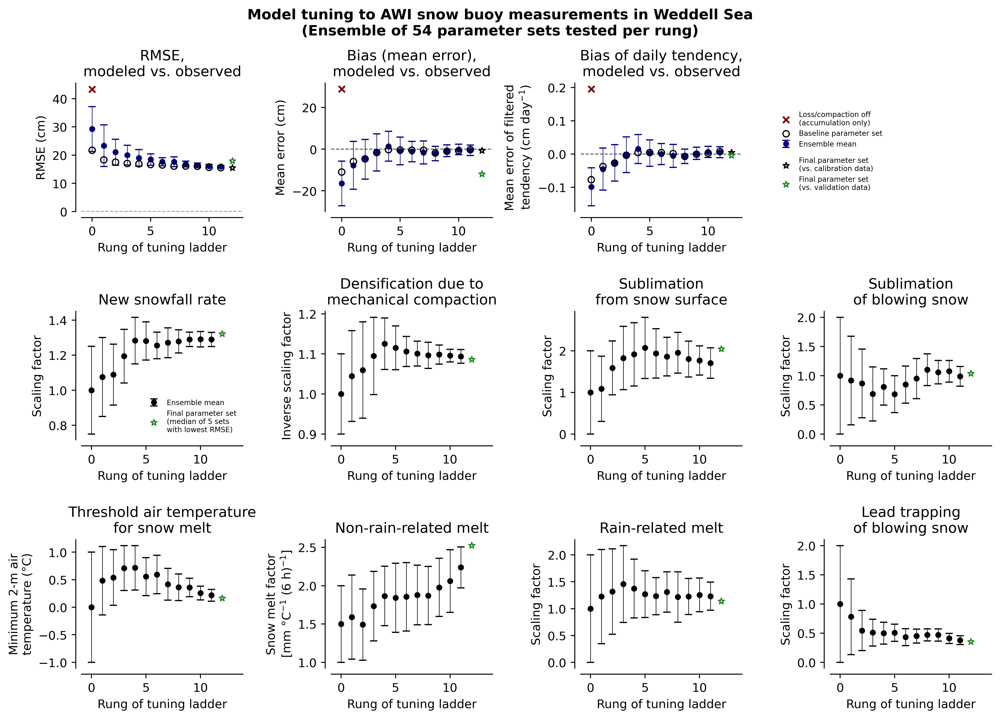

In [32]:
# tuning results plot
# (note: see above for info on final rung selection)

# parameters
n_test_workers = 54   # see above; ensure this is updated
final_rung = 12       # rung whose "best_performers" parameter set will be used for the free-running model integrations

# load data
param_output_filename = 'snow_model_params_tuning.csv'
params_tuning = pd.read_csv(processed_model_output_dir_params + param_output_filename)
params_tuning = params_tuning.loc[:final_rung]

# print final parameter set and its performance metrics
print('Parameters and metrics for final rung (#{0}) + 1 = rung #{1}, where the "best_performers" are stored'.format(final_rung-1,final_rung),
      '\n')
pd.set_option('display.max_rows',70)
display(params_tuning.loc[final_rung])

# illustration of benefit of using median of 5 parameter sets with lowest RMSE, instead of baseline parameter set
print('\n\nComparisons using independent (validation) buoy data set:')
print('Bias for baseline parameter set (cm):',params_tuning.loc[final_rung-1]['bias_baseline_val'])
print('Bias for final parameter set based on "best performers" (cm):',params_tuning.loc[final_rung]['bias_best_performers_val'])
print('RMSE for baseline parameter set (cm):',params_tuning.loc[final_rung-1]['rmse_baseline_val'])
print('RMSE for final parameter set based on "best performers" (cm):',params_tuning.loc[final_rung]['rmse_best_performers_val'])
print('\n')

# load data from rung 0 with two baseline cases
perf_rung0 = pd.read_csv(processed_model_output_dir_params + 'rung0/snow_model_params_perf_rung0.csv')

# plot
fig = plt.figure(figsize=(11.75,8.5),facecolor='w',dpi=400)
plt.suptitle('Model tuning to AWI snow buoy measurements in Weddell Sea\n' + '(Ensemble of {0} parameter sets tested per rung)'.format(n_test_workers),weight='bold')
def perf_subplot(rows,cols,num,param_name,ylabel,title,ylim=[None,None],y_line=None,leg_on=None):
    ax = plt.subplot(rows,cols,num)
    if leg_on == 1: label = 'Loss/compaction off\n(accumulation only)'
    else:           label = None
    plt.scatter(0,perf_rung0.loc[n_test_workers,param_name.replace('bias','mean_error')],s=28,c='maroon',marker='x',zorder=4,
        label=label)  #  the replace() is just due to inconsistent wording for the rung 0 output file
    for rung in range(len(params_tuning)-1):
        if rung == 0 and leg_on == 1: eb_label = 'Ensemble mean'; scat_label = 'Baseline parameter set'
        else:                         eb_label = None;            scat_label = None
        plt.scatter(rung,params_tuning.loc[rung,param_name + '_baseline'],s=28,
                    facecolor='none',edgecolor='k',zorder=4,label=scat_label)
        plt.errorbar(rung,params_tuning.loc[rung,param_name + '_average'],yerr=params_tuning.loc[rung,param_name + '_sigma'],
                     fmt='o',markersize=4,mfc='navy',mec='navy',ecolor='navy',
                     elinewidth=0.5,capsize=3,zorder=3,label=eb_label)
        if rung == (final_rung-1):
            if leg_on == 2: label = 'Final parameter set\n(vs. calibration data)'
            else:           label = None
            plt.scatter(final_rung,params_tuning.loc[rung+1,param_name + '_best_performers'],s=28,marker='*',
                        facecolor='none',edgecolor='k',zorder=4,label=label)
            if leg_on == 2: label = 'Final parameter set\n(vs. validation data)'
            else:           label = None
            plt.scatter(final_rung,params_tuning.loc[rung+1,param_name + '_best_performers_val'],s=28,marker='*',
                        facecolor='none',edgecolor='forestgreen',zorder=4,label=label)  
    plt.xlabel('Rung of tuning ladder')
    plt.ylabel(ylabel)
    plt.title(title)
    plt.xlim([plt.xlim()[0]-0.3,plt.xlim()[1]+0.3])
    if y_line is not None: plt.plot(plt.xlim(),[y_line,y_line],c='0.3',lw=0.75,ls='--',zorder=1)
    plt.ylim(ylim)
    drop_spines()
    if leg_on == 1 or leg_on == 2: return ax
ax2 = perf_subplot(3,4,1,'rmse','RMSE (cm)',
                   'RMSE,\nmodeled vs. observed',ylim=[0.0,None],y_line=0.0,leg_on=1)
ax3 = perf_subplot(3,4,2,'bias','Mean error (cm)',
                   'Bias (mean error),\nmodeled vs. observed',y_line=0.0,leg_on=2)
perf_subplot(3,4,3,'bias_diff','Mean error of filtered\ntendency (cm day$^{-1}$)',
             'Bias of daily tendency,\nmodeled vs. observed',y_line=0.0)
def tuning_subplot(rows,cols,num,param_name,title,ylabel='Scaling factor',scale_density=False,y_line=None,leg_on=False):
    plt.subplot(rows,cols,num)
    for rung in range(len(params_tuning)-1):
        if scale_density:
            yval = params_tuning.loc[rung,param_name] * bulk_snow_rho_0
            yerr = params_tuning.loc[rung,param_name + '_sigma'] * bulk_snow_rho_0
        else:
            yval = params_tuning.loc[rung,param_name]
            yerr = params_tuning.loc[rung,param_name + '_sigma']
        handle1 = plt.errorbar(rung,yval,yerr=yerr,fmt='ko',markersize=4,ecolor='k',elinewidth=0.5,capsize=3)
        if rung == (final_rung-1):
            handle2 = plt.scatter(final_rung,params_tuning.loc[rung+1,param_name + '_best_performers'],s=28,marker='*',
                                  facecolor='none',edgecolor='forestgreen',zorder=4)  
    if leg_on: plt.legend([handle1,handle2],['Ensemble mean','Final parameter set\n(median of 5 sets\nwith lowest RMSE)'],
                          fontsize=6,frameon=False,markerfirst=True,loc='lower right')
    plt.xlabel('Rung of tuning ladder')
    plt.ylabel(ylabel)
    plt.title(title)
    plt.xlim([plt.xlim()[0]-0.3,plt.xlim()[1]+1.3])
    if y_line is not None: plt.plot(plt.xlim(),[y_line,y_line],c='0.3',lw=0.75,ls='--',zorder=1)
    drop_spines()
tuning_subplot(3,4,5,'msr_factor','New snowfall rate',leg_on=True)
tuning_subplot(3,4,6,'compaction_factor','Densification due to\nmechanical compaction',ylabel='Inverse scaling factor')
tuning_subplot(3,4,7,'Q_surf_factor','Sublimation\nfrom snow surface')
tuning_subplot(3,4,8,'Q_sub_factor','Sublimation\nof blowing snow')
tuning_subplot(3,4,9,'melt_threshold_factor','Threshold air temperature\nfor snow melt',ylabel='Minimum 2-m air\ntemperature (°C)')
tuning_subplot(3,4,10,'melt_factor','Non-rain-related melt',ylabel='Snow melt factor\n[mm °C$^{-1}$ (6 h)$^{-1}$]')
tuning_subplot(3,4,11,'rain_factor','Rain-related melt')
tuning_subplot(3,4,12,'Q_ocean_factor','Lead trapping\nof blowing snow')
plt.tight_layout(h_pad=2,w_pad=1)

ax2.legend(fontsize=6,frameon=False,markerfirst=True,loc='lower left',bbox_to_anchor=(0.77,0.78),bbox_transform=fig.transFigure)
ax3.legend(fontsize=6,frameon=False,markerfirst=True,loc='upper left',bbox_to_anchor=(0.77,0.785),bbox_transform=fig.transFigure)

plt.savefig(current_results_dir + 'snow_model_param_tuning.pdf',bbox_inches='tight')

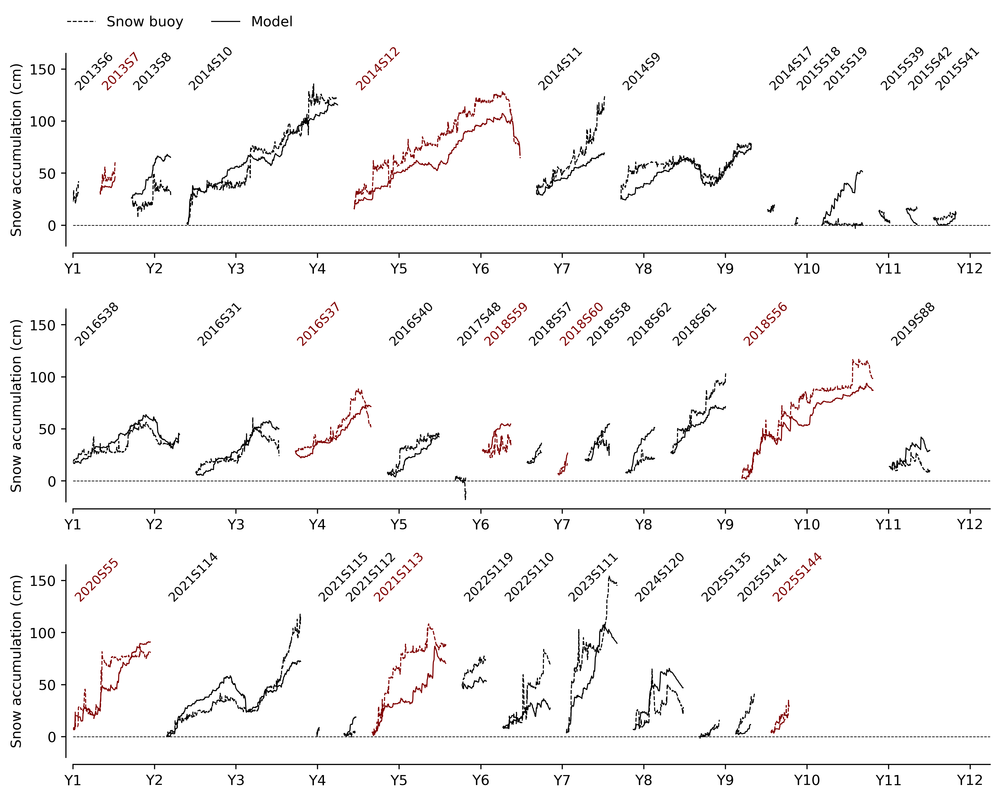

In [18]:
# model vs. snow buoy measurement comparison for final parameter set

# parameters
final_rung = 12           # rung whose baseline parameter set will be used for the free-running model integrations
                          # (i.e., the last rung before the stopping criterion was triggered)
baseline_worker_num = 55
    
# load data
parcels = xr.open_mfdataset(processed_model_output_dir_params + \
                            'rung{0}/snow_model_output_rung{0}_worker{1}_*.nc'.format(final_rung,baseline_worker_num))
parcel_nums = parcels['parcel'].values
parcel_ids = parcels['parcel_id'].values

plt.figure(figsize=(10,8),facecolor='w',dpi=400)
nrows = 3; ncols = 1
current_subplot = 1
current_subplot_timespan = timedelta(days=0)
current_subplot_leftmost_time = datetime(1900,1,1)
# current_subplot_leftmost_time = pd.to_datetime(parcels['time'][0].values)
max_years_per_subplot = 11.25
max_timespan_per_subplot = timedelta(days=365*max_years_per_subplot)
min_timespan_per_buoy = timedelta(days=365/3)
min_time_buffer_between_buoys = timedelta(days=365/5)
def make_subplot(subplot_num):
    plt.subplot(nrows,ncols,current_subplot)
    xlims = [current_subplot_leftmost_time,current_subplot_leftmost_time+max_timespan_per_subplot]
    plt.plot(xlims,[0.0,0.0],lw=0.5,ls='--',c='k',zorder=0)
    plt.xlim(xlims)
    plt.ylim([-20,165])
    drop_spines()
    plt.ylabel('Snow accumulation (cm)')
def buoy_comp_draw(parcel_num,parcel_idx):
    model_parcel = parcels.sel(parcel=parcel_num)['snow_depth'].dropna(dim='time')
    model_initial_snow_depth = model_parcel.isel(time=0).values.item()
    input_parcel = 100 * parcels_input_daily.sel(parcel_id=parcel_ids[parcel_idx])['snow_accum'].dropna(dim='time')
    input_initial_snow_depth = input_parcel.isel(time=0).values.item()
    input_parcel_shifted = input_parcel + (model_initial_snow_depth - input_initial_snow_depth)
    this_line_timespan = timedelta(seconds=(input_parcel_shifted['time'][-1] - input_parcel_shifted['time'][0]).values / timedelta64(1,'s'))
    this_segment_timespan = max(min_timespan_per_buoy,(this_line_timespan+min_time_buffer_between_buoys))
    if parcel_ids[parcel_idx] in buoy_names_training_set: c = 'k'
    else:                                                 c = 'maroon'
    
    this_line_actual_start = pd.to_datetime(input_parcel_shifted['time'][0].values)
    global current_subplot, current_subplot_leftmost_time, current_subplot_timespan
    
    if (current_subplot_timespan + this_segment_timespan) > max_timespan_per_subplot:
        current_subplot += 1
        current_subplot_timespan = timedelta(days=0)
        current_subplot_leftmost_time = datetime(1900,1,1)
        make_subplot(current_subplot)
    
    this_line_shift = (this_line_actual_start - (current_subplot_leftmost_time + current_subplot_timespan))
    plt.plot(pd.to_datetime(model_parcel['time'])-this_line_shift,model_parcel,
             c=c,lw=0.75,ls='-',alpha=1.0,zorder=1)
    plt.plot(pd.to_datetime(input_parcel['time'])-this_line_shift,input_parcel_shifted,
             c=c,lw=0.75,ls='--',alpha=1.0,zorder=2)
    plt.text(current_subplot_leftmost_time+current_subplot_timespan,130,parcel_ids[parcel_idx],
             c=c,fontsize=9,rotation=45)
    current_subplot_timespan += this_segment_timespan

    if parcel_idx == 0:
        invisible_lines = [Line2D([0],[0],lw=0.75,ls='--',color='k',alpha=1.0),
                           Line2D([0],[0],lw=0.75,ls='-',color='k',alpha=1.0)]
        plt.legend(invisible_lines,['Snow buoy','Model'],loc='lower left',bbox_to_anchor=(-0.02,1.06),ncol=2,frameon=False)
    # plt.gca().xaxis.set_major_locator(mdates.YearLocator())
    # plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    plt.gca().set_xticks([datetime(int(yr),1,1) for yr in arange(1900,1900+max_years_per_subplot)])
    plt.gca().set_xticklabels([f"Y{i+1}" for i in arange(int(max_years_per_subplot)+1)])
    
plt.title('AWI snow buoy measurements vs. Lagrangian snow model after tuning')
make_subplot(current_subplot)
for parcel_idx, parcel_num in enumerate(parcel_nums):
    buoy_comp_draw(parcel_num,parcel_idx)
plt.tight_layout()
plt.savefig(current_results_dir + 'parcel_comparison_model_vs_snow_buoys_rung{0}_final_continuous.pdf'.format(final_rung),
            bbox_inches='tight')

/tmp/ipykernel_121481/258239339.py:205: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


NOTE: compare with analysis of this same buoy by Boisvert et al. (2020), Fig. 14


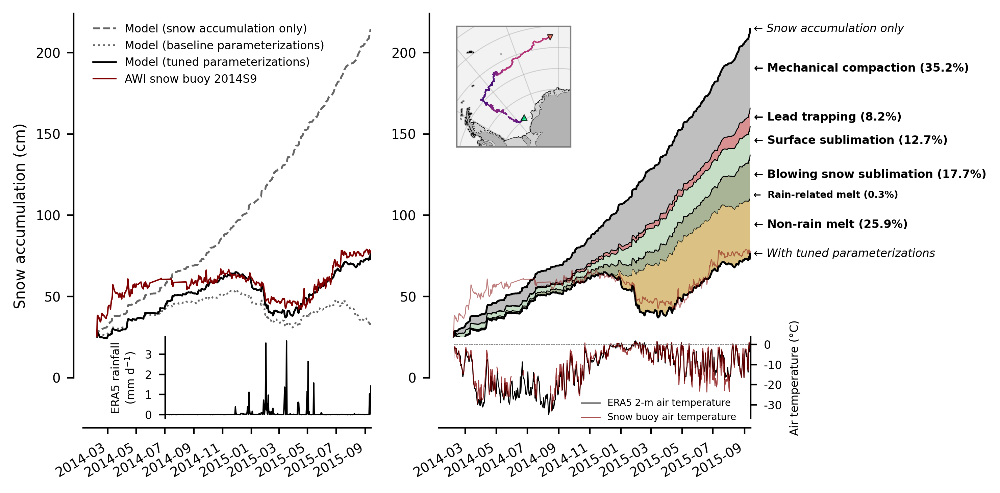

In [36]:
# example of model vs. measurements from snow buoy 2014S9 (including untuned parameter set [priors] and tuned parameter set)
parcel_id = '2014S9'

# parameters
final_rung = 12           # rung whose baseline parameter set will be used for the free-running model integrations
                          # (i.e., the last rung before the stopping criterion was triggered)
baseline_worker_num = 55

# load data
parcels_noloss = xr.open_mfdataset(processed_model_output_dir_params + \
                                   'rung{0}/snow_model_output_rung{0}_worker{1}_*.nc'.format(0,baseline_worker_num-1)).load()
parcels_untuned = xr.open_mfdataset(processed_model_output_dir_params + \
                                   'rung{0}/snow_model_output_rung{0}_worker{1}_*.nc'.format(0,baseline_worker_num)).load()
parcels_final = xr.open_mfdataset(processed_model_output_dir_params + \
                                  'rung{0}/snow_model_output_rung{0}_worker{1}_*.nc'.format(final_rung,baseline_worker_num)).load()
parcel_idx = parcels_final['parcel'][parcels_final['parcel_id'] == parcel_id].item()
era5_daily_rainfall = 1000 * parcels_input_daily.sel(parcel_id=parcel_id)['era5_rain'] * 24 / rho_w   # units: mm d-1
era5_daily_t2m = parcels_input_daily.sel(parcel_id=parcel_id)['era5_t2m']                             # units: °C
buoy_daily_air_temp = parcels_input_daily.sel(parcel_id=parcel_id)['temp_air']                        # units: °C

# scaled snow budget terms
dens_norm = bulk_snow_rho / parcels_final.isel(parcel=parcel_idx)['snow_rho']
no_loss = parcels_noloss.isel(parcel=parcel_idx)['snow_depth']
with_loss = parcels_final.isel(parcel=parcel_idx)['snow_depth']

Q_dens = (parcels_final.isel(parcel=parcel_idx)['Q_dens'] * dens_norm).cumsum()
Q_ocean = (parcels_final.isel(parcel=parcel_idx)['Q_ocean'] * dens_norm).cumsum()
Q_surf = (parcels_final.isel(parcel=parcel_idx)['Q_surf'] * dens_norm).cumsum()
Q_sub = (parcels_final.isel(parcel=parcel_idx)['Q_sub'] * dens_norm).cumsum()
Q_melt_rain = (parcels_final.isel(parcel=parcel_idx)['Q_melt_rain'] * dens_norm).cumsum()
Q_melt_non_rain = (parcels_final.isel(parcel=parcel_idx)['Q_melt_non_rain'] * dens_norm).cumsum()
Q_total = Q_dens + Q_sub + Q_surf + Q_ocean + Q_melt_rain + Q_melt_non_rain
Q_scaling = maximum(0.0,no_loss - with_loss) / Q_total

Q_dens_layer = no_loss - (Q_dens * Q_scaling)
Q_ocean_layer = Q_dens_layer - (Q_ocean * Q_scaling)
Q_surf_layer = Q_ocean_layer - (Q_surf * Q_scaling)
Q_sub_layer = Q_surf_layer - (Q_sub * Q_scaling)
Q_melt_rain_layer = Q_sub_layer - (Q_melt_rain * Q_scaling)
Q_melt_non_rain_layer = Q_melt_rain_layer - (Q_melt_non_rain * Q_scaling)

# plot
fig, axs = plt.subplots(figsize=(7.5,3.75),nrows=1,ncols=2,gridspec_kw=dict(width_ratios=(0.48,0.52)),facecolor='w',dpi=400)

ax1 = axs[0]; plt.axes(ax1)
parcels_noloss.isel(parcel=parcel_idx)['snow_depth'].plot(lw=1.0,c='0.4',ls='--',label='Model (snow accumulation only)')
parcels_untuned.isel(parcel=parcel_idx)['snow_depth'].plot(lw=1.0,c='0.4',ls=':',label='Model (baseline parameterizations)')
parcels_final.isel(parcel=parcel_idx)['snow_depth'].plot(lw=1.0,c='k',label='Model (tuned parameterizations)')
input_parcel = 100 * parcels_input_daily.sel(parcel_id=parcel_id)['snow_accum'].dropna(dim='time')

model_initial_snow_depth = parcels_untuned.isel(parcel=parcel_idx)['snow_depth'].dropna(dim='time').isel(time=0).values.item()
input_initial_snow_depth = input_parcel.isel(time=0).values.item()
input_parcel_shifted = input_parcel + (model_initial_snow_depth - input_initial_snow_depth)
input_parcel_shifted.plot(lw=0.75,c='maroon',label='AWI snow buoy {0}'.format(parcel_id))
plt.xlim([None,pd.to_datetime(input_parcel_shifted['time'][-1].item())])
plt.ylim([-25,None])
ax1.spines['left'].set_bounds(low=0.0,high=plt.ylim()[1])
ax1.tick_params(axis='both',labelsize=7)
plt.legend(frameon=False,loc='upper left',fontsize=6)
plt.ylabel('Snow accumulation (cm)',fontsize=8)
plt.xlabel('')
plt.title('')
drop_spines(ax=ax1)
plt.gcf().autofmt_xdate()

inset1_date_lim = (datetime(2014,7,1),pd.to_datetime(input_parcel_shifted['time'][-1].item()))
ax1_inset = plt.gca().inset_axes([inset1_date_lim[0].timestamp()/60/60/24,-25,
                                  (plt.xlim()[1]-(inset1_date_lim[0].timestamp()/60/60/24)),50],transform=plt.gca().transData)
era5_daily_rainfall_subset = era5_daily_rainfall.sel(time=slice(*inset1_date_lim))
ax1_inset.plot(era5_daily_rainfall_subset['time'],era5_daily_rainfall_subset,lw=0.75,c='k')
ax1_inset.set_xlim(inset1_date_lim)
ax1_inset.set_xticks([])
ax1_inset.set_yticks([0,1,2,3])
ax1_inset.set_yticklabels(labels=ax1_inset.get_yticks(),fontsize=6)
ax1_inset.spines['bottom'].set_visible(False)
ax1_inset.spines['top'].set_visible(False)
ax1_inset.spines['right'].set_visible(False)
ax1_inset.set_ylabel('ERA5 rainfall\n(mm d$^{-1}$)',fontsize=6)

ax2 = axs[1]; plt.axes(ax2)
parcels_noloss.isel(parcel=parcel_idx)['snow_depth'].plot(lw=1.0,c='k',ls='-')
parcels_final.isel(parcel=parcel_idx)['snow_depth'].plot(lw=1.0,c='k')
input_parcel = 100 * parcels_input_daily.sel(parcel_id=parcel_id)['snow_accum'].dropna(dim='time')

model_initial_snow_depth = parcels_untuned.isel(parcel=parcel_idx)['snow_depth'].dropna(dim='time').isel(time=0).values.item()
input_initial_snow_depth = input_parcel.isel(time=0).values.item()
input_parcel_shifted = input_parcel + (model_initial_snow_depth - input_initial_snow_depth)
input_parcel_shifted.plot(lw=0.5,c='maroon',alpha=0.5)
# cc = ['#24492e','#015b58','#2c6184','#59629b','#89689d','#ba7999','#e69b99']
# cc = ['#41476b','#675478','#9e6374','#c67b6f','#de9b71','#efbc82','#fbdfa2'][::-1]
cc = ['0.5','firebrick','darkseagreen','darkolivegreen','gold','darkgoldenrod']
plt.fill_between(Q_dens_layer['time'].values,Q_dens_layer.values,parcels_noloss.isel(parcel=parcel_idx)['snow_depth'].values,
                 color=cc[0],alpha=0.5,lw=0,zorder=0)
Q_dens_layer.plot(c='k',lw=0.5,zorder=1)
plt.fill_between(Q_ocean_layer['time'].values,Q_ocean_layer.values,Q_dens_layer.values,
                 color=cc[1],alpha=0.5,lw=0,zorder=0)
Q_ocean_layer.plot(c='k',lw=0.5,zorder=1)
plt.fill_between(Q_surf_layer['time'].values,Q_surf_layer.values,Q_ocean_layer.values,
                 color=cc[2],alpha=0.5,lw=0,zorder=0)
Q_surf_layer.plot(c='k',lw=0.5,zorder=1)
plt.fill_between(Q_sub_layer['time'].values,Q_sub_layer.values,Q_surf_layer.values,
                 color=cc[3],alpha=0.5,lw=0,zorder=0)
Q_sub_layer.plot(c='k',lw=0.15,zorder=1)
plt.fill_between(Q_melt_rain_layer['time'].values,Q_melt_rain_layer.values,Q_sub_layer.values,
                 color=cc[4],alpha=0.5,lw=0,zorder=0)
Q_melt_rain_layer.plot(c='k',lw=0.15,zorder=1)
plt.fill_between(Q_melt_non_rain_layer['time'].values,Q_melt_non_rain_layer.values,Q_melt_rain_layer.values,
                 color=cc[5],alpha=0.5,lw=0,zorder=0)

inset2_date_lim = (pd.to_datetime(input_parcel_shifted['time'][0].item()),pd.to_datetime(input_parcel_shifted['time'][-1].item()))
last_date = inset2_date_lim[1] - timedelta(days=1)
end_no_loss = parcels_noloss.isel(parcel=parcel_idx).sel(time=last_date)['snow_depth'].item()
end_Q_dens = Q_dens_layer.sel(time=last_date).item()
end_Q_ocean = Q_ocean_layer.sel(time=last_date).item()
end_Q_surf = Q_surf_layer.sel(time=last_date).item()
end_Q_sub = Q_sub_layer.sel(time=last_date).item()
end_Q_melt_rain = Q_melt_rain_layer.sel(time=last_date).item()
end_Q_melt_non_rain = Q_melt_non_rain_layer.sel(time=last_date).item()
end_span = (end_no_loss - end_Q_melt_non_rain)
plt.text(last_date,end_no_loss,' ← Snow accumulation only',style='italic',va='center',size=6)
plt.text(last_date,end_Q_dens + (0.5 * (end_no_loss - end_Q_dens)),
         ' ← Mechanical compaction ({0:.1f}%)'.format(100 * (end_no_loss - end_Q_dens) / end_span),
         weight='bold',va='center',size=6)
plt.text(last_date,end_Q_ocean + (0.5 * (end_Q_dens - end_Q_ocean)),
         ' ← Lead trapping ({0:.1f}%)'.format(100 * (end_Q_dens - end_Q_ocean) / end_span),
         weight='bold',va='center',size=6)
plt.text(last_date,end_Q_surf + (0.5 * (end_Q_ocean - end_Q_surf)),
         ' ← Surface sublimation ({0:.1f}%)'.format(100 * (end_Q_ocean - end_Q_surf) / end_span),
         weight='bold',va='center',size=6)
plt.text(last_date,end_Q_sub + (0.5 * (end_Q_surf - end_Q_sub)),
         ' ← Blowing snow sublimation ({0:.1f}%)'.format(100 * (end_Q_surf - end_Q_sub) / end_span),
         weight='bold',va='center',size=6)
plt.text(last_date,end_Q_melt_rain + (0.5 * (end_Q_sub - end_Q_melt_rain)),
         ' ←  Rain-related melt ({0:.1f}%)'.format(100 * (end_Q_sub - end_Q_melt_rain) / end_span),
         weight='bold',va='center',size=5)
plt.text(last_date,end_Q_melt_non_rain + (0.5 * (end_Q_melt_rain - end_Q_melt_non_rain)),
         ' ← Non-rain melt ({0:.1f}%)'.format(100 * (end_Q_melt_rain - end_Q_melt_non_rain) / end_span),
         weight='bold',va='center',size=6)
plt.text(last_date,end_Q_melt_non_rain,' ← With tuned parameterizations',style='italic',va='center',size=6)

plt.xlim([None,pd.to_datetime(input_parcel_shifted['time'][-1].item())])
plt.ylim([-25,None])
ax2.spines['left'].set_bounds(low=0.0,high=plt.ylim()[1])
ax2.tick_params(axis='both',labelsize=7)
plt.xlabel('')
plt.ylabel('')
plt.title('')
drop_spines(ax=ax2)
plt.gcf().autofmt_xdate()

ax2_inset = plt.gca().inset_axes([inset2_date_lim[0].timestamp()/60/60/24,-25,
                                  (plt.xlim()[1]-(inset2_date_lim[0].timestamp()/60/60/24)),50],transform=plt.gca().transData)
era5_daily_t2m_subset = era5_daily_t2m.sel(time=slice(*inset2_date_lim))
buoy_daily_air_temp_subset = buoy_daily_air_temp.sel(time=slice(*inset2_date_lim))
ax2_inset.plot(era5_daily_t2m_subset['time'],era5_daily_t2m_subset,lw=0.5,c='k',label='ERA5 2-m air temperature')
ax2_inset.plot(buoy_daily_air_temp_subset['time'],buoy_daily_air_temp_subset,lw=0.5,c='maroon',alpha=0.75,label='Snow buoy air temperature')
ax2_inset.plot(inset2_date_lim,[0.0,0.0],lw=0.25,ls='--',c='0.4')
ax2_inset.set_xlim(inset2_date_lim)
ax2_inset.set_xticks([])
ax2_inset.yaxis.tick_right()
ax2_inset.set_yticks([-30,-20,-10,0])
ax2_inset.set_yticklabels(labels=ax2_inset.get_yticks(),fontsize=6)
ax2_inset.spines['bottom'].set_visible(False)
ax2_inset.spines['top'].set_visible(False)
ax2_inset.spines['left'].set_visible(False)
ax2_inset.yaxis.set_label_position('right')
ax2_inset.set_ylabel('Air temperature (°C)',fontsize=6)
ax2_inset.legend(frameon=False,loc='lower right',bbox_to_anchor=(0.98,-0.15),fontsize=5)

# inset map showing buoy 2014S9 trajectory
inset_map_rel_position = [-0.23,0.73,0.35,0.35]  # [left, bottom, width, height] in ax2 coords
inset_map_position = ax2.get_position()  # get bbox of ax2 in figure coords
inset_left = inset_map_position.x0 + inset_map_rel_position[0] * inset_map_position.width
inset_bottom = inset_map_position.y0 + inset_map_rel_position[1] * inset_map_position.height
inset_width = inset_map_rel_position[2] * inset_map_position.width
inset_height = inset_map_rel_position[3] * inset_map_position.height
ax2_map = fig.add_axes([inset_left,inset_bottom,inset_width,inset_height],
                       projection=ccrs.SouthPolarStereo(central_longitude=0)) # add Cartopy inset to the figure, relative to ax2
ax2_map.set_extent([-45,5,-82,-55],crs=ccrs.PlateCarree())
gl = ax2_map.gridlines(crs=ccrs.PlateCarree(),draw_labels=False,linewidth=0.5,alpha=0.5)
ax2_map.add_feature(cfeature.OCEAN.with_scale('50m'),color='0.95',zorder=1)
ax2_map.add_feature(cfeature.LAND.with_scale('50m'),color='0.7',zorder=2)
ax2_map.coastlines(resolution='50m',linewidth=0.25,zorder=3)
ice_shelves = cartopy.feature.NaturalEarthFeature('physical','antarctic_ice_shelves_polys','50m')
ice_shelves_lines = cartopy.feature.NaturalEarthFeature('physical','antarctic_ice_shelves_lines','50m')
ax2_map.add_feature(ice_shelves,facecolor='0.825',edgecolor='none',zorder=4)
ax2_map.add_feature(ice_shelves_lines,facecolor='none',edgecolor='k',linestyle='-',linewidth=0.25,zorder=5)
sct = plt.scatter(buoy_data['2014S9']['longitude (deg)'].values,buoy_data['2014S9']['latitude (deg)'].values,
                  c=buoy_data['2014S9']['distance_to_initial_snow_interface'].values,vmin=0.0,vmax=1.2,
                  cmap='magma',s=0.5,linewidths=0,transform=ccrs.PlateCarree(),zorder=4)
first_valid_time = buoy_data['2014S9']['distance_to_initial_snow_interface'].dropna(dim='time')['time'][0].values
last_valid_time = buoy_data['2014S9']['distance_to_initial_snow_interface'].dropna(dim='time')['time'][-1].values
plt.scatter(buoy_data['2014S9']['longitude (deg)'].sel(time=first_valid_time).values,
            buoy_data['2014S9']['latitude (deg)'].sel(time=first_valid_time).values,
            s=10,marker='^',c='springgreen',edgecolors='k',linewidths=0.5,alpha=0.75,transform=ccrs.PlateCarree(),zorder=6)
plt.scatter(buoy_data['2014S9']['longitude (deg)'].sel(time=last_valid_time).values,
            buoy_data['2014S9']['latitude (deg)'].sel(time=last_valid_time).values,
            s=8,marker='v',c='tomato',edgecolors='k',linewidths=0.5,alpha=0.75,transform=ccrs.PlateCarree(),zorder=6)
for spine in ax2_map.spines.values():
    spine.set_visible(True)
    spine.set_edgecolor('0.5')
    spine.set_linewidth(0.75)
    spine.set_zorder(10)

plt.tight_layout()
# plt.suptitle('Weddell Sea snow buoy {0} vs. model with snow mass budget'.format(parcel_id),y=1.02)
plt.savefig(current_results_dir + 'example_buoy_{0}_vs_model_final.pdf'.format(parcel_id),bbox_inches='tight')

Final simulated snow depth (cm): 76.36355832277529
Final superimposed ice thickness (cm): 32.164327186411526
Final superimposed ice thickness, as fraction of snow depth: 0.42119995313024294


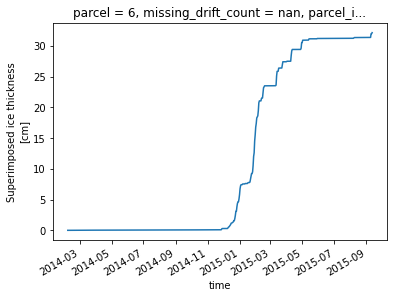

In [38]:
# Superimposed ice evolution for snow buoy 2014S9
print('Final simulated snow depth (cm):',parcels_final.isel(parcel=parcel_idx)['snow_depth'].dropna(dim='time')[-1].item())
print('Superimposed ice thickness (cm) on 1/31/15:',parcels_final.isel(parcel=parcel_idx)['si_depth'].sel(time='2015-01-31').item())
print('Final superimposed ice thickness (cm):',parcels_final.isel(parcel=parcel_idx)['si_depth'].max().item())
print('Final superimposed ice thickness, as fraction of snow depth:',parcels_final.isel(parcel=parcel_idx)['si_depth'].max().item() / 
                                                                     parcels_final.isel(parcel=parcel_idx)['snow_depth'].dropna(dim='time')[-1].item())
parcels_final.isel(parcel=parcel_idx)['si_depth'].plot();

### Model output parcel-based visuals

>>> 2025-06-01 15:50:08.219634 - action is 0.0% complete
>>> 2025-06-01 15:50:35.890600 - action is 10.0% complete
>>> 2025-06-01 15:50:54.112981 - action is 20.0% complete
>>> 2025-06-01 15:51:07.462420 - action is 30.0% complete
>>> 2025-06-01 15:51:17.289570 - action is 40.0% complete
>>> 2025-06-01 15:51:25.626820 - action is 50.0% complete
>>> 2025-06-01 15:51:30.894236 - action is 60.0% complete
>>> 2025-06-01 15:51:35.079263 - action is 70.0% complete
>>> 2025-06-01 15:51:37.470294 - action is 80.0% complete
>>> 2025-06-01 15:51:38.623156 - action is 90.0% complete


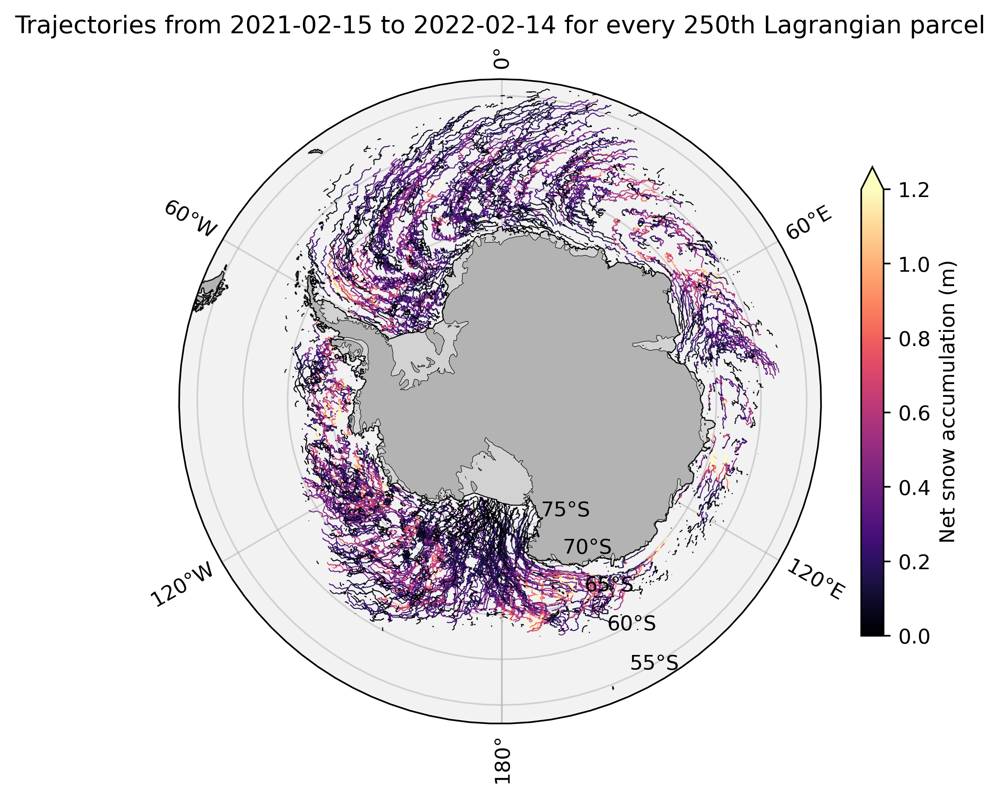

In [104]:
# Lagrangian parcel trajectories
# - runtime: ~5 mins

# import model output files from 2021-2022 (7 GB; takes ~3 mins)
import_one_year = True
start_year = 2021   # 2021-2022 model run
if import_one_year:
    parcels_one_year = xr.open_mfdataset(processed_model_output_dir + '{0}/'.format(start_year) + '*.nc')

# generate plot
parcel_skip = 250    # plot every 250th parcel
fig = plt.figure(figsize=(7,7),facecolor='w',dpi=400)
ax = plt.axes(projection=ccrs.SouthPolarStereo(central_longitude=0))
plt.gca().set_extent([-180,180,-90,-53],crs=ccrs.PlateCarree())
plt.gca().set_boundary(map_circle_boundary(),transform=plt.gca().transAxes)
plt.gca().add_feature(cfeature.OCEAN.with_scale('50m'),color='0.95',zorder=1)
plt.gca().add_feature(cfeature.LAND.with_scale('50m'),color='0.7',zorder=2)
plt.gca().coastlines(resolution='50m',linewidth=0.5,zorder=3)
ice_shelves = cartopy.feature.NaturalEarthFeature('physical','antarctic_ice_shelves_polys','50m')
ice_shelves_lines = cartopy.feature.NaturalEarthFeature('physical','antarctic_ice_shelves_lines','50m')
plt.gca().add_feature(ice_shelves,facecolor='0.825',edgecolor='none',zorder=4)
plt.gca().add_feature(ice_shelves_lines,facecolor='none',edgecolor='k',linestyle='-',linewidth=0.5,zorder=5)
gl = plt.gca().gridlines(crs=ccrs.PlateCarree(),draw_labels=True,ylim=[-75,-50],alpha=0.5)  # zorder = 2 and cannot be changed
# for ea in gl.label_artists: ea.set_zorder(8)   # zorder works erratically for Cartopy gridlines and gridline labels
parcel_nums_subsetted = parcels_one_year['parcel'].values[::parcel_skip]
parcel_lats_all = parcels_one_year['lat'].sel(parcel=parcel_nums_subsetted).values
parcel_lons_all = parcels_one_year['lon'].sel(parcel=parcel_nums_subsetted).values
parcel_snow_depth_all = parcels_one_year['snow_depth'].sel(parcel=parcel_nums_subsetted).values
for p_idx, parcel_num in enumerate(parcel_nums_subsetted):
    parcel_lats = parcel_lats_all[p_idx,:][~isnan(parcel_lats_all[p_idx,:])]
    parcel_lons = parcel_lons_all[p_idx,:][~isnan(parcel_lons_all[p_idx,:])]
    parcel_snow_depth = parcel_snow_depth_all[p_idx,:][~isnan(parcel_snow_depth_all[p_idx,:])] / 100
    if sum(parcel_lons < -120) > 0 and sum(parcel_lons > 120) > 0:   # prevent artifacts from parcels crossing -180/180° longitude
        parcel_lons[parcel_lons < 0] += 360
    all_points = array([parcel_lons,parcel_lats]).T.reshape(-1,1,2)
    segments = concatenate([all_points[:-1],all_points[1:]],axis=1)
    lc = mcol.LineCollection(segments,cmap='magma',norm=plt.Normalize(0,1.2),transform=ccrs.PlateCarree(),zorder=3)
    lc.set_array(parcel_snow_depth)
    lc.set_linewidth(0.5)
    line = plt.gca().add_collection(lc)
    df.how_far(p_idx,parcel_nums_subsetted,0.1)
plt.colorbar(line,label='Net snow accumulation (m)',shrink=0.60,extend='max')
plt.title('Trajectories from {0} to {1} for every {2}th Lagrangian parcel'.format(pd.to_datetime(parcels_one_year['time'].isel(time=0).values).date(),
                                                                                  pd.to_datetime(parcels_one_year['time'].isel(time=-1).values).date(),
                                                                                  parcel_skip));
plt.savefig(current_results_dir + 'parcel_trajectories_{0}_{1}.jpg'.format(start_year,start_year+1),bbox_inches='tight')

In [90]:
# calculate demo of Voronoi tesselation to obtain parcel cell area for one day of model output

# import model run (7 GB; takes ~3 mins for each year)
parcels_new_test = xr.open_mfdataset(processed_model_output_dir + '{0}/'.format(2021) + '*.nc')

# load SIC and model parcel data
sic = xr.open_dataset(sic_regridded_dir + '{0}-{1:02}-{2:02}.nc'.format(2021,8,15))
parcel_subset = parcels_new_test.sel(time='2021-08-15')

timer_start = time.time()

# create labeled sea ice grid, where open ocean is 0 and contiguous sea ice regions are 1, 2, 3, etc.
labeled_feature_grid, num_features = ndimage.label(sic['sic_regridded'] > 0,
                                                   structure=array([[1, 1, 1], [1, 1, 1], [1, 1, 1]]))

# find outlines of labeled sea ice regions, then convert into Shapely objects (Polygons)
all_shapes = []
for this_shape, this_value in features.shapes(labeled_feature_grid,connectivity=8):
    if this_value > 0: all_shapes.append(this_shape)
for shape_idx in range(len(all_shapes)):
    coord_idx_array = array(all_shapes[shape_idx]['coordinates'][0])
    x_coords = coord_idx_array[:,0].astype(int)
    y_coords = coord_idx_array[:,1].astype(int)
    x_coords_to_lons = era5_lon_edge_west[x_coords]
    y_coords_to_lats = flip(era5_lat_edge_south)[y_coords]
    all_shapes[shape_idx]['coordinates'] = dstack([x_coords_to_lons,y_coords_to_lats])
all_sea_ice_polygons = MultiPolygon([geomshape(s) for s in all_shapes])
sic_gdf = gpd.GeoDataFrame(geometry=list(all_sea_ice_polygons.geoms),crs='EPSG:4326')
sic_gdf = sic_gdf.to_crs('EPSG:3031')  # reproject to Antarctic polar stereographic projection (use EPSG:3413 for Arctic)

# extract parcel locations and reproject to a projection that "wraps" around -180°/180°
these_parcel_coords = column_stack((parcel_subset['lon'].dropna(dim='parcel'),
                                    parcel_subset['lat'].dropna(dim='parcel')))
parcel_gdf = gpd.GeoDataFrame(geometry=points(these_parcel_coords),crs='EPSG:4326')  # plate carrée projection
parcel_gdf_proj = parcel_gdf.to_crs('EPSG:3031')  # reproject to Antarctic polar stereographic projection (use EPSG:3413 for Arctic)
parcel_coords_ps = array([[geom.x,geom.y] for geom in parcel_gdf_proj.geometry])
parcel_nums = parcel_subset['lon'].dropna(dim='parcel')['parcel'].values

# create Voronoi diagram (in polar stereographic projected space)
vor = Voronoi(parcel_coords_ps)
valid_regions = array([-1 not in ri for ri in vor.regions])
voronoi_polygons = [Polygon([vor.vertices[i] for i in ri]) \
                    for ri in array(vor.regions,dtype=object)[valid_regions]]
voronoi_polygons_parcel_idx = [where(vor.point_region == idx)[0] \
                               for idx in where(valid_regions)[0]]
voronoi_polygons_parcel_num = [parcel_nums[par_idx] \
                               for par_idx in voronoi_polygons_parcel_idx]

# convert the Voronoi polygons to a GeoDataFrame
voronoi_gdf = gpd.GeoDataFrame(geometry=voronoi_polygons,crs='EPSG:3031')

# remove any invalid geometries
not_empty_mask = ~voronoi_gdf.is_empty
voronoi_gdf = voronoi_gdf[not_empty_mask]
voronoi_polygons_parcel_idx = array(voronoi_polygons_parcel_idx,dtype=object)[not_empty_mask]
voronoi_polygons_parcel_num = array(voronoi_polygons_parcel_num,dtype=object)[not_empty_mask]

# fix handful of invalid geometries
for invalid_idx in where(~voronoi_gdf.is_valid)[0]:
    voronoi_gdf.iloc[invalid_idx] = make_valid(voronoi_gdf.iloc[invalid_idx].geometry)

# clip Voronoi polygons to SIC boundaries
voronoi_gdf_clipped = gpd.clip(voronoi_gdf,sic_gdf)   # this step takes the most processing time
voronoi_gdf_clipped_parcel_idx = voronoi_polygons_parcel_idx[voronoi_gdf_clipped.index - 1]
voronoi_gdf_clipped_parcel_num = voronoi_polygons_parcel_num[voronoi_gdf_clipped.index - 1]

# calculate area of polygons after re-projecting
voronoi_gdf_clipped_areas = voronoi_gdf_clipped.area / 10**6  # units: km^2

# extract parcel areas
parcel_areas = pd.DataFrame(index=array([parcel_num[0] for parcel_num in voronoi_gdf_clipped_parcel_num]),
                            data=voronoi_gdf_clipped_areas.values)

# additional items not in Lagrangian model code above
timer_end = time.time()
print('>> elapsed time: {0:.1f} s'.format(timer_end - timer_start))
voronoi_gdf_clipped['area'] = voronoi_gdf_clipped_areas
voronoi_gdf_clipped['parcel_num'] = voronoi_gdf_clipped_parcel_num.astype(int)
voronoi_gdf_clipped_new = voronoi_gdf_clipped.copy()

>> elapsed time: 93.5 s


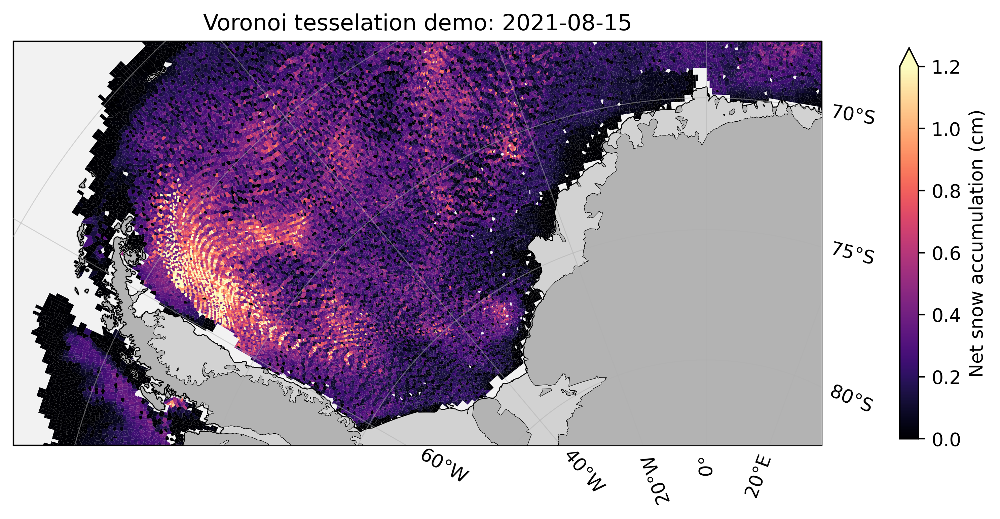

In [120]:
# Voronoi tesselation demo, focused on Weddell Sea

# remove polygons that cross the dateline, which show as streaks
subset_new = voronoi_gdf_clipped_new.to_crs('EPSG:4326')
bounds = subset_new.bounds
lon_span = bounds['maxx'] - bounds['minx']
subset_new = subset_new[lon_span <= 180]

# clip to region of interest (no longer necessary, but keep code for reference)
# subset_new = subset_new[subset_new.intersects(roi)]
# subset_new = subset_new.clip(subset_new,roi)

# tidy up polygons
subset_new = subset_new[~subset_new.geometry.is_empty & subset_new.geometry.notnull() & subset_new.is_valid]

# change projection to avoid issues with plotting GeoDataFrame polygons using default Cartopy plate carrée transform
south_polar_crs = ccrs.SouthPolarStereo(central_longitude=0).proj4_init
subset_new = subset_new.to_crs(south_polar_crs)

# match snow depth on Voronoi parcels
parcel_num_roi = subset_new['parcel_num'].values.copy()
subset_new['snow_depth'] = (parcel_subset.sel(parcel=parcel_num_roi)['snow_depth'].values * 0.01)

# plot
plt.figure(figsize=(10.0,5.5),facecolor='w',dpi=400)
plt.axes(projection=ccrs.SouthPolarStereo(central_longitude=0.0))
plt.gca().set_extent([-3000000,500000,750000,2500000],crs=ccrs.SouthPolarStereo())
gl = plt.gca().gridlines(crs=ccrs.PlateCarree(),draw_labels={"bottom":"x","right":"y"},lw=0.5,alpha=0.5,zorder=7)
# gl.right_labels = True
# gl.right_labels = True
gl.y_inline = False
plt.gca().add_feature(cfeature.OCEAN.with_scale('10m'),color='0.95',zorder=1)
plt.gca().add_feature(cfeature.LAND.with_scale('10m'),color='0.7',zorder=3)
plt.gca().coastlines(resolution='10m',linewidth=0.5,zorder=4)
ice_shelves = cartopy.feature.NaturalEarthFeature('physical','antarctic_ice_shelves_polys','10m')
ice_shelves_lines = cartopy.feature.NaturalEarthFeature('physical','antarctic_ice_shelves_lines','10m')
plt.gca().add_feature(ice_shelves,facecolor='0.825',edgecolor='none',zorder=5)
plt.gca().add_feature(ice_shelves_lines,facecolor='none',edgecolor='k',linestyle='-',linewidth=0.5,zorder=6)
subset_new.plot('snow_depth',ax=plt.gca(),legend=True,vmin=0.0,vmax=1.2,cmap='magma',zorder=2,
                legend_kwds={'shrink':0.7,'label':'Net snow accumulation (cm)','extend':'max','pad':0.075});
plt.title('Voronoi tesselation demo: {0}-{1:02}-{2:02}'.format(2021,8,15))
plt.savefig(current_results_dir + 'voronoi_snow_depth_map_demo.jpg',bbox_inches='tight')

### Model output processing and analysis

In [51]:
# 1. import model output files (<parcels>), one year at a time
# 2. bin snow depths, density, and gain/loss terms from all available model output time steps, accounting for parcel area
# 3. export binned gridded fields to netCDF files

# parameters
coarsen = 3   # coarseness of binning grid to use compared to ERA5 grid

# coarsen ERA5 grid of grid cell areas to match binned model output
era5_grid_areas_coarse = era5_grid_areas['area'].coarsen(lon=coarsen,boundary='trim').sum().coarsen(lat=coarsen,boundary='trim').sum()

# helper function to bin quantities from Lagrangian model parcels
def bin_parcels(this_parcels,param,coarsen,long_name,units,comment=None,intrinsic=False):
    numerator = xrhist(this_parcels['lon'],this_parcels['lat'],
                       bins=[era5_lon_edge_west[::coarsen],era5_lat_edge_south[::-1*coarsen][::-1]],
                       weights=this_parcels[param].fillna(0.0) * this_parcels['parcel_area'],
                       dim=['parcel'])
    denominator = xrhist(this_parcels['lon'],this_parcels['lat'],
                     bins=[era5_lon_edge_west[::coarsen],era5_lat_edge_south[::-1*coarsen][::-1]],
                     weights=this_parcels['parcel_area'],
                     dim=['parcel'])
    no_parcel_mask = (denominator == 0.0).T.isel(lat_bin=slice(None,None,-1)).rename({'lat_bin':'lat','lon_bin':'lon'})
    if intrinsic:
        # if an intrinsic quantity (i.e., snow bulk density), bin without using TOTAL_PARCEL_AREA within each grid cell as a scaling factor
        binned_param = (numerator / denominator)
    elif not intrinsic:
        # if an extrinsic quantity (i.e., snow depth, Q-fluxes), scale by TOTAL_PARCEL_AREA/ERA5_GRID_CELL_AREA to conserve snow volume/mass
        #   because, e.g., Q-fluxes are in cm/d over the current parcel area (in km^2) and in later analyses get multiplied by ERA5_GRID_CELL_AREA
        #   to obtain a total volume flux
        # NOTE: the expression below is simplied from: binned_param = (numerator / denominator) * (denominator / era5_grid_areas_coarse)
        binned_param = (numerator / era5_grid_areas_coarse.rename({'lat':'lat_bin','lon':'lon_bin'}))
    binned_param = binned_param.T.isel(lat_bin=slice(None,None,-1))                                # transpose and flip latitude axis
    binned_param = binned_param.rename({'lat_bin':'lat','lon_bin':'lon'}).rename(param)            # rename coords and overall variable
    binned_param = binned_param.where(~no_parcel_mask,nan)                                         # mask non-sea ice grid cells to NaN
    if type(comment) == str:
        binned_param = binned_param.assign_attrs(long_name=long_name,units=units,comment=comment)  # add metadata: long name, units, and optional comment
    else:
        binned_param = binned_param.assign_attrs(long_name=long_name,units=units)
    return binned_param

for start_year in arange(2003,2024+1):
    print('>>> Working on year {0}'.format(start_year))
    with ProgressBar():
        # import model run (7 GB; takes ~3 mins for each year)
        parcels_this_year = xr.open_mfdataset(processed_model_output_dir + '{0}/'.format(start_year) + '*.nc')
        with warnings.catch_warnings():
            warnings.simplefilter('ignore')  # ignore division-by-zero warning
            bin_parcels(parcels_this_year,'snow_depth',coarsen,
                        'Net snow accumulation on sea ice','cm',
                        comment='Does not account for loss from snow-ice conversion').compute()\
                .to_netcdf(processed_model_output_dir + 'snow_depth_{0}.nc'.format(start_year))
            bin_parcels(parcels_this_year,'snow_rho',coarsen,
                        'Bulk snow density on sea ice','kg m^-3',intrinsic=True).compute()\
                .to_netcdf(processed_model_output_dir + 'snow_rho_{0}.nc'.format(start_year))
            bin_parcels(parcels_this_year,'si_depth',coarsen,
                        'Superimposed ice thickness','cm',
                        comment=f'Superimposed ice density rho_si = {rho_si:.0f} kg m^-3').compute()\
                .to_netcdf(processed_model_output_dir + 'si_depth_{0}.nc'.format(start_year))
            bin_parcels(parcels_this_year,'Q_new',coarsen,
                        'New snowfall on sea ice','cm d^-1',
                        comment=f'Normalized to bulk snow density rho_s0 = {bulk_snow_rho:.0f} kg m^-3').compute()\
                .to_netcdf(processed_model_output_dir + 'Q_new_{0}.nc'.format(start_year))
            bin_parcels(parcels_this_year,'Q_dens',coarsen,
                        'Decrease in snow depth due to mechanical compaction','cm d^-1',
                        comment=f'Positive = compaction; normalized to bulk snow density rho_s0 = {bulk_snow_rho:.0f} kg m^-3').compute()\
                .to_netcdf(processed_model_output_dir + 'Q_dens_{0}.nc'.format(start_year))
            bin_parcels(parcels_this_year,'Q_melt_rain',coarsen,
                        'Rain-related snow melt','cm d^-1',
                        comment=f'Positive = loss; normalized to bulk snow density rho_s0 = {bulk_snow_rho:.0f} kg m^-3').compute()\
                .to_netcdf(processed_model_output_dir + 'Q_melt_rain_{0}.nc'.format(start_year))
            bin_parcels(parcels_this_year,'Q_melt_non_rain',coarsen,
                        'Non-rain-related snow melt','cm d^-1',
                        comment=f'Positive = loss; normalized to bulk snow density rho_s0 = {bulk_snow_rho:.0f} kg m^-3').compute()\
                .to_netcdf(processed_model_output_dir + 'Q_melt_non_rain_{0}.nc'.format(start_year))
            bin_parcels(parcels_this_year,'Q_con_div',coarsen,
                        'Snow depth change due to sea ice convergence and divergence','cm d^-1',
                        comment=f'Positive = increase in thickness; normalized to bulk snow density rho_s0 = {bulk_snow_rho:.0f} kg m^-3').compute()\
                .to_netcdf(processed_model_output_dir + 'Q_con_div_{0}.nc'.format(start_year))
            bin_parcels(parcels_this_year,'Q_surf',coarsen,
                        'Snow surface sublimation','cm d^-1',
                        comment=f'Positive = loss to atmosphere; normalized to bulk snow density rho_s0 = {bulk_snow_rho:.0f} kg m^-3').compute()\
                .to_netcdf(processed_model_output_dir + 'Q_surf_{0}.nc'.format(start_year))
            bin_parcels(parcels_this_year,'Q_sub',coarsen,
                        'Blowing snow sublimation','cm d^-1',
                        comment=f'Positive = loss to atmosphere; normalized to bulk snow density rho_s0 = {bulk_snow_rho:.0f} kg m^-3').compute()\
                .to_netcdf(processed_model_output_dir + 'Q_sub_{0}.nc'.format(start_year))
            bin_parcels(parcels_this_year,'Q_ocean',coarsen,
                        'Lead trapping of blowing snow','cm d^-1',
                        comment=f'Positive = loss to ocean; normalized to bulk snow density rho_s0 = {bulk_snow_rho:.0f} kg m^-3').compute()\
                .to_netcdf(processed_model_output_dir + 'Q_ocean_{0}.nc'.format(start_year))
            parcels_this_year_geo_to_ocean = parcels_this_year.copy()       # replace NaN parcel lat/lon with recorded lat/lon of ice melt
            parcels_this_year_geo_to_ocean['lon'] = parcels_this_year['lon'].where(parcels_this_year['snow_to_ocean_lon'].isnull(),parcels_this_year['snow_to_ocean_lon'])
            parcels_this_year_geo_to_ocean['lat'] = parcels_this_year['lat'].where(parcels_this_year['snow_to_ocean_lon'].isnull(),parcels_this_year['snow_to_ocean_lat'])
            bin_parcels(parcels_this_year_geo_to_ocean,'snow_to_ocean',coarsen,
                        'Snow and snow-ice released to ocean upon sea ice melt','cm d^-1',
                        comment=f'Positive = loss to ocean; normalized to bulk snow density rho_s0 = {bulk_snow_rho:.0f} kg m^-3').compute()\
                .to_netcdf(processed_model_output_dir + 'snow_to_ocean_{0}.nc'.format(start_year))
            bin_parcels(parcels_this_year_geo_to_ocean,'si_to_ocean',coarsen,
                        'Superimposed ice released to ocean upon sea ice melt','cm d^-1',
                        comment=f'Positive = loss to ocean; normalized to bulk snow density rho_s0 = {bulk_snow_rho:.0f} kg m^-3').compute()\
                .to_netcdf(processed_model_output_dir + 'si_to_ocean_{0}.nc'.format(start_year))

>>> Working on year 2003
[########################################] | 100% Completed | 102.56 ms
[########################################] | 100% Completed | 101.15 ms
[########################################] | 100% Completed | 6.27 sms
[########################################] | 100% Completed | 6.14 sms
[########################################] | 100% Completed | 6.01 sms
[########################################] | 100% Completed | 6.51 sms
[########################################] | 100% Completed | 6.19 sms
[########################################] | 100% Completed | 6.02 sms
[########################################] | 100% Completed | 5.71 sms
[########################################] | 100% Completed | 5.29 sms
[########################################] | 100% Completed | 5.44 sms
[########################################] | 100% Completed | 5.37 sms
[########################################] | 100% Completed | 5.41 sms
[########################################] | 100% 

In [52]:
# calculate annual mean snow budget terms

# create directory for combined data
dir_items = os.listdir(processed_model_output_dir)
if 'Gridded_all_years' not in dir_items: os.mkdir(processed_model_output_dir + 'Gridded_all_years/')

# specify time range to limit data import to
time_range = [datetime(2003,2,15),datetime(2025,2,14)]

# function to load multiple years of data and export to single combined file
# - note: will not overwrite the combined files if they already exist
# - FIXME: in the future, this could also delete the individual years' files, which are duplicative, but I have kept them for faster I/O when plotting 
def load_and_export(var_name):
    binned_data_all_years = xr.open_mfdataset(processed_model_output_dir + f'{var_name}_*.nc')
    dir_items = os.listdir(processed_model_output_dir + 'Gridded_all_years/')
    if f'{var_name}.nc' not in dir_items:
        binned_data_all_years.to_netcdf(processed_model_output_dir + f'Gridded_all_years/{var_name}.nc')
    return binned_data_all_years[var_name].sel(time=slice(*time_range))

# load and export gridded data
binned_snow_depth = load_and_export('snow_depth')
binned_snow_rho = load_and_export('snow_rho')
binned_si_depth = load_and_export('si_depth')
binned_Q_new = load_and_export('Q_new')
binned_Q_dens = load_and_export('Q_dens')
binned_Q_melt_rain = load_and_export('Q_melt_rain')
binned_Q_melt_non_rain = load_and_export('Q_melt_non_rain')
binned_Q_con_div = load_and_export('Q_con_div')
binned_Q_surf = load_and_export('Q_surf')
binned_Q_sub = load_and_export('Q_sub')
binned_Q_ocean = load_and_export('Q_ocean')
binned_snow_to_ocean = load_and_export('snow_to_ocean')
binned_si_to_ocean = load_and_export('si_to_ocean')

In [159]:
# calculate seasonal climatologies (by day of year = DOY) of snow budget terms over entire Antarctic SIZ

# first coarsen ERA5 grid of grid cell areas to match binned model output
coarsen = 3
era5_grid_areas_coarse = era5_grid_areas['area'].coarsen(lon=coarsen,boundary='trim').sum().coarsen(lat=coarsen,boundary='trim').sum()

def rei(series_in):
    # reindex time series from dayofyear (with DOY 1 = Feb. 15) to datetime (using arbitrary year of 1900)
    series_out = series_in.copy()
    series_out['dayofyear'] = datetime64('1900-02-14') + array([timedelta64(doy,'D') for doy in series_out['dayofyear'].values])
    return series_out

def doy_siz_total(data_in,compute_mean_not_std=True):
    # returns: model period daily-average SIZ-total snow flux (units: kg snow), by shifted day of year (where Feb. 15 is DOY 1)
    daily_total_kg = (data_in * bulk_snow_rho * era5_grid_areas_coarse * (10**4)).sum(dim=['lon','lat'])
    if compute_mean_not_std: shifted_doy_mean = daily_total_kg.groupby((data_in['time']-timedelta64(45,'D')).dt.dayofyear).mean().compute()
    else:                    shifted_doy_mean = daily_total_kg.groupby((data_in['time']-timedelta64(45,'D')).dt.dayofyear).std().compute()
    return shifted_doy_mean

def prep_line(series_in,factor=1):
    return rei((factor * series_in * 10**-12).rolling(dayofyear=7,center=True,min_periods=1).mean())
   
# interannual means
Q_new_doy_siz_total = doy_siz_total(binned_Q_new)
Q_melt_rain_doy_siz_total = doy_siz_total(binned_Q_melt_rain)
Q_melt_non_rain_doy_siz_total = doy_siz_total(binned_Q_melt_non_rain)
Q_surf_doy_siz_total = doy_siz_total(binned_Q_surf)
Q_sub_doy_siz_total = doy_siz_total(binned_Q_sub)
Q_ocean_doy_siz_total = doy_siz_total(binned_Q_ocean)
snow_to_ocean_doy_siz_total = doy_siz_total(binned_snow_to_ocean)

# interannual standard deviations
Q_new_doy_siz_std = doy_siz_total(binned_Q_new,compute_mean_not_std=False)
snow_to_ocean_doy_siz_std = doy_siz_total(binned_snow_to_ocean,compute_mean_not_std=False)

# interannual standard deviations of cumulative sums
Q_new_daily_total_kg = (binned_Q_new * bulk_snow_rho * era5_grid_areas_coarse * (10**4)).sum(dim=['lon','lat'])
Q_new_daily_total_kg['year'] = (Q_new_daily_total_kg['time'] - timedelta64(45,'D')).dt.year
Q_new_daily_cumsum = Q_new_daily_total_kg.groupby('year').map(lambda x: x.cumsum(dim='time')) * 10**-12
Q_new_cumsum_std = Q_new_daily_cumsum.groupby((Q_new_daily_cumsum['time']-timedelta64(45,'D')).dt.dayofyear).std().compute()

snow_to_ocean_daily_total_kg = (binned_snow_to_ocean * bulk_snow_rho * era5_grid_areas_coarse * (10**4)).sum(dim=['lon','lat'])
snow_to_ocean_daily_total_kg['year'] = (snow_to_ocean_daily_total_kg['time'] - timedelta64(45,'D')).dt.year
snow_to_ocean_daily_cumsum = snow_to_ocean_daily_total_kg.groupby('year').map(lambda x: x.cumsum(dim='time')) * 10**-12
snow_to_ocean_cumsum_std = snow_to_ocean_daily_cumsum.groupby((snow_to_ocean_daily_cumsum['time']-timedelta64(45,'D')).dt.dayofyear).std().compute()

In [161]:
print('Maximum interannual standard deviation of Q_new during annual cycle = {0} Pg d-1'.format((Q_new_doy_siz_std * 10**-12).max().item()))
print('Maximum interannual standard deviation of snow_to_ocean during annual cycle = {0} Pg d-1'.format((snow_to_ocean_doy_siz_std * 10**-12).max().item()))

Maximum interannual standard deviation of Q_new during annual cycle = 11.277543098873753 Pg d-1
Maximum interannual standard deviation of snow_to_ocean during annual cycle = 24.361825937041782 Pg d-1


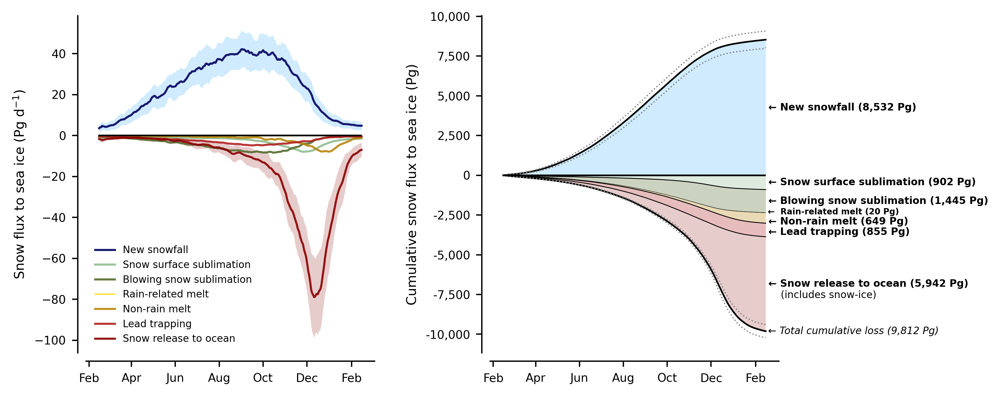

In [357]:
fig, axs = plt.subplots(figsize=(7.5,3.75),nrows=1,ncols=2,gridspec_kw=dict(wspace=0.4,width_ratios=(0.5,0.5)),facecolor='w',dpi=400)
cc = ['midnightblue','darkseagreen','darkolivegreen','gold','darkgoldenrod','firebrick','darkred']
labels = ['New snowfall','Snow surface sublimation','Blowing snow sublimation','Rain-related melt','Non-rain melt',
          'Lead trapping','Snow release to ocean']
y_offset = [0,0,0,50,-225,-135,0]

# seasonal climatologies
ax1 = axs[0]; plt.axes(ax1)
prep_line(Q_new_doy_siz_total).plot(c=cc[0],lw=1.25,label=labels[0],zorder=1)
plt.fill_between(prep_line(Q_new_doy_siz_std)['dayofyear'].values,
                 prep_line(Q_new_doy_siz_total).values - prep_line(Q_new_doy_siz_std).values,
                 prep_line(Q_new_doy_siz_total).values + prep_line(Q_new_doy_siz_std).values,
                 color='lightskyblue',alpha=0.4,lw=0,zorder=0)
plt.plot([datetime(1900,2,15),datetime(1901,2,14)],[0,0],ls='-',lw=1.0,c='k')
prep_line(Q_surf_doy_siz_total,factor=-1).plot(c=cc[1],lw=1.25,alpha=0.9,label=labels[1],zorder=1)
prep_line(Q_sub_doy_siz_total,factor=-1).plot(c=cc[2],lw=1.25,alpha=0.9,label=labels[2],zorder=1)
prep_line(Q_melt_rain_doy_siz_total,factor=-1).plot(c=cc[3],lw=0.75,alpha=0.9,label=labels[3],zorder=1)
prep_line(Q_melt_non_rain_doy_siz_total,factor=-1).plot(c=cc[4],lw=1.25,alpha=0.9,label=labels[4],zorder=1)
prep_line(Q_ocean_doy_siz_total,factor=-1).plot(c=cc[5],lw=1.25,alpha=0.9,label=labels[5],zorder=1)
prep_line(snow_to_ocean_doy_siz_total,factor=-1).plot(c=cc[6],lw=1.25,alpha=0.9,label=labels[6],zorder=1)
plt.fill_between(prep_line(snow_to_ocean_doy_siz_std)['dayofyear'].values,
                 prep_line(-1 * snow_to_ocean_doy_siz_total).values - prep_line(snow_to_ocean_doy_siz_std).values,
                 prep_line(-1 * snow_to_ocean_doy_siz_total).values + prep_line(snow_to_ocean_doy_siz_std).values,
                 color=cc[6],alpha=0.2,lw=0,zorder=0)
plt.legend(frameon=False,loc='lower left',fontsize=6)
mo_loc = mdates.MonthLocator(interval=2)
plt.gca().xaxis.set_major_locator(mo_loc)
mo_fmt = mdates.DateFormatter('%b')
plt.gca().xaxis.set_major_formatter(mo_fmt)
ax1.tick_params(axis='both',labelsize=7)
plt.xlabel('')
plt.ylabel('Snow flux to sea ice (Pg d$^{-1}$)',fontsize=8)
drop_spines(ax=ax1)

# cumulative sums by day-of-year
Q_new_line = (Q_new_doy_siz_total.cumsum() * 10**-12)  # units: Pg cumulative snow
Q_surf_line = ((-1 * Q_surf_doy_siz_total).cumsum() * 10**-12)
Q_sub_line = Q_surf_line + ((-1 * Q_sub_doy_siz_total).cumsum() * 10**-12)
Q_melt_rain_line = Q_sub_line + ((-1 * Q_melt_rain_doy_siz_total).cumsum() * 10**-12)
Q_melt_non_rain_line = Q_melt_rain_line + ((-1 * Q_melt_non_rain_doy_siz_total).cumsum() * 10**-12)
Q_ocean_line = Q_melt_non_rain_line + ((-1 * Q_ocean_doy_siz_total).cumsum() * 10**-12)
snow_to_ocean_line = Q_ocean_line + ((-1 * snow_to_ocean_doy_siz_total).cumsum() * 10**-12)

last_doy = 366
end_Q_new = Q_new_line.sel(dayofyear=last_doy).item()
end_Q_surf = Q_surf_line.sel(dayofyear=last_doy).item()
end_Q_sub = Q_sub_line.sel(dayofyear=last_doy).item()
end_Q_melt_rain = Q_melt_rain_line.sel(dayofyear=last_doy).item()
end_Q_melt_non_rain = Q_melt_non_rain_line.sel(dayofyear=last_doy).item()
end_Q_ocean = Q_ocean_line.sel(dayofyear=last_doy).item()
end_snow_to_ocean = snow_to_ocean_line.sel(dayofyear=last_doy).item()

ax2 = axs[1]; plt.axes(ax2)
rei(Q_new_line).plot(c='k',lw=1.0,zorder=1)
plt.fill_between(rei(Q_new_line)['dayofyear'].values,Q_new_line.values,0.0,
                 color='lightskyblue',alpha=0.4,lw=0,zorder=0)
rei(Q_new_line + Q_new_cumsum_std).plot(c='0.5',ls=':',lw=0.75,zorder=1)
rei(Q_new_line - Q_new_cumsum_std).plot(c='0.5',ls=':',lw=0.75,zorder=1)
plt.plot([datetime(1900,2,15),datetime(1901,2,14)],[0,0],ls='-',lw=1.0,c='k')
plt.fill_between(rei(Q_surf_line)['dayofyear'].values,0.0,Q_surf_line.values,
                 color=cc[1],alpha=0.3,lw=0,zorder=0)
rei(Q_surf_line).plot(c='k',lw=0.5,zorder=1)
plt.fill_between(rei(Q_sub_line)['dayofyear'].values,Q_surf_line.values,Q_sub_line.values,
                 color=cc[2],alpha=0.3,lw=0,zorder=0)
rei(Q_sub_line).plot(c='k',lw=0.15,zorder=1)
plt.fill_between(rei(Q_melt_rain_line)['dayofyear'].values,Q_sub_line.values,Q_melt_rain_line.values,
                 color=cc[3],alpha=0.3,lw=0,zorder=0)
rei(Q_melt_rain_line).plot(c='k',lw=0.15,zorder=1)
plt.fill_between(rei(Q_melt_non_rain_line)['dayofyear'].values,Q_melt_rain_line.values,Q_melt_non_rain_line.values,
                 color=cc[4],alpha=0.3,lw=0,zorder=0)
rei(Q_melt_non_rain_line).plot(c='k',lw=0.5,zorder=1)
plt.fill_between(rei(Q_ocean_line)['dayofyear'].values,Q_melt_non_rain_line.values,Q_ocean_line.values,
                 color=cc[5],alpha=0.3,lw=0,zorder=0)
rei(Q_ocean_line).plot(c='k',lw=0.5,zorder=1)
plt.fill_between(rei(snow_to_ocean_line)['dayofyear'].values,Q_ocean_line.values,snow_to_ocean_line.values,
                 color=cc[6],alpha=0.2,lw=0,zorder=0)
rei(snow_to_ocean_line).plot(c='k',lw=1.0,zorder=1)
rei(snow_to_ocean_line + snow_to_ocean_cumsum_std).plot(c='0.5',ls=':',lw=0.75,zorder=1)
rei(snow_to_ocean_line - snow_to_ocean_cumsum_std).plot(c='0.5',ls=':',lw=0.75,zorder=1)

last_date = datetime(1901,2,14)
plt.text(last_date,0.0 + (0.5 * (end_Q_new - 0.0)) + y_offset[0],
         ' ← {0} ({1:,.0f} Pg)'.format(labels[0],end_Q_new - 0.0),
         weight='bold',va='center',size=6)
plt.text(last_date,0.0 - (0.5 * (0.0 - end_Q_surf)) + y_offset[1],
         ' ← {0} ({1:,.0f} Pg)'.format(labels[1],0.0 - end_Q_surf),
         weight='bold',va='center',size=6)
plt.text(last_date,end_Q_surf - (0.5 * (end_Q_surf - end_Q_sub)) + y_offset[2],
         ' ← {0} ({1:,.0f} Pg)'.format(labels[2],end_Q_surf - end_Q_sub),
         weight='bold',va='center',size=6)
plt.text(last_date,end_Q_sub - (0.5 * (end_Q_sub - end_Q_melt_rain)) + y_offset[3],
         ' ←  {0} ({1:,.0f} Pg)'.format(labels[3],end_Q_sub - end_Q_melt_rain),
         weight='bold',va='center',size=5)
plt.text(last_date,end_Q_melt_rain - (0.5 * (end_Q_melt_rain - end_Q_melt_non_rain)) + y_offset[4],
         ' ← {0} ({1:,.0f} Pg)'.format(labels[4],end_Q_melt_rain - end_Q_melt_non_rain),
         weight='bold',va='center',size=6)
plt.text(last_date,end_Q_melt_non_rain - (0.5 * (end_Q_melt_non_rain - end_Q_ocean)) + y_offset[5],
         ' ← {0} ({1:,.0f} Pg)'.format(labels[5],end_Q_melt_non_rain - end_Q_ocean),
         weight='bold',va='center',size=6)
plt.text(last_date,end_Q_ocean - (0.5 * (end_Q_ocean - end_snow_to_ocean)) + y_offset[6],
         ' ← {0} ({1:,.0f} Pg)'.format(labels[6],end_Q_ocean - end_snow_to_ocean),
         weight='bold',va='center',size=6)
plt.text(last_date,end_Q_ocean - (0.5 * (end_Q_ocean - end_snow_to_ocean)) + y_offset[6] - 700,
         '     (includes snow-ice)',
         va='center',size=6)
plt.text(last_date,end_snow_to_ocean,
         ' ← Total cumulative loss ({0:,.0f} Pg)'.format(-1*end_snow_to_ocean),
         style='italic',va='center',size=6)

plt.gca().xaxis.set_major_locator(mo_loc)
plt.gca().xaxis.set_major_formatter(mo_fmt)
plt.gca().yaxis.set_major_formatter(mtick.FuncFormatter(lambda y, p: format(int(y), ',')))
ax2.tick_params(axis='both',labelsize=7)
plt.xlabel('')
plt.ylabel('Cumulative snow flux to sea ice (Pg)',fontsize=8)
drop_spines(ax=ax2)

plt.savefig(current_results_dir + 'antarctic_siz_snow_budget.pdf',bbox_inches='tight')

In [44]:
# calculate total annual freshwater fluxes in Sverdrups (1 mSv = 1,000 m3 s−1)
last_doy = 366
Q_new_total = ((Q_new_doy_siz_total).cumsum() * 10**-12).sel(dayofyear=last_doy).item()
Q_ocean_total = ((Q_ocean_doy_siz_total).cumsum() * 10**-12).sel(dayofyear=last_doy).item()
Q_surf_total = ((Q_surf_doy_siz_total).cumsum() * 10**-12).sel(dayofyear=last_doy).item()
Q_sub_total = ((Q_sub_doy_siz_total).cumsum() * 10**-12).sel(dayofyear=last_doy).item()
Q_melt_rain_total = ((Q_melt_rain_doy_siz_total).cumsum() * 10**-12).sel(dayofyear=last_doy).item()
Q_melt_non_rain_total = ((Q_melt_non_rain_doy_siz_total).cumsum() * 10**-12).sel(dayofyear=last_doy).item()
snow_to_ocean_total = ((snow_to_ocean_doy_siz_total).cumsum() * 10**-12).sel(dayofyear=last_doy).item()
Pg_per_yr_to_mSv = 1e12 / (3.156e7 * 1e3 * 1e3)
print('Annual total new snowfall intercepted on sea ice, using model estimate (units: mSv = 1,000 m3 s-1) =',
      Q_new_total * Pg_per_yr_to_mSv)
print('Annual total new snowfall intercepted on sea ice, using loss term for a balanced budget (units: mSv = 1,000 m3 s-1) =',
      (Q_ocean_total + Q_surf_total + Q_sub_total + Q_melt_rain_total + Q_melt_non_rain_total + snow_to_ocean_total) * Pg_per_yr_to_mSv)
print('Annual total lead trapping (units: mSv) =',
      Q_ocean_total * Pg_per_yr_to_mSv)
print('Annual total snow release to ocean upon ice melt (units: mSv) =',
      snow_to_ocean_total * Pg_per_yr_to_mSv)
print('Annual total superimposed ice release to ocean upon ice melt (units: mSv) =',
      (Q_melt_rain_total + Q_melt_non_rain_total) * Pg_per_yr_to_mSv)
print('Annual total TO OCEAN (mSv) =',
      (snow_to_ocean_total + Q_ocean_total + Q_melt_rain_total + Q_melt_non_rain_total) * Pg_per_yr_to_mSv)

Annual total new snowfall intercepted on sea ice, using model estimate (units: mSv = 1,000 m3 s-1) = 270.3382266976464
Annual total new snowfall intercepted on sea ice, using loss term for a balanced budget (units: mSv = 1,000 m3 s-1) = 310.88840047210226
Annual total lead trapping (units: mSv) = 27.078626178482338
Annual total snow release to ocean upon ice melt (units: mSv) = 188.26292998121446
Annual total superimposed ice release to ocean upon ice melt (units: mSv) = 21.19188702931845
Annual total TO OCEAN (mSv) = 236.53344318901523


NOTE: blue indicates new snowfall; yellow-pink and blue-grey indicate compaction or changes due to large-scale ice dynamics; green indicates loss to the atmosphere; orange indicates snow melt, superimposed ice formation, and eventual loss to the ocean; red indicates loss directly to the ocean


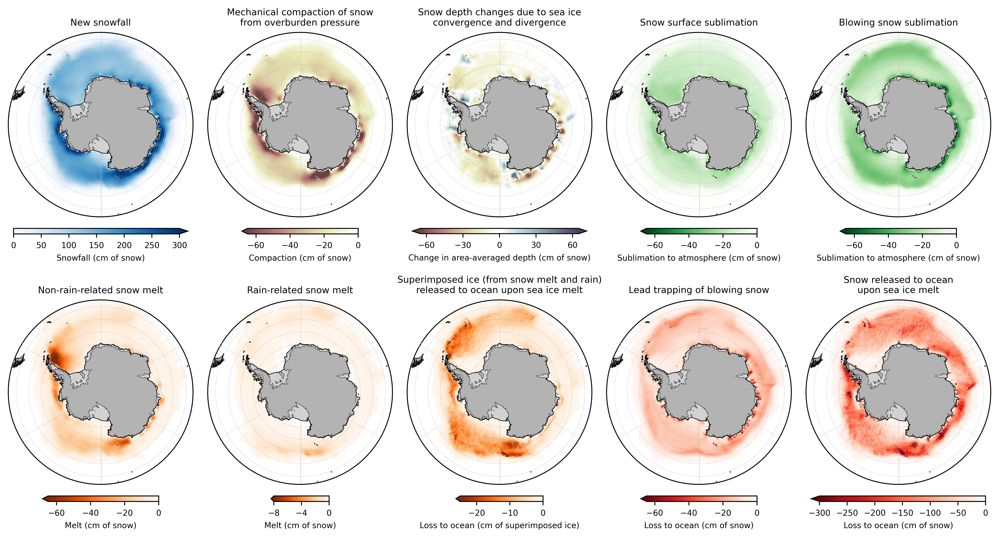

In [46]:
# plot annual average budget term totals

N_years = round((time_range[1] - time_range[0]) / timedelta(days=365))

# modify and create colormaps
cmap_masked_blue = copy.copy(matplotlib.colormaps['Blues'])
cmap_masked_blue.set_bad(alpha=0.0)
cmap_masked_red = copy.copy(matplotlib.colormaps['Reds_r'])
cmap_masked_red.set_bad(alpha=0.0)
cmap_masked_orange = copy.copy(matplotlib.colormaps['Oranges_r'])
cmap_masked_orange.set_bad(alpha=0.0)
cmap_masked_green = copy.copy(matplotlib.colormaps['Greens_r'])
cmap_masked_green.set_bad(alpha=0.0)
cmap_masked_pink = copy.copy(mcolors.LinearSegmentedColormap.from_list('pink',plt.cm.pink(linspace(0.1,1.0,128))))
cmap_masked_pink.set_bad(alpha=0.0)
colors1 = plt.cm.pink(linspace(0.1,1.0,128))
colors2 = plt.cm.bone_r(linspace(0.0,0.7,128))
colors_merged = vstack((colors1,colors2))
cmap_pink_bluegrey = mcolors.LinearSegmentedColormap.from_list('pink_bluegrey',colors_merged)

plot_params = [[binned_Q_new.sum(dim='time') / N_years,
                'New snowfall','Snowfall (cm of snow)',[0,300],'max',cmap_masked_blue,None,0.9],
               [-1 * binned_Q_dens.sum(dim='time') / N_years,
                'Mechanical compaction of snow\nfrom overburden pressure','Compaction (cm of snow)',
                [-65,0],'min',cmap_masked_pink,None,0.6],
               [binned_Q_con_div.sum(dim='time') / N_years,
                'Snow depth changes due to sea ice\nconvergence and divergence','Change in area-averaged depth (cm of snow)',
                [-65,65],'both',cmap_pink_bluegrey,[-60,-30,0,30,60],0.9],
               [-1 * binned_Q_surf.sum(dim='time') / N_years,
                'Snow surface sublimation','Sublimation to atmosphere (cm of snow)',
                [-65,0],'min',cmap_masked_green,None,0.6],
               [-1 * binned_Q_sub.sum(dim='time') / N_years,
                'Blowing snow sublimation','Sublimation to atmosphere (cm of snow)',
                [-65,0],'min',cmap_masked_green,None,0.6],
               [-1 * binned_Q_melt_non_rain.sum(dim='time') / N_years,
                'Non-rain-related snow melt','Melt (cm of snow)',
                [-65,0],'min',cmap_masked_orange,None,0.6],
               [-1 * binned_Q_melt_rain.sum(dim='time') / N_years,
                'Rain-related snow melt','Melt (cm of snow)',
                [-8,0],'min',cmap_masked_orange,[-8,-4,0],0.3],
               [-1 * binned_si_to_ocean.sum(dim='time') / N_years,
                'Superimposed ice (from snow melt and rain)\nreleased to ocean upon sea ice melt','Loss to ocean (cm of superimposed ice)',
                [-25,0],'min',cmap_masked_orange,[-20,-10,0],0.45],
               [-1 * binned_Q_ocean.sum(dim='time') / N_years,
                'Lead trapping of blowing snow','Loss to ocean (cm of snow)',
                [-65,0],'min',cmap_masked_red,None,0.6],
               [-1 * binned_snow_to_ocean.sum(dim='time') / N_years,
                'Snow released to ocean\nupon sea ice melt','Loss to ocean (cm of snow)',
                [-300,0],'min',cmap_masked_red,None,0.9]]

nrows = 2; ncols = 5; figsize = (15.5,8)
fig, axs = plt.subplots(nrows=nrows,ncols=ncols,subplot_kw={'projection':ccrs.SouthPolarStereo(central_longitude=0)},
                        gridspec_kw=dict(wspace=0.03,hspace=0.16),figsize=figsize,facecolor='w',dpi=400)
axs = axs.flatten()
for plot_idx in range(len(plot_params)):
    if plot_params[plot_idx][0] is None:  # remove unused map axes (no longer needed; keeping here for future reference)
        axs[plot_idx].axis('off')
        continue
    data_to_plot = plot_params[plot_idx][0]
    data_to_plot = data_to_plot.where(data_to_plot != 0.0,nan)  # mask out regions of 0.0 values
    axs[plot_idx].set_extent([-180,180,-90,-52],crs=ccrs.PlateCarree())
    axs[plot_idx].set_boundary(map_circle_boundary(),transform=axs[plot_idx].transAxes)
    axs[plot_idx].add_feature(cfeature.OCEAN.with_scale('50m'),color='w',zorder=1)  # or '0.95'
    pcm = axs[plot_idx].pcolormesh(data_to_plot['lon'],data_to_plot['lat'],data_to_plot.values,
                                   vmin=plot_params[plot_idx][3][0],vmax=plot_params[plot_idx][3][1],
                                   cmap=plot_params[plot_idx][5],shading='auto',
                                   transform=ccrs.PlateCarree(),zorder=2)
    axs[plot_idx].add_feature(cfeature.LAND.with_scale('50m'),color='0.7',zorder=4)
    axs[plot_idx].coastlines(resolution='50m',linewidth=0.5,zorder=5)
    ice_shelves = cartopy.feature.NaturalEarthFeature('physical','antarctic_ice_shelves_polys','50m')
    ice_shelves_lines = cartopy.feature.NaturalEarthFeature('physical','antarctic_ice_shelves_lines','50m')
    axs[plot_idx].add_feature(ice_shelves,facecolor='0.825',edgecolor='none',zorder=6)
    axs[plot_idx].add_feature(ice_shelves_lines,facecolor='none',edgecolor='k',linestyle='-',linewidth=0.5,zorder=7)
    axs[plot_idx].gridlines(crs=ccrs.PlateCarree(),linewidth=0.5,draw_labels=False,alpha=0.3)
    axs[plot_idx].set_title(plot_params[plot_idx][1],fontsize=8,y=1.0)
    cbar = plt.colorbar(pcm,ax=axs[plot_idx],shrink=plot_params[plot_idx][7],aspect=20*plot_params[plot_idx][7]/0.6,
                        pad=0.05,extend=plot_params[plot_idx][4],orientation='horizontal',ticks=plot_params[plot_idx][6])
    cbar.ax.tick_params(labelsize=7)
    cbar.set_label(plot_params[plot_idx][2],size=7)
    
plt.savefig(current_results_dir + 'snow_model_budget_terms_annual.jpg',bbox_inches='tight')

print('NOTE: blue indicates new snowfall; yellow-pink and blue-grey indicate compaction or changes due to large-scale ice dynamics; ' + \
      'green indicates loss to the atmosphere; orange indicates snow melt, superimposed ice formation, and eventual loss to the ocean; ' + \
      'red indicates loss directly to the ocean')

In [47]:
# load CryoSat-2 snow depth on sea ice estimates from Fons et al. (2023) [The Cryosphere]
#   then calculate monthly climatology and regrid to ERA5 grid
# - data downloaded from: https://zenodo.org/record/7327711
# - note: NaNs *not* filled with zeros before averaging in time due to large swaths of grid cells with missing data within SIZ in first year of record
#         (locations that should not be misrepresented as having zero snow depth when averaging in time)
fons = xr.open_mfdataset(ice_thickness_dir + 'Fons_2023_CryoSat2/*.nc')
fons_climo = fons['snow_depth'].groupby(fons['time'].dt.month).mean('time')
fons_climo = fons_climo * 100  # convert m to cm
cryosat2_grid_fons_in = xr.Dataset({'lat':(['y','x'],fons['lat'].isel(time=1).data.copy()),
                                    'lon':(['y','x'],fons['lon'].isel(time=1).data.copy())})
cryosat2_fons_era5_regridder = xesmf.Regridder(cryosat2_grid_fons_in,era5_grid_out,'bilinear')
fons_climo_era5_grid = cryosat2_fons_era5_regridder(fons_climo)

In [ ]:
# compute and export AMSR snow depth monthly averages (2003-2025)
# - runtime: approx. 20 mins (loading daily data using xarray/Dask) + 45 minutes per monthly average = approx. 10 hours in total
# - note: created Python script to run this using nohup because of the long time to complete, hence imports/filepaths below; e.g.:
#   >>> nohup python3 -u "/dat1/ethancc/Git/Analyses/TEMP_amsr_process.py" > "/dat1/ethancc/Data/Snow on sea ice/AMSR_monthly_means/nohup_TEMP_amsr_process.out" 2>&1 &
# - note: NaNs *not* filled with zeros before averaging in time due to patches of grid cells with missing data within SIZ throughout the record
#         (locations that should not be misrepresented as having zero snow depth when averaging in time)

### code to include if putting this routine in a separate Python script:
# from numpy import *
# import xarray as xr
# from datetime import datetime
# data_dir = '/dat1/ethancc/Data/'
# snow_on_ice_dir = data_dir + 'Snow on sea ice/'
# amsr_snow_on_ice_dir = snow_on_ice_dir + 'AMSR_all/'
# amsr_monthly_snow_on_ice_dir = snow_on_ice_dir + 'AMSR_monthly_means/'

time_range = [datetime(2003,2,15),datetime(2025,2,14)]
amsr_snow_depth_all = xr.open_mfdataset(amsr_snow_on_ice_dir + 'nsidc_amsr_sh_snow_depth*.nc') # removed, unsure why added originally: mode='r'
amsr_snow_depth_all = amsr_snow_depth_all.sel(time=slice(*time_range))

for month in arange(1,12+1):
    print('>>> Working on loading AMSR snow depth for month {0} and exporting mean...'.format(month))
    amsr_month_mean = amsr_snow_depth_all.sel(time=(amsr_snow_depth_all['time'].dt.month == month)).mean(dim='time').compute()
    filename = 'nsidc_amsr_sh_snow_depth_{0}_to_{1}_mean_month_{2}.nc'.format(time_range[0].date(),time_range[1].date(),month)
    amsr_month_mean.to_netcdf(amsr_monthly_snow_on_ice_dir + filename)

In [48]:
# compute AMSR averages over seasonal groupings of months
def preprocess_add_month(input_ds):
    filename = input_ds.encoding['source']
    month = int(filename.split('.')[0].split('_')[-1])
    return input_ds.assign_coords({'month':month})
amsr_snow_depth_monthly_means = xr.open_mfdataset(amsr_monthly_snow_on_ice_dir + '*.nc',preprocess=preprocess_add_month,
                                                  concat_dim='month',combine='nested')
month_groups = [[3,4,5],[6,7,8],[9,10,11],[12,1]]
amsr_snow_depth_by_month_group = []
for months in month_groups:
    print('>>> Working on months {0}...'.format(months))
    amsr_month_group_mean = amsr_snow_depth_monthly_means.sel(month=amsr_snow_depth_monthly_means['month'].isin(months)).fillna(0.0).mean(dim='month').compute()
    amsr_month_group_mean = amsr_month_group_mean.where(amsr_month_group_mean != 0.0,nan)   # after averaging zero-filled fields in time, convert zeros back to NaNs
    amsr_snow_depth_by_month_group.append(amsr_month_group_mean)

>>> Working on months [3, 4, 5]...
>>> Working on months [6, 7, 8]...
>>> Working on months [9, 10, 11]...
>>> Working on months [12, 1]...


Plotting column 0...
Plotting column 1...
Plotting column 2...
Plotting column 3...
NOTE: positive differences in model minus CryoSat-2 largely indicate snow-ice formation
NOTE: CryoSat-2 monthly snow depth data for July 2010 through August 2021 is from Fons et al., 2023
NOTE: time range for daily AMSR-E/2 snow depth data: 2003-02-15 00:00:00 to 2025-02-14 00:00:00


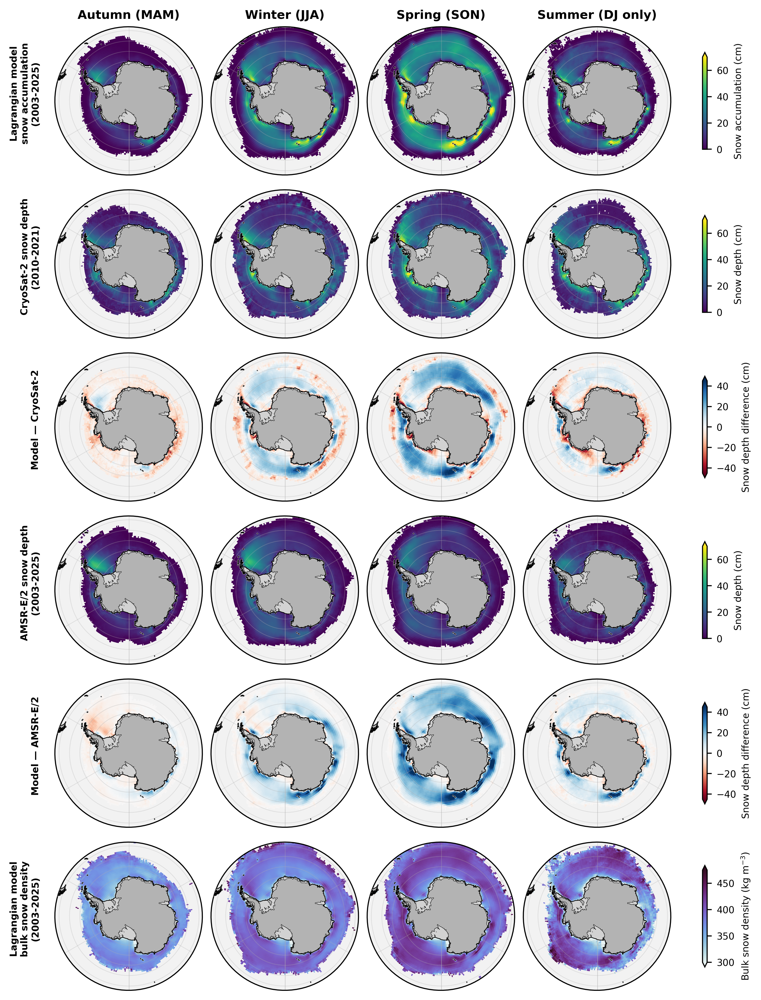

In [309]:
# comparison plots of autumn (M-A-M) / winter (J-J-A) / spring (S-O-N) / summer (D-J) simulated, AMSR-E/2, and CryoSat-2 snow depth

# main parameters
include_amsr = True
coarsen = 3    # coarsen snow depth into 3x3 bins of ERA5 grid cells
year_range = [2003,2025]
date_labels = ['Autumn (MAM)','Winter (JJA)','Spring (SON)','Summer (DJ only)']
month_groups = [[3,4,5],[6,7,8],[9,10,11],[12,1]]
if include_amsr: ncols = 5; nrows = 6; figsize = (1.75*ncols,2.2*nrows)
else:            ncols = 5; nrows = 4; figsize = (1.75*ncols,2.2*nrows)
fig, axs = plt.subplots(nrows=nrows,ncols=ncols,subplot_kw={'projection':ccrs.SouthPolarStereo(central_longitude=0)},
                        gridspec_kw=dict(wspace=0.02,hspace=0.10,width_ratios=append(tile(1,ncols-1),0.2)),
                        figsize=figsize,facecolor='w',dpi=400)
axs = axs.flatten()

for col_idx, months in enumerate(month_groups):
    print(f'Plotting column {col_idx}...')
    
    # average model snow accumulation over month
    # - note: zero-fill grid cells with missing (NaN) values before averaging in time so the result is not artificially weighted towards months with nonzero values
    model_snow_depth_averaged = binned_snow_depth.sel(time=binned_snow_depth['time'].dt.month.isin(months)).fillna(0.0).mean(dim='time')
    model_snow_depth_averaged = model_snow_depth_averaged.where(model_snow_depth_averaged != 0.0,nan)   # after averaging zero-filled fields in time, convert zeros back to NaNs
    
    # average model bulk snow density over month
    # - note: not zero-filling before averaging in time because density is an intensive, not extensive, quantity
    model_snow_rho_averaged = binned_snow_rho.sel(time=binned_snow_rho['time'].dt.month.isin(months)).mean(dim='time')
    
    if include_amsr:
        # load AMSR-E/2 snow depth retrieval, regrid to ERA5 grid, and average over month
        amsr_snow_depth_era5_grid = \
            xr.DataArray(data=amsr_12km_era5_regridder(amsr_snow_depth_by_month_group[col_idx]['snow_depth'].values),
                         coords={'lat':(['lat'],era5['lats'].values),
                                 'lon':(['lon'],era5['lons'].values)})
        amsr_snow_depth_averaged = amsr_snow_depth_era5_grid.coarsen(lon=coarsen,boundary='trim').mean().coarsen(lat=coarsen,boundary='trim').mean()

    # coarsen and average climatological CryoSat-2 snow depth on sea ice estimates from Fons et al. (2023) [The Cryosphere]
    fons_climo_coarsened = fons_climo_era5_grid.coarsen(lon=coarsen,boundary='trim').mean().coarsen(lat=coarsen,boundary='trim').mean()
    fons_climo_averaged = fons_climo_coarsened.sel(month=fons_climo_coarsened['month'].isin(months)).fillna(0.0).mean(dim='month')
    fons_climo_averaged = fons_climo_averaged.where(fons_climo_averaged != 0.0,nan)   # after averaging zero-filled fields in time, convert zeros back to NaNs
    
    # subplot parameters
    cmap_masked = copy.copy(matplotlib.colormaps['viridis'])
    cmap_masked.set_bad(alpha=0.0)
    plot_params = [[model_snow_depth_averaged,
                    'Lagrangian model\nsnow accumulation\n({0}-{1})'.format(*year_range),'Snow accumulation (cm)',[0,70],'max',cmap_masked],
                   [fons_climo_averaged,
                    'CryoSat-2 snow depth\n(2010-2021)','Snow depth (cm)',[0,70],'max',cmap_masked],
                   [model_snow_depth_averaged - fons_climo_averaged,
                    'Model — CryoSat-2','Snow depth difference (cm)',[-45,45],'both',matplotlib.colormaps['RdBu']]]
    if include_amsr:
        plot_params += [[amsr_snow_depth_averaged.where(amsr_snow_depth_averaged != 0.0,nan),
                         'AMSR-E/2 snow depth\n({0}-{1})'.format(time_range[0].year,time_range[1].year),'Snow depth (cm)',[0,70],'max',cmap_masked],
                        [model_snow_depth_averaged - amsr_snow_depth_averaged,
                         'Model — AMSR-E/2','Snow depth difference (cm)',[-45,45],'both',matplotlib.colormaps['RdBu']]]
    plot_params += [[model_snow_rho_averaged,
                    'Lagrangian model\nbulk snow density\n({0}-{1})'.format(*year_range),'Bulk snow density (kg m$^{-3}$)',[300,475],'both',cmocean.cm.dense]]
    
    if col_idx == 2:
        # save spring (SON) net snow accumulation and difference fields for separate analysis of snow-ice formation
        model_snow_accum_son = model_snow_depth_averaged.copy()
        model_fons_diff_son = (model_snow_depth_averaged - fons_climo_averaged).copy()
        model_amsr_diff_son = (model_snow_depth_averaged - amsr_snow_depth_averaged).copy()
    
    for row_idx in range(len(plot_params)):
        plot_idx = (row_idx * ncols) + col_idx
        axs[plot_idx].set_extent([-180,180,-90,-53],crs=ccrs.PlateCarree())
        axs[plot_idx].set_boundary(map_circle_boundary(),transform=axs[plot_idx].transAxes)
        axs[plot_idx].add_feature(cfeature.OCEAN.with_scale('50m'),color='0.95',zorder=1)
        warnings.filterwarnings('ignore')
        pcm = axs[plot_idx].pcolormesh(plot_params[row_idx][0]['lon'],plot_params[row_idx][0]['lat'],plot_params[row_idx][0].values,
                                       vmin=plot_params[row_idx][3][0],vmax=plot_params[row_idx][3][1],
                                       cmap=plot_params[row_idx][5],shading='auto',
                                       transform=ccrs.PlateCarree(),zorder=2)
        axs[plot_idx].add_feature(cfeature.LAND.with_scale('50m'),color='0.7',zorder=4)
        axs[plot_idx].coastlines(resolution='50m',linewidth=0.5,zorder=5)
        ice_shelves = cartopy.feature.NaturalEarthFeature('physical','antarctic_ice_shelves_polys','50m')
        ice_shelves_lines = cartopy.feature.NaturalEarthFeature('physical','antarctic_ice_shelves_lines','50m')
        axs[plot_idx].add_feature(ice_shelves,facecolor='0.825',edgecolor='none',zorder=6)
        axs[plot_idx].add_feature(ice_shelves_lines,facecolor='none',edgecolor='k',linestyle='-',linewidth=0.5,zorder=7)
        axs[plot_idx].gridlines(crs=ccrs.PlateCarree(),linewidth=0.5,draw_labels=False,alpha=0.3)
        if col_idx == 0:
            axs[plot_idx].text(-0.10,0.55,plot_params[row_idx][1],weight='bold',
                               va='bottom',ha='center',rotation='vertical',rotation_mode='anchor',
                               transform=axs[plot_idx].transAxes,fontsize=7)
        if row_idx == 0:
            # date_str = f'{dates_to_average[0].date()}\nto {dates_to_average[-1].date()}'
            axs[plot_idx].set_title(date_labels[col_idx],fontsize=9,weight='bold',y=1.0)
        if col_idx == len(month_groups)-1:
            cbar_axs = (row_idx * ncols) + col_idx + 1  # dummy axes to the right of current axes
            axs[cbar_axs].axis('off')  # removes empty circular plot in dummy bottom-side axes created for colorbars
            cbar = plt.colorbar(pcm,ax=axs[cbar_axs],orientation='vertical',panchor=(0.25,0.5),extend=plot_params[row_idx][4])
            cbar.ax.tick_params(labelsize=7)
            cbar.set_label(plot_params[row_idx][2],size=7)
            
if include_amsr: amsr_str = 'amsr_'
else:            amsr_str = ''
plt.savefig(current_results_dir + 'model_snow_depth_{0}cryosat2_quarterly.jpg'.format(amsr_str),bbox_inches='tight')

print('NOTE: positive differences in model minus CryoSat-2 largely indicate snow-ice formation')
print('NOTE: CryoSat-2 monthly snow depth data for July 2010 through August 2021 is from Fons et al., 2023')
print('NOTE: time range for daily AMSR-E/2 snow depth data:',str(time_range[0]),'to',str(time_range[1]))

Spatial averages within areas of positive model-satellite differences:
>> Snow-ice fraction, based on Fons et al. CryoSat-2 snow depth: 0.49
>> Snow-ice fraction, based on AMSR-E/2 snow depth: 0.60


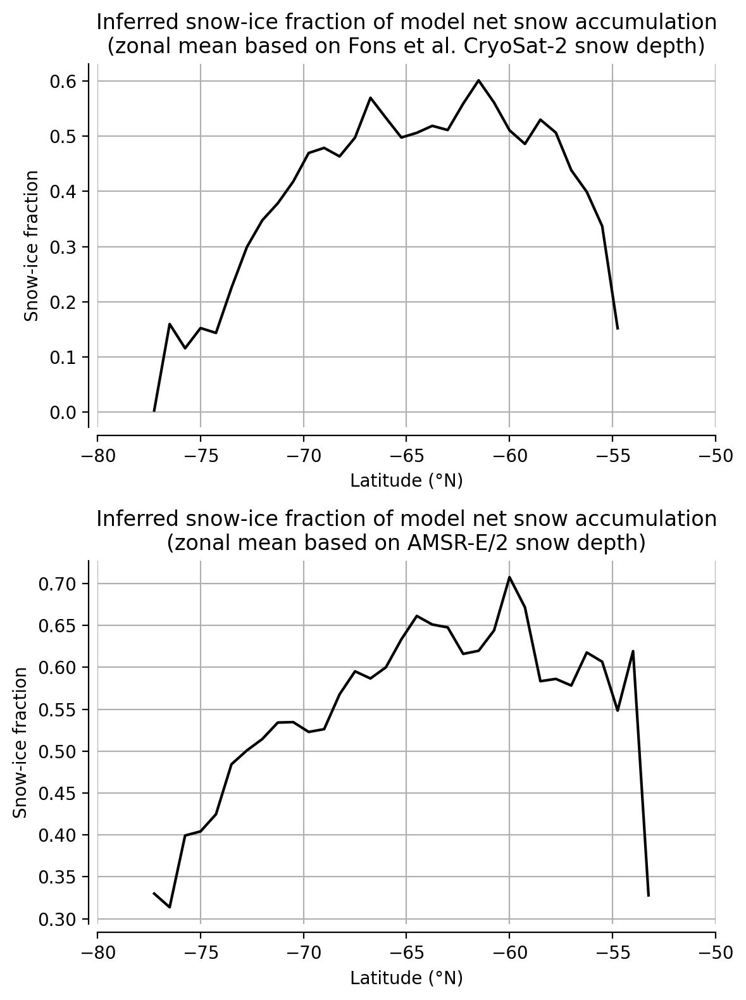

In [352]:
# calculate inferred loss to snow-ice formation, based on positive differences between spring (SON) remotely sensed snow depth
#    and simulated net snow accumulation (divided by simulated net snow accumulation)
model_fons_snow_ice_fract = (model_fons_diff_son.where(model_fons_diff_son >= 0.0) / model_snow_accum_son)
model_amsr_snow_ice_fract = (model_amsr_diff_son.where(model_amsr_diff_son >= 0.0) / model_snow_accum_son)

plt.figure(figsize=(6,8),facecolor='w',dpi=200)
plt.subplot(2,1,1)
model_fons_snow_ice_fract.mean(dim='lon').plot(c='k')
plt.grid()
plt.xlim([-80,-50])
plt.xlabel('Latitude (°N)')
plt.ylabel('Snow-ice fraction')
plt.title('Inferred snow-ice fraction of model net snow accumulation\n(zonal mean based on Fons et al. CryoSat-2 snow depth)')
drop_spines()
plt.subplot(2,1,2)
model_amsr_snow_ice_fract.mean(dim='lon').plot(c='k')
plt.grid()
plt.xlim([-80,-50])
plt.xlabel('Latitude (°N)')
plt.ylabel('Snow-ice fraction')
plt.title('Inferred snow-ice fraction of model net snow accumulation\n(zonal mean based on AMSR-E/2 snow depth)')
drop_spines()
plt.tight_layout()
plt.savefig(current_results_dir + 'model_snow_ice_fraction_inferred.pdf')

print('Spatial averages within areas of positive model-satellite differences:')
print('>> Snow-ice fraction, based on Fons et al. CryoSat-2 snow depth: {0:.2f}'\
      .format(model_fons_snow_ice_fract.weighted(era5_grid_areas_coarse).mean().compute().item()))
print('>> Snow-ice fraction, based on AMSR-E/2 snow depth: {0:.2f}'\
      .format(model_amsr_snow_ice_fract.weighted(era5_grid_areas_coarse).mean().compute().item()))

[########################################] | 100% Completed |  1min  8.3s


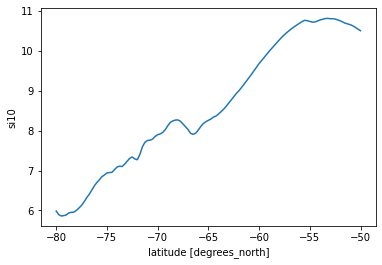

In [114]:
# exploratory plot of zonally-averaged ERA5 10-m wind speed vs. latitude (sample year of 2014)
with ProgressBar():
    era5['si10'].sel(time='2014').mean(dim=['time','lons']).plot()

### Snow buoy observations

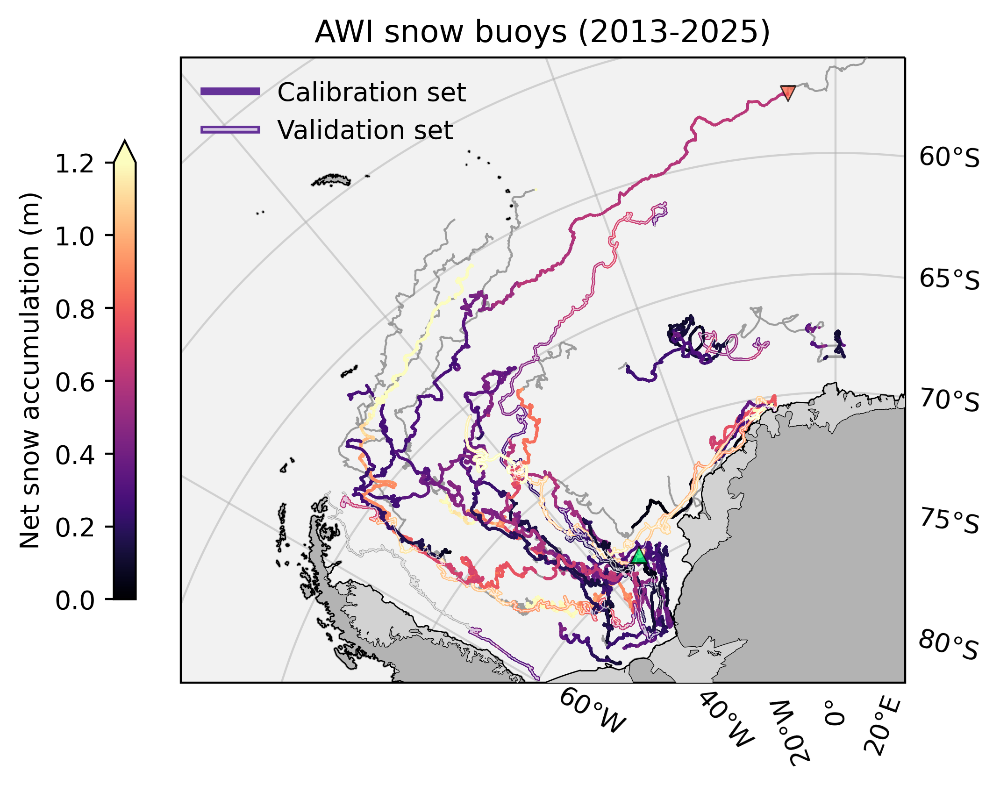

In [287]:
# map of AWI snow buoys
plt.figure(figsize=(6.25,6.5),facecolor='w',dpi=400)
plt.axes(projection=ccrs.SouthPolarStereo(central_longitude=0.0))
plt.gca().set_extent([-55,5,-77,-56],crs=ccrs.PlateCarree())
gl = plt.gca().gridlines(crs=ccrs.PlateCarree(),draw_labels={"bottom":"x","right":"y"},alpha=0.5)
# gl.right_labels = True
# gl.right_labels = True
gl.y_inline = False
plt.gca().add_feature(cfeature.OCEAN.with_scale('10m'),color='0.95',zorder=1)
plt.gca().add_feature(cfeature.LAND.with_scale('10m'),color='0.7',zorder=2)
plt.gca().coastlines(resolution='10m',linewidth=0.5,zorder=3)
ice_shelves = cartopy.feature.NaturalEarthFeature('physical','antarctic_ice_shelves_polys','10m')
ice_shelves_lines = cartopy.feature.NaturalEarthFeature('physical','antarctic_ice_shelves_lines','10m')
plt.gca().add_feature(ice_shelves,facecolor='0.825',edgecolor='none',zorder=4)
plt.gca().add_feature(ice_shelves_lines,facecolor='none',edgecolor='k',linestyle='-',linewidth=0.5,zorder=5)
for buoy_id in buoy_data.keys():
    plt.plot(buoy_data[buoy_id]['longitude (deg)'].values,buoy_data[buoy_id]['latitude (deg)'].values,
             c='0.5',lw=0.75,alpha=0.75,transform=ccrs.PlateCarree(),zorder=3)
    sct = plt.scatter(buoy_data[buoy_id]['longitude (deg)'].values,buoy_data[buoy_id]['latitude (deg)'].values,
                      c=buoy_data[buoy_id]['distance_to_initial_snow_interface'].values,vmin=0.0,vmax=1.2,
                      cmap='magma',s=1.25,linewidths=0,transform=ccrs.PlateCarree(),zorder=4)
    if buoy_id in buoy_names_validation_set:
        plt.plot(buoy_data[buoy_id]['longitude (deg)'].values,buoy_data[buoy_id]['latitude (deg)'].values,
                 c='w',lw=0.35,alpha=0.75,transform=ccrs.PlateCarree(),zorder=5)
    if buoy_id == '2014S9':
        first_valid_time = buoy_data[buoy_id]['distance_to_initial_snow_interface'].dropna(dim='time')['time'][0].values
        last_valid_time = buoy_data[buoy_id]['distance_to_initial_snow_interface'].dropna(dim='time')['time'][-1].values
        plt.scatter(buoy_data[buoy_id]['longitude (deg)'].sel(time=first_valid_time).values,
                    buoy_data[buoy_id]['latitude (deg)'].sel(time=first_valid_time).values,
                    s=40,marker='^',c='springgreen',edgecolors='k',linewidths=0.5,alpha=0.75,transform=ccrs.PlateCarree(),zorder=6)
        plt.scatter(buoy_data[buoy_id]['longitude (deg)'].sel(time=last_valid_time).values,
                    buoy_data[buoy_id]['latitude (deg)'].sel(time=last_valid_time).values,
                    s=35,marker='v',c='tomato',edgecolors='k',linewidths=0.5,alpha=0.75,transform=ccrs.PlateCarree(),zorder=6)
plt.colorbar(sct,ax=[plt.gca()],label='Net snow accumulation (m)',shrink=0.50,extend='max',pad=0.05,location='left')
invisible_lines = [Line2D([0],[0],lw=3,color='rebeccapurple'),
                   (Line2D([0],[0],lw=3,color='rebeccapurple'),Line2D([0],[0],lw=1,color='w',alpha=0.75))]
plt.legend(invisible_lines,['Calibration set','Validation set'],loc='upper left',frameon=False)
plt.title('AWI snow buoys (2013-2025)')
plt.savefig(current_results_dir + 'awi_snow_buoys.jpg',bbox_inches='tight')

In [3]:
parcels_input = xr.open_dataset(processed_model_output_dir_params + 'parcels_input.nc').load()
parcels_input['parcel_id'] = parcels_input['parcel_id'].astype(str)

In [ ]:
%matplotlib inline

from IPython.display import display, clear_output

c = arange(parcels_input['parcel_id'].size)/parcels_input['parcel_id'].size
random.shuffle(c)

fig = plt.figure(figsize=(6.25,6.5),facecolor='w',dpi=400)
ax = plt.axes(projection=ccrs.SouthPolarStereo(central_longitude=0.0))
ax.set_extent([-55,5,-77,-56],crs=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND.with_scale('110m'),color='0.7',zorder=2)

display(fig)
points = None
mo = 0

while True:
    # if points is not None:
    #     points.remove()
    this_parcels = parcels_input.sel(time=datetime(2013,7,1,0,0,0) + timedelta(days=int(30.5*mo)))
    points = ax.scatter(this_parcels['lon'].values,this_parcels['lat'].values,
                        s=15,c=c,vmin=0.0,vmax=1.0,
                        transform=ccrs.PlateCarree())
    ax.set_title(str(this_parcels['time'].values));
    clear_output(wait=True)
    display(fig)
    time.sleep(0.1)  # or plt.pause(1)
    # points.remove()    # remove points for next frame
    mo += 1

### *End of non-distributed code*

In [ ]:
# [KEEP THIS CELL!] end of block comment to exclude most of notebook from execution upon conversion to .py script

"""